# Homework #3 — Exploratory Data Analysis (Final Report)
**Team ID: 16** | Reddit, 7 AI communities: `r/singularity`, `r/ArtificialInteligence`, `r/aiwars`, `r/doomer`, `r/artificial`, `r/claude`, `r/AiChatGPT` | 2024-09-01 … 2025-05-31

In [49]:
WEEK1_HOURS = 4      
WEEK2_HOURS = 15
print(f"Time spent on this homework: {WEEK1_HOURS + WEEK2_HOURS} hours  (week 1: {WEEK1_HOURS} h, week 2: {WEEK2_HOURS} h)")

Time spent on this homework: 19 hours  (week 1: 4 h, week 2: 15 h)


## How to read this report
The report is a chain of **questions (Q1, Q2, …) → one chart per question → a short answer computed from the data**. Every chart is a separate figure with a title, named axes with units and a legend. The ten hypotheses from the intermediate report (H1–H10) are tested, six new ones are added (H11–H16), and one more is tested with a model (H17).

| Part | Story question | Hypotheses |
|---|---|---|
| 1 Overview | What do we have and how clean is it? | – |
| 2 Time | When is the AI debate loud, and what wakes it up? | H8, H10 |
| 3 Communities | Which communities argue, which inform? | H6, H11 |
| 4 People | Who writes? Do audiences overlap? Are there bots? | H7, H9, H13 |
| 5 Merge | Do posts and comments tell one consistent story? | H12 |
| 6 Language | How do communities talk, and about what? | H14, H15, H16 |
| 7 Thematic tests | Fatalism, religion, class conflict, "slop", proof of humanity | H1–H5 |
| 8 Modelling | Which topics does a topic model find? Can a classifier tell the communities apart? | H17 |
| 9 Summary | All verdicts in one table, limitations | – |
| 10 Export | Enriched table `3_16.csv` | – |

### Design rules (what we took from the course links)
* **data-to-viz / Visual Vocabulary:** ranking → sorted bars; distributions → ECDF and boxplots; two numeric variables → scatter of a sample (avoids over-plotting); time → lines with events; part-to-whole → 100 % stacked bars (no pies); text → bar charts of distinctive words, bigram network, word-correlation map — **no word clouds**; networks are limited to the strongest edges to avoid a "hairball".
* **Text mining tutorials (uc-r "Word Relationships", "Bag of Words"):** bag-of-words counts, TF-IDF, bigram counts / PMI, bigram network, pairwise word correlation (phi).
* **Colour (ColorBrewer, the palette tool from the course list):** *no gradients*. Continuous scales are replaced by **5–7 discrete classes** with a class legend.

| Role | Palette | Used for |
|---|---|---|
| 7 subreddits | ColorBrewer **Dark2** (+ different line style / marker as a second cue for colour-blind readers) | every per-community chart |
| other categories (post types, AI brands) | ColorBrewer **Paired** | so they are never confused with subreddit colours |
| magnitude (heat-maps) | ColorBrewer **BuGn**, 5 classes | counts, shares |
| above / below a reference | ColorBrewer **RdBu**, 7 classes (blue = below, red = above) | z-scores, ratios |
| two-way contrast | teal `#1b9e77` / orange `#d95f02` (both from Dark2) | with / without, mean / median |

In [50]:
%pip install -q vaderSentiment scipy networkx scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
import re, time, warnings, textwrap
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
import networkx as nx
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
warnings.filterwarnings("ignore")

# ---------------- colour system: ColorBrewer 2.0 palettes, discrete only ----------------
DARK2    = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#666666"]
PAIRED_D = ["#1f78b4", "#33a02c", "#e31a1c", "#ff7f00", "#6a3d9a", "#b15928"]      # dark half of Paired (6 brands)
PAIRED4  = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c"]                           # 4 categories (post types, groups)
SEQ5     = ["#edf8fb", "#b2e2e2", "#66c2a4", "#2ca25f", "#006d2c"]                # BuGn 5
DIV7     = ["#2166ac", "#67a9cf", "#d1e5f0", "#f7f7f7", "#fddbc7", "#ef8a62", "#b2182b"]   # RdBu 7 (blue low -> red high)
C1, C2, GREY, LGREY = "#1b9e77", "#d95f02", "#636363", "#bdbdbd"
NEG, NEU, POS = "#ef8a62", "#bdbdbd", "#67a9cf"

plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (10, 4.8), "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "axes.facecolor": "white", "axes.edgecolor": "#8c8c8c", "axes.grid": True, "grid.color": "#e8e8e8",
    "grid.linewidth": .8, "axes.spines.top": False, "axes.spines.right": False, "legend.fontsize": 8, "axes.axisbelow": True,
    "savefig.bbox": "tight"})

# ---------------- helpers: one chart = one figure = one legend ----------------
_q = [0]; CHARTS = []; RES = {}
def Q(text):
    _q[0] += 1; display(Markdown(f"#### Q{_q[0]}. {text}"))
def A(text): display(Markdown(f"> **Answer.** {text}"))
def VERDICT(h, text):
    RES[h] = text; display(Markdown(f"> **Verdict {h}.** {text}"))

def done(ax, title, xl, yl, ltitle=None, loc="best", outside=False, handles=None, fallback=None, ncol=1):
    """finish a chart: title, axis names, legend (mandatory), show"""
    assert len(ax.figure.axes) == 1, "one chart per figure"
    ax.set_title("\n".join(textwrap.wrap(title, 95)), loc="left"); ax.set_xlabel(xl); ax.set_ylabel(yl)
    if handles is None:
        handles = list(ax.get_legend_handles_labels()[0])
    if not handles and fallback:
        handles = [Patch(facecolor=fallback[0], edgecolor="none", label=fallback[1])]; outside = True
    assert handles, "chart without a legend: " + title
    kw = dict(title=ltitle, ncol=ncol, fontsize=8, title_fontsize=9, frameon=True, framealpha=1, edgecolor="#d0d0d0")
    if outside: ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left", **kw)
    else:       ax.legend(handles=handles, loc=loc, **kw)
    ax.figure.tight_layout(); CHARTS.append(title); plt.show()

def add_events(ax, d0, d1, events=None):
    first = True
    for d, lab in (events or EV_MAIN).items():
        t = pd.Timestamp(d)
        if d0 <= t <= d1:
            ax.axvline(t, color="#7f7f7f", ls="--", lw=.9, label="Candidate real-world event" if first else None); first = False
            ax.text(t, .98, " " + lab, rotation=90, va="top", ha="right", fontsize=7, color="#4d4d4d", transform=ax.get_xaxis_transform())

def lum(hexc):
    r, g, b = [int(hexc[i:i + 2], 16) for i in (1, 3, 5)]; return .299 * r + .587 * g + .114 * b
def class_labels(inner, f="{:g}"):
    labs = ["< " + f.format(inner[0])]
    labs += [f.format(a) + " – " + f.format(b) for a, b in zip(inner[:-1], inner[1:])]
    return labs + ["≥ " + f.format(inner[-1])]
def pick(colors, k):
    return [colors[i] for i in np.linspace(0, len(colors) - 1, k).round().astype(int)]
def qinner(vals, colors):
    v = np.asarray(vals, float); v = v[np.isfinite(v)]
    inner = np.quantile(v, np.linspace(0, 1, len(colors) + 1)[1:-1])
    inner = np.unique(np.round(inner, 2 if v.max() < 10 else (1 if v.max() < 100 else 0)))
    return inner, pick(colors, len(inner) + 1)
def class_heat(ax, M, inner, colors, f="{:g}", annot=None, xt=None, yt=None, xrot=0, xstep=1, font=7, ann_vals=None):
    """discrete-class heat-map (no gradient). Returns legend handles."""
    A_ = M.to_numpy(float); V_ = A_ if ann_vals is None else ann_vals.to_numpy(float); codes = np.ma.masked_where(np.isnan(A_), np.digitize(A_, inner))
    ax.pcolormesh(codes, cmap=ListedColormap(colors), vmin=-.5, vmax=len(colors) - .5, edgecolors="white", linewidth=.6)
    ax.invert_yaxis(); ax.grid(False)
    xt = list(M.columns) if xt is None else xt; yt = list(M.index) if yt is None else yt
    ax.set_xticks(np.arange(len(xt))[::xstep] + .5); ax.set_xticklabels(np.array(xt, dtype=object)[::xstep], rotation=xrot, ha="right" if xrot else "center")
    ax.set_yticks(np.arange(len(yt)) + .5); ax.set_yticklabels(yt)
    if annot:
        for i in range(A_.shape[0]):
            for j in range(A_.shape[1]):
                if not np.isnan(A_[i, j]):
                    ax.text(j + .5, i + .5, annot.format(V_[i, j]), ha="center", va="center", fontsize=font,
                            color="white" if lum(colors[int(codes[i, j])]) < 140 else "black")
    return [Patch(facecolor=c, edgecolor="#9a9a9a", label=l) for c, l in zip(colors, class_labels(inner, f))]

def stacked(ax, pv, colors, horizontal=False, pct=False, label=lambda c: f"r/{c}", width=.75):
    P = pv.div(pv.sum(1), axis=0) * 100 if pct else pv
    pos = np.arange(len(P)); base = np.zeros(len(P))
    for col in P.columns:
        v = P[col].to_numpy(float)
        (ax.barh(pos, v, left=base, color=colors[col], label=label(col), height=width) if horizontal
         else ax.bar(pos, v, bottom=base, color=colors[col], label=label(col), width=width))
        base += v
    return pos

def sub_handles(subs, title=None):
    return [Patch(facecolor=PAL[s], label=f"r/{s}") for s in subs]
def ecdf(ax, v, **kw):
    v = np.sort(np.asarray(v, float)); v = v[np.isfinite(v)]
    if len(v) > 1500: v = np.quantile(v, np.linspace(0, 1, 1200))
    ax.plot(v, np.linspace(0, 1, len(v)), drawstyle="steps-post", **kw)
def fmt_int(x): return f"{x:,.0f}"

## 0. Data loading
The two cleaned CSV files from HW#2 are read **column by column** (the raw files are very wide). If a column is missing in your file it is simply skipped, and the charts that depend on it are skipped with a message.

In [52]:
COMMENTS_CSV = "cleaned_combined_reddit_comments.csv"
SUBS_CSV     = "cleaned_combined_reddit_submissions.csv"
START, END = pd.Timestamp("2024-09-01"), pd.Timestamp("2025-06-01")      # end is exclusive

C_WANT = ["id", "author", "body", "created_utc", "subreddit", "score", "link_id", "parent_id", "controversiality"]
S_WANT = ["id", "author", "title", "selftext", "created_utc", "subreddit", "score", "upvote_ratio", "num_comments",
          "url", "domain", "total_awards_received", "over_18"]
read_kw = dict(low_memory=False, lineterminator="\n", on_bad_lines="skip", encoding="utf-8")

def load(path, wanted):
    have = pd.read_csv(path, nrows=0, **read_kw).columns
    return pd.read_csv(path, usecols=[c for c in wanted if c in have], **read_kw)
def to_dt(s):
    if pd.api.types.is_numeric_dtype(s): return pd.to_datetime(s, unit="s")
    return pd.to_datetime(s, errors="coerce", utc=True).dt.tz_localize(None)

t0 = time.time()
if "cm" not in globals():                               # heavy part runs once per kernel
    cm = load(COMMENTS_CSV, C_WANT).drop_duplicates("id")
    sb = load(SUBS_CSV, S_WANT).drop_duplicates("id")
    for d in (cm, sb):
        d["dt"] = to_dt(d["created_utc"]); d.drop(columns="created_utc", inplace=True)
    cm = cm[(cm.dt >= START) & (cm.dt < END)].reset_index(drop=True)
    sb = sb[(sb.dt >= START) & (sb.dt < END)].reset_index(drop=True)
    for d in (cm, sb):
        d["date"] = d["dt"].dt.floor("D"); d["month"] = d["dt"].dt.to_period("M").dt.to_timestamp()
        d["hour"] = d["dt"].dt.hour;        d["weekday"] = d["dt"].dt.dayofweek
print(f"loaded in {time.time()-t0:.0f}s | comments {len(cm):,} | submissions {len(sb):,}")

loaded in 90s | comments 1,717,150 | submissions 77,504


In [53]:
# ---- flags are computed BEFORE missing values are filled ----
sb["selftext_missing"] = sb["selftext"].isna() if "selftext" in sb else True
for col in ("title", "selftext"):
    sb[col] = sb[col].fillna("") if col in sb else ""
sb["selftext_removed"] = sb["selftext"].isin(["[removed]", "[deleted]"])
sb["deleted_author"] = sb["author"].eq("[deleted]")
cm["body"] = cm["body"].fillna("")
cm["deleted_author"] = cm["author"].eq("[deleted]")
cm["removed_body"] = cm["body"].isin(["[removed]", "[deleted]", ""])
cm["n_words"] = cm["body"].str.count(r"\S+")
sb["title_words"] = sb["title"].str.count(r"\S+")

# ---- domain and post type (text / image / reddit video / external link) ----
host = sb["url"].fillna("").astype(str).str.extract(r"^https?://([^/]+)")[0].str.lower().str.replace(r"^www\.", "", regex=True)
sb["dom"] = (sb["domain"].astype(str).str.lower() if "domain" in sb else host).where(lambda s: s.notna() & (s != "nan"), host).fillna("unknown")
sb["post_type"] = np.select([sb.dom.eq("i.redd.it") | sb.dom.str.contains("imgur"), sb.dom.eq("v.redd.it"),
                             sb.dom.str.startswith("self.") | sb.dom.isin(["reddit.com", "old.reddit.com", "np.reddit.com"])],
                            ["image", "video", "text"], "external link")
sb["has_q"] = sb["title"].str.contains(r"\?", regex=True)

valid = cm[~cm.removed_body]                       # non-removed comments (used for text)
order = (cm["subreddit"].value_counts().add(sb["subreddit"].value_counts(), fill_value=0).sort_values(ascending=False).index.tolist())
PAL = dict(zip(order, DARK2)); MK = dict(zip(order, "osD^vP*")); LS = dict(zip(order, ["-", "--", "-.", ":", "-", "--", "-."]))
BIG = [s for s in order if (cm.subreddit == s).sum() >= 20000]       # communities big enough for fine-grained charts
print("subreddits:", order, "| big:", BIG)

subreddits: ['singularity', 'aiwars', 'ArtificialInteligence', 'artificial', 'doomer', 'AiChatGPT', 'claude'] | big: ['singularity', 'aiwars', 'ArtificialInteligence', 'artificial', 'doomer']


## 1. Overview: what do we have?

In [54]:
ov = pd.DataFrame({
    "records": [len(sb), len(cm)], "first (UTC)": [sb.dt.min(), cm.dt.min()], "last (UTC)": [sb.dt.max(), cm.dt.max()],
    "days covered": [sb.date.nunique(), cm.date.nunique()], "subreddits": [sb.subreddit.nunique(), cm.subreddit.nunique()],
    "unique authors": [sb.author.nunique(), cm.author.nunique()]}, index=["submissions", "comments"]).T
display(ov)
ps = pd.DataFrame({"submissions": sb.subreddit.value_counts(), "comments": cm.subreddit.value_counts()}).reindex(order)
ps["comments per submission"] = (ps.comments / ps.submissions).round(1)
display(ps)

,submissions,comments
records,77504,1717150
first (UTC),2024-09-01 00:11:05,2024-09-01 00:00:36
last (UTC),2025-05-31 23:57:36,2025-05-31 23:59:56
days covered,273,273
subreddits,7,7
unique authors,36481,167978


,submissions,comments,comments per submission
subreddit,,,
singularity,24569,931759,37.9
aiwars,8043,414475,51.5
ArtificialInteligence,29897,248224,8.3
artificial,11293,98099,8.7
doomer,3073,23293,7.6
AiChatGPT,500,1140,2.3
claude,129,160,1.2


#### Q1. How many submissions were posted each month, and which communities drive the volume?

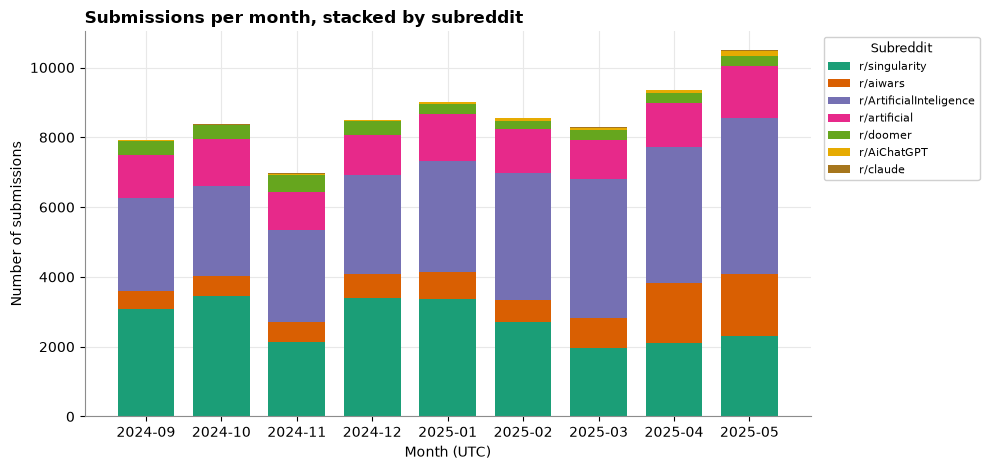

> **Answer.** Submissions grow from 7,919 (2024-09) to 10,512 (2025-05); the busiest month is 2025-05. r/ArtificialInteligence alone contributes 39% of all posts.

In [55]:
Q("How many submissions were posted each month, and which communities drive the volume?")
pv = sb.groupby(["month", "subreddit"]).size().unstack(fill_value=0).reindex(columns=order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.8)); pos = stacked(ax, pv, PAL)
ax.set_xticks(pos); ax.set_xticklabels(pv.index.strftime("%Y-%m"))
done(ax, "Submissions per month, stacked by subreddit", "Month (UTC)", "Number of submissions", ltitle="Subreddit", outside=True)
t = pv.sum(1); A(f"Submissions grow from {t.iloc[0]:,.0f} ({t.index[0]:%Y-%m}) to {t.iloc[-1]:,.0f} ({t.index[-1]:%Y-%m}); the busiest month is {t.idxmax():%Y-%m}. "
  f"r/{pv.sum().idxmax()} alone contributes {pv.sum().max()/pv.values.sum()*100:.0f}% of all posts.")

#### Q2. Is the growth the same for comments? (comments per month)

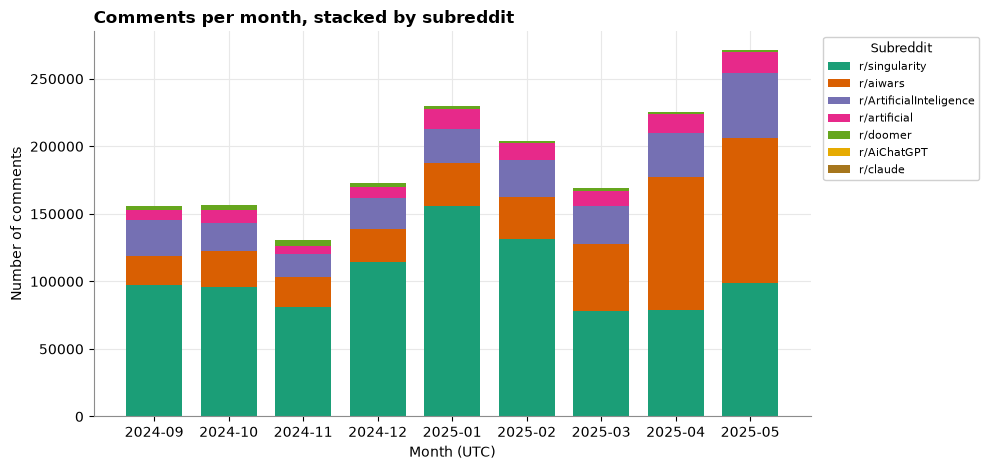

> **Answer.** Comments go from 156,047 to 271,551 (1.7×), while submissions grow 1.3×: discussion grows faster than posting. Lowest month: 2024-11, highest: 2025-05.

In [56]:
Q("Is the growth the same for comments? (comments per month)")
pvc = cm.groupby(["month", "subreddit"]).size().unstack(fill_value=0).reindex(columns=order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.8)); pos = stacked(ax, pvc, PAL)
ax.set_xticks(pos); ax.set_xticklabels(pvc.index.strftime("%Y-%m"))
done(ax, "Comments per month, stacked by subreddit", "Month (UTC)", "Number of comments", ltitle="Subreddit", outside=True)
t = pvc.sum(1); A(f"Comments go from {t.iloc[0]:,.0f} to {t.iloc[-1]:,.0f} ({t.iloc[-1]/t.iloc[0]:.1f}×), while submissions grow {pv.sum(1).iloc[-1]/pv.sum(1).iloc[0]:.1f}×: "
  f"discussion grows faster than posting. Lowest month: {t.idxmin():%Y-%m}, highest: {t.idxmax():%Y-%m}.")

#### Q3. How is the dataset split between communities: do posts and comments have the same shares?

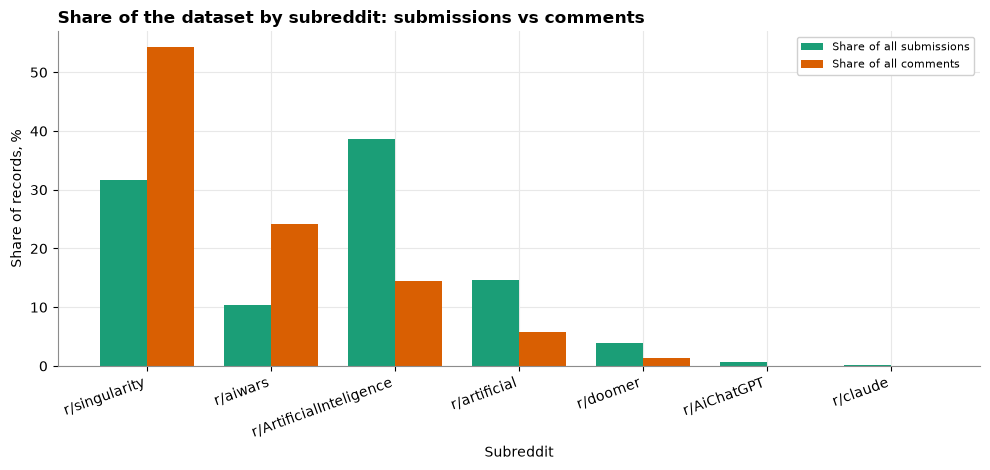

> **Answer.** r/singularity has 54% of comments but only 32% of posts (highly talkative); r/ArtificialInteligence is the opposite (39% of posts vs 14% of comments).

In [57]:
Q("How is the dataset split between communities: do posts and comments have the same shares?")
# Виправлено логіку reindex та усунено попередження
sh = pd.DataFrame({
    "Submissions": sb['subreddit'].value_counts(normalize=True) * 100, 
    "Comments": cm['subreddit'].value_counts(normalize=True) * 100
}).reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(sh))
w = 0.38

ax.bar(x - w/2, sh['Submissions'], w, color=C1, label="Share of all submissions")
ax.bar(x + w/2, sh['Comments'], w, color=C2, label="Share of all comments")
ax.set_xticks(x)
ax.set_xticklabels([f"r/{s}" for s in sh.index], rotation=20, ha="right")

done(ax, "Share of the dataset by subreddit: submissions vs comments", "Subreddit", "Share of records, %", loc="upper right")

# Виправлено логіку висновків, щоб уникнути помилок доступу до індексів
diff = sh['Comments'] - sh['Submissions']
max_diff_sub = diff.idxmax()
min_diff_sub = diff.idxmin()

A(f"r/{max_diff_sub} has {sh.loc[max_diff_sub, 'Comments']:.0f}% of comments but only {sh.loc[max_diff_sub, 'Submissions']:.0f}% of posts (highly talkative); "
  f"r/{min_diff_sub} is the opposite ({sh.loc[min_diff_sub, 'Submissions']:.0f}% of posts vs {sh.loc[min_diff_sub, 'Comments']:.0f}% of comments).")

#### Q4. How clean is the data? Which fields are missing and how much content was removed or deleted?

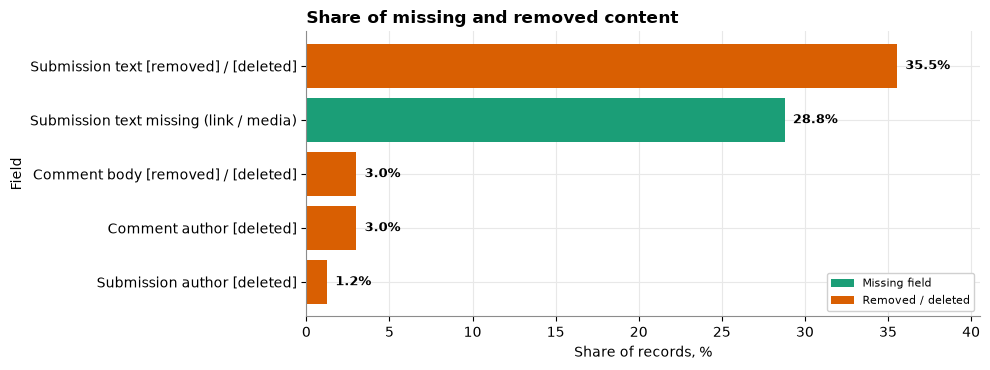

> **Answer.** The biggest problem is removed submission text: 35.5% of posts were removed or deleted by a moderator or the author. Another 28.8% of posts have no text by design (image, video or link posts). Comments are much cleaner: 3.0% removed bodies and 3.0% deleted authors. Removed or deleted items are excluded from the text analysis.

In [58]:
Q("How clean is the data? Which fields are missing and how much content was removed or deleted?")
q = pd.Series({
    "Submission text missing (link / media)": sb['selftext_missing'].mean() * 100,
    "Submission text [removed] / [deleted]": sb['selftext_removed'].mean() * 100,
    "Submission author [deleted]": sb['deleted_author'].mean() * 100,
    "Comment author [deleted]": cm['deleted_author'].mean() * 100,
    "Comment body [removed] / [deleted]": cm['removed_body'].mean() * 100
}).sort_values()

kind = ["Missing field" if "missing" in i else "Removed / deleted by user or moderator" for i in q.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(q.index, q.values, color=[C1 if k == "Missing field" else C2 for k in kind])

# Виправлено вирівнювання підписів на графіку, щоб вони не вилазили за межі
for i, v in enumerate(q.values): 
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9, fontweight='bold')

# Розширення ліміту осі X, щоб текст не обрізався
ax.set_xlim(0, q.max() + 5)

done(ax, "Share of missing and removed content", "Share of records, %", "Field",
     handles=[Patch(facecolor=C1, label="Missing field"), Patch(facecolor=C2, label="Removed / deleted")], loc="lower right")

A(f"The biggest problem is removed submission text: {q['Submission text [removed] / [deleted]']:.1f}% of posts were removed or deleted by a moderator or the author. "
  f"Another {q['Submission text missing (link / media)']:.1f}% of posts have no text by design (image, video or link posts). "
  f"Comments are much cleaner: {q['Comment body [removed] / [deleted]']:.1f}% removed bodies and {q['Comment author [deleted]']:.1f}% deleted authors. "
  "Removed or deleted items are excluded from the text analysis.")

## 2. Time: when is the AI debate loud, and what wakes it up? (H8, H10)
**H8.** Model releases, major news and awards cause volume peaks, and different events excite different communities. **H10.** Daily rhythm reveals the audience geography.
Dashed lines are real-world AI events (dates checked against the public announcements). A peak that follows an event is a correlation, not proof of causation.

In [59]:
EVENTS = {"2024-09-12": "OpenAI o1-preview", "2024-10-08": "Nobel Physics (AI)", "2024-10-22": "Claude 3.5 Sonnet (new)",
          "2024-12-09": "Sora released", "2024-12-20": "OpenAI o3 announced", "2025-01-20": "DeepSeek-R1",
          "2025-01-27": "DeepSeek app #1 / Nvidia drop", "2025-02-24": "Claude 3.7 Sonnet", "2025-02-27": "GPT-4.5",
          "2025-03-25": "GPT-4o images / Gemini 2.5", "2025-04-05": "Llama 4", "2025-04-16": "o3 / o4-mini",
          "2025-05-20": "Google I/O", "2025-05-22": "Claude 4"}
EV_MAIN = {k: EVENTS[k] for k in ["2024-10-22", "2024-12-20", "2025-01-20", "2025-02-24", "2025-03-25", "2025-05-22"]}

idx_days = pd.date_range(START, END - pd.Timedelta(days=1))
daily_c = cm.groupby(["date", "subreddit"]).size().unstack(fill_value=0).reindex(index=idx_days, columns=order, fill_value=0)
tot = daily_c.sum(axis=1)
med = tot.rolling(28, center=True, min_periods=7).median()
mad = (tot - med).abs().rolling(28, center=True, min_periods=7).median()
zrob = 0.6745 * (tot - med) / mad.replace(0, np.nan)
spikes = zrob[zrob > 3.5].index
print("Anomalous days:", [d.strftime("%Y-%m-%d") for d in spikes] or "none")

Anomalous days: ['2025-01-27', '2025-01-28', '2025-05-21']


#### Q5. How does daily activity develop in each community (7-day mean, log scale)?

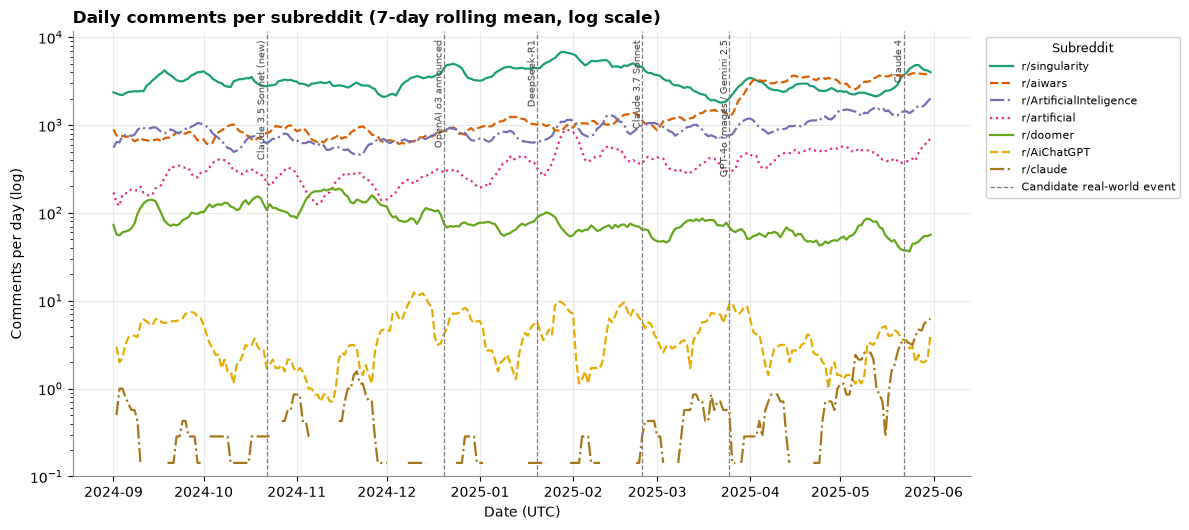

> **Answer.** Average daily comments: r/singularity 3,395, r/aiwars 1,487, r/ArtificialInteligence 893, r/artificial 353. The two smallest communities are tiny (r/claude 0.7 per day), so their statistics are noisy.

In [60]:
Q("How does daily activity develop in each community (7-day mean, log scale)?")
d7 = daily_c.rolling(7, min_periods=1).mean().replace(0, np.nan)
fig, ax = plt.subplots(figsize=(12, 5.4))
for s in order: ax.plot(d7.index, d7[s], color=PAL[s], ls=LS[s], lw=1.6, label=f"r/{s}")
ax.set_yscale("log"); ax.set_ylim(bottom=.1); add_events(ax, START, END)
done(ax, "Daily comments per subreddit (7-day rolling mean, log scale)", "Date (UTC)", "Comments per day (log)", ltitle="Subreddit", outside=True)
m = d7.mean(); A(f"Average daily comments: " + ", ".join(f"r/{s} {m[s]:,.0f}" for s in order[:4]) + f". The two smallest communities are tiny (r/{order[-1]} {m[order[-1]]:.1f} per day), so their statistics are noisy.")

#### Q6. Are there anomalous days in total activity, and do they match real-world events?

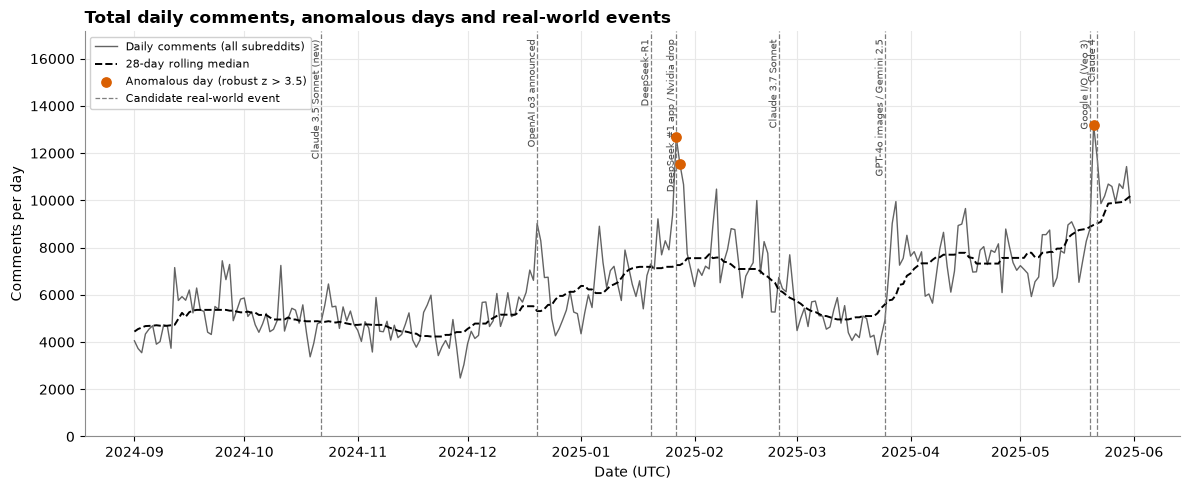

> **Answer.** Anomalous days: 2025-01-27 → DeepSeek app #1 / Nvidia drop (27 Jan, +0 d); 2025-01-28 → DeepSeek app #1 / Nvidia drop (27 Jan, +1 d); 2025-05-21 → Google I/O (20 May, +1 d). The January cluster is the **DeepSeek shock**: it comes one week after the R1 release, when the DeepSeek app topped the app stores and Nvidia shares fell. The May spike follows **Google I/O** (Veo 3 video model); Claude 4 came one day later and produced no outlier of its own. The words of these days (next question) confirm both matches.

In [61]:
Q("Are there anomalous days in total activity, and do they match real-world events?")
EV18 = {k: v for k, v in EV_MAIN.items() if k != "2025-05-22"}
EV18.update({"2025-01-27": "DeepSeek #1 app / Nvidia drop", "2025-05-20": "Google I/O (Veo 3)", "2025-05-22": "Claude 4"})
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(tot.index, tot.values, color=GREY, lw=1, label="Daily comments (all subreddits)")
ax.plot(med.index, med.values, color="black", ls="--", lw=1.4, label="28-day rolling median")
ax.scatter(spikes, tot[spikes], s=45, color=C2, zorder=5, label="Anomalous day (robust z > 3.5)")
ax.set_ylim(0, tot.max() * 1.3); add_events(ax, START, END, EV18)
done(ax, "Total daily comments, anomalous days and real-world events", "Date (UTC)", "Comments per day", loc="upper left")
def nearest_event(d, tol=3):
    """closest event within ±tol days; an event on or before the day wins a tie"""
    c = [((0 if t <= d else 1), abs((t - d).days), n, t) for t, n in ((pd.Timestamp(k), v) for k, v in EVENTS.items()) if abs((t - d).days) <= tol]
    return min(c) if c else None
lines = []
for d in spikes:
    e = nearest_event(d); lines.append(f"{d:%Y-%m-%d} → " + (f"{e[2]} ({e[3]:%d %b}, {(d - e[3]).days:+d} d)" if e else "no listed event"))
A("Anomalous days: " + "; ".join(lines) + ". The January cluster is the **DeepSeek shock**: it comes one week after the R1 release, when the DeepSeek app topped the "
  "app stores and Nvidia shares fell. The May spike follows **Google I/O** (Veo 3 video model); Claude 4 came one day later and produced no outlier of its own. "
  "The words of these days (next question) confirm both matches.")

#### Q7. What was being said on the anomalous days? (words and phrases over-represented compared with all other days)

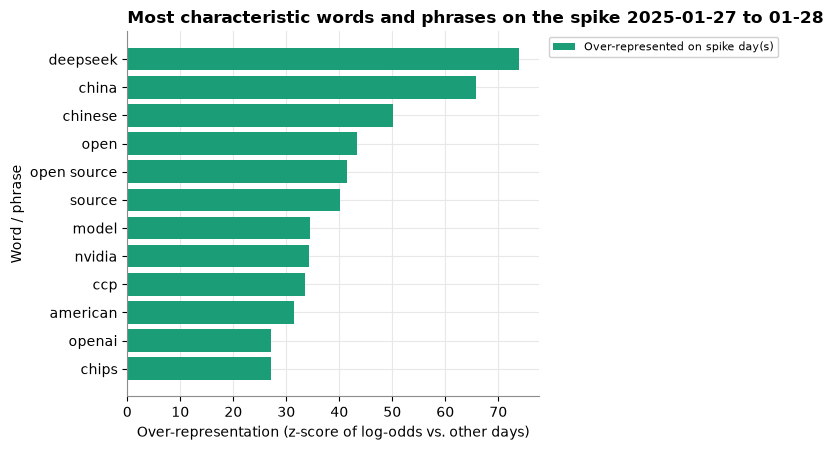

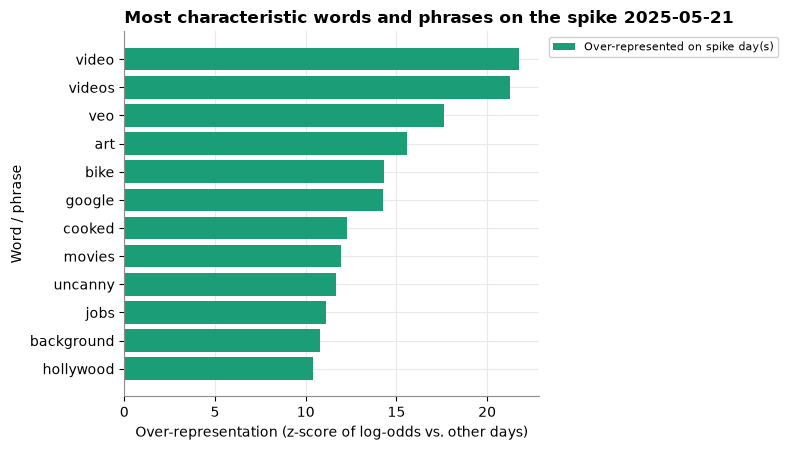

> **Answer.** Top terms per spike: **2025-01-27 to 01-28**: deepseek, china, chinese, open, open source; **2025-05-21**: video, videos, veo, art, bike. January: *deepseek, china, open source, nvidia, chips* — the DeepSeek shock. May: *video, veo, google, movies, hollywood* — the viral Veo 3 videos shown at Google I/O. The content of the spikes matches the news, which supports H8.

In [62]:
Q("What was being said on the anomalous days? (words and phrases over-represented compared with all other days)")
ev = []
for d in sorted(spikes):
    if ev and (d - ev[-1][1]).days <= 1: ev[-1][1] = d
    else: ev.append([d, d])
STOPW = set(ENGLISH_STOP_WORDS) | set("""like just don dont doesn isn aren wasn didn won wouldn couldn shouldn people think know say says said want need really
even still make made way thing things going well good lot https http www com reddit amp gt im ive thats youre theyre cant""".split())
TOK = r"(?u)\b[a-z][a-z']{2,}\b"
def spike_terms(mask, k=12):
    a = valid.loc[mask, "body"]; a = a.sample(min(len(a), 60000), random_state=0).str.lower()
    b = valid.loc[~mask, "body"]; b = b.sample(min(len(b), 120000), random_state=0).str.lower()
    cv = CountVectorizer(ngram_range=(1, 2), stop_words=list(STOPW), token_pattern=TOK, min_df=5, max_features=80000)
    X = cv.fit_transform(pd.concat([a, b])); na = len(a)
    ca = np.asarray(X[:na].sum(0)).ravel(); cb = np.asarray(X[na:].sum(0)).ravel(); al = .5
    lo = np.log((ca + al) / (ca.sum() - ca + al)) - np.log((cb + al) / (cb.sum() - cb + al))
    z = lo / np.sqrt(1 / (ca + al) + 1 / (cb + al)); z[ca < 20] = -99
    ix = np.argsort(z)[::-1][:k][::-1]; return pd.Series(z[ix], index=np.array(cv.get_feature_names_out())[ix])
SPIKE_WORDS = {}
for s_, e_ in ev[:4]:
    tt = spike_terms((valid.date >= s_) & (valid.date <= e_)); lab = f"{s_:%Y-%m-%d}" if s_ == e_ else f"{s_:%Y-%m-%d} to {e_:%m-%d}"
    SPIKE_WORDS[lab] = tt
    fig, ax = plt.subplots(figsize=(8, 4.6)); ax.barh(tt.index, tt.values, color=C1)
    done(ax, f"Most characteristic words and phrases on the spike {lab}", "Over-representation (z-score of log-odds vs. other days)", "Word / phrase",
         fallback=(C1, "Over-represented on spike day(s)"), loc="lower right")
A("Top terms per spike: " + "; ".join(f"**{k}**: " + ", ".join(v.index[::-1][:5]) for k, v in SPIKE_WORDS.items()) + ". January: *deepseek, china, open source, nvidia, chips* — the DeepSeek shock. May: *video, veo, google, movies, hollywood* — "
  "the viral Veo 3 videos shown at Google I/O. The content of the spikes matches the news, which supports H8.")

#### Q8. Which communities react to which events? (volume in the 3 days after an event vs. the 14 days before)

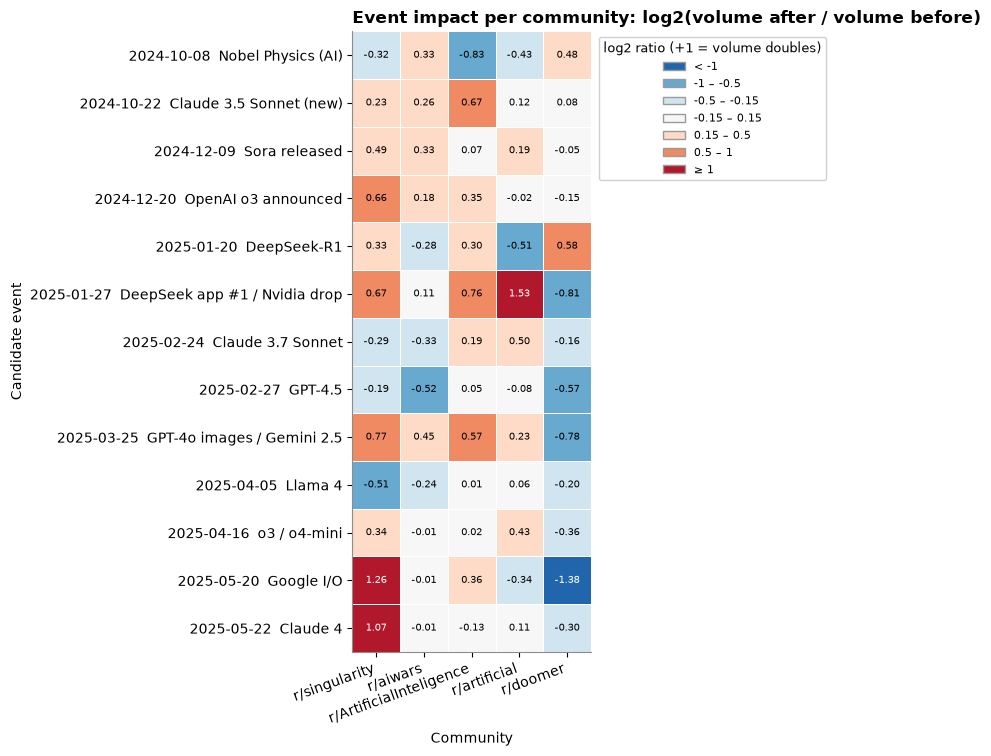

> **Answer.** Strongest reactions: *DeepSeek app #1 / Nvidia drop* in r/artificial (2.9×); *Google I/O* in r/singularity (2.4×); *Claude 4* in r/singularity (2.1×). The same event lifts one community and leaves another flat, so the audiences care about different news. r/doomer falls after 8 of 13 events: it does not follow product news at all. Note: Google I/O (20 May) and Claude 4 (22 May) are two days apart, so their windows overlap and their effects cannot be separated.

In [63]:
Q("Which communities react to which events? (volume in the 3 days after an event vs. the 14 days before)")
rows = {}
for d, n in EVENTS.items():
    t = pd.Timestamp(d)
    if t - pd.Timedelta(days=14) < START or t + pd.Timedelta(days=2) >= END: continue
    after = daily_c.loc[t:t + pd.Timedelta(days=2), BIG].mean(); before = daily_c.loc[t - pd.Timedelta(days=14):t - pd.Timedelta(days=1), BIG].median()
    rows[f"{d}  {n}"] = np.log2((after + 1) / (before + 1))
imp = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(8.5, .42 * len(imp) + 2.2))
hd = class_heat(ax, imp, [-1, -.5, -.15, .15, .5, 1], DIV7, f="{:g}", annot="{:.2f}", xt=[f"r/{s}" for s in imp.columns], xrot=20)
done(ax, "Event impact per community: log2(volume after / volume before)", "Community", "Candidate event", ltitle="log2 ratio (+1 = volume doubles)", outside=True, handles=hd)
st = imp.stack().sort_values(ascending=False).head(3)
A("Strongest reactions: " + "; ".join(f"*{i[0][12:]}* in r/{i[1]} ({2**v:.1f}×)" for i, v in st.items()) + ". The same event lifts one community and leaves another flat, so the audiences care about different news. "
  f"r/doomer falls after {(imp['doomer'] < -.15).sum() if 'doomer' in imp else 0} of {len(imp)} events: it does not follow product news at all. "
  "Note: Google I/O (20 May) and Claude 4 (22 May) are two days apart, so their windows overlap and their effects cannot be separated.")
RES["H8"] = f"anomalous days: {', '.join(d.strftime('%Y-%m-%d') for d in spikes) or 'none'}; strongest reaction {st.index[0][0][12:]} in r/{st.index[0][1]} ({2**st.iloc[0]:.1f}x)"

#### Q9. Do the communities rise and fall together? (weekly volume, standardised within each community)

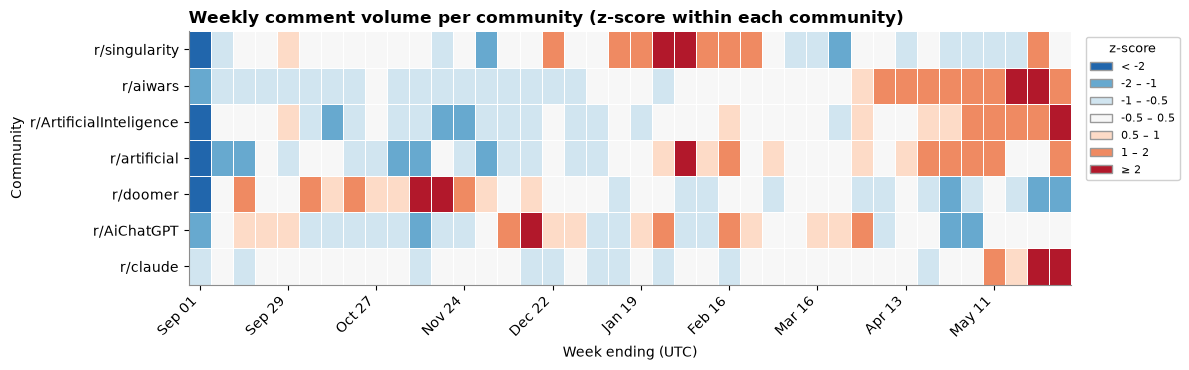

> **Answer.** The most synchronised pair is r/aiwars – r/ArtificialInteligence (weekly correlation 0.74); the least: r/aiwars – r/doomer (-0.49). Most communities are loudest in spring 2025, while r/doomer peaks in autumn 2024 and fades later — it lives on its own rhythm. The rows of r/AiChatGPT and r/claude are based on very few comments and are noisy.

In [64]:
Q("Do the communities rise and fall together? (weekly volume, standardised within each community)")
wk = daily_c.resample("W").sum(); zz = ((wk - wk.mean()) / wk.std()).T
fig, ax = plt.subplots(figsize=(12, 3.8))
hd = class_heat(ax, zz, [-2, -1, -.5, .5, 1, 2], DIV7, f="{:g}", xt=[d.strftime("%b %d") for d in zz.columns], yt=[f"r/{s}" for s in zz.index], xrot=45, xstep=4)
done(ax, "Weekly comment volume per community (z-score within each community)", "Week ending (UTC)", "Community", ltitle="z-score", outside=True, handles=hd)
cw = wk[BIG].corr(); cc = pd.Series({(a, b): cw.loc[a, b] for i, a in enumerate(BIG) for b in BIG[i + 1:]}).sort_values(ascending=False)
A(f"The most synchronised pair is r/{cc.index[0][0]} – r/{cc.index[0][1]} (weekly correlation {cc.iloc[0]:.2f}); the least: r/{cc.index[-1][0]} – r/{cc.index[-1][1]} ({cc.iloc[-1]:.2f}). "
  "Most communities are loudest in spring 2025, while r/doomer peaks in autumn 2024 and fades later — it lives on its own rhythm. "
  "The rows of r/AiChatGPT and r/claude are based on very few comments and are noisy.")

#### Q10. Is there a weekly rhythm in total activity? (calendar view: comments per day)

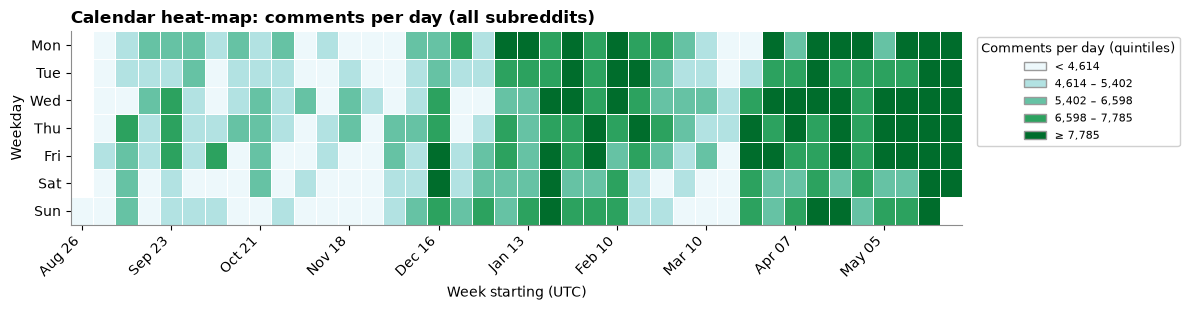

> **Answer.** Busiest weekday: Thu (6,713/day), quietest: Sat (5,654/day).

In [65]:
Q("Is there a weekly rhythm in total activity? (calendar view: comments per day)")
cal = pd.DataFrame({"v": tot}); first_mon = cal.index.min() - pd.Timedelta(days=cal.index.min().dayofweek)
cal["wk"] = (cal.index - first_mon).days // 7; cal["wd"] = cal.index.dayofweek
piv = cal.pivot(index="wd", columns="wk", values="v")
inner, cols = qinner(piv.values, SEQ5)
fig, ax = plt.subplots(figsize=(12, 3.2))
hd = class_heat(ax, piv, inner, cols, f="{:,.0f}", xt=[(first_mon + pd.Timedelta(weeks=int(w))).strftime("%b %d") for w in piv.columns],
                yt=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], xrot=45, xstep=4)
done(ax, "Calendar heat-map: comments per day (all subreddits)", "Week starting (UTC)", "Weekday", ltitle="Comments per day (quintiles)", outside=True, handles=hd)
wdm = tot.groupby(tot.index.dayofweek).mean(); A(f"Busiest weekday: {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][wdm.idxmax()]} ({wdm.max():,.0f}/day), quietest: {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][wdm.idxmin()]} ({wdm.min():,.0f}/day).")

#### Q11. When during the day is each community active? (H10: share of a community's comments by hour of day, UTC)

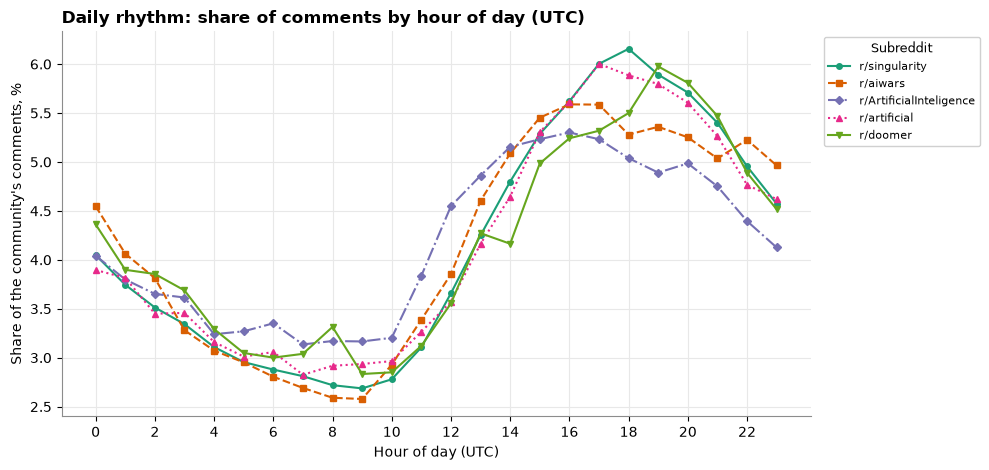

> **Verdict H10.** peak hour (UTC) per community: r/singularity 18h, r/aiwars 16h, r/ArtificialInteligence 16h, r/artificial 17h, r/doomer 19h; quietest around 9h UTC. Activity peaks at 16–19 UTC (midday–afternoon in the US, evening in Europe) and is lowest at 8–10 UTC (night in the Americas, morning in Europe) → supported: the rhythm points to a mostly North-American audience with a European share.

In [66]:
Q("When during the day is each community active? (H10: share of a community's comments by hour of day, UTC)")
hp = cm.groupby(["subreddit", "hour"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0); hp = hp.div(hp.sum(1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ax.plot(hp.columns, hp.loc[s], color=PAL[s], ls=LS[s], marker=MK[s], ms=4, lw=1.5, label=f"r/{s}")
ax.set_xticks(range(0, 24, 2))
done(ax, "Daily rhythm: share of comments by hour of day (UTC)", "Hour of day (UTC)", "Share of the community's comments, %", ltitle="Subreddit", outside=True)
pk = hp.loc[BIG].idxmax(axis=1); qt = hp.loc[BIG].idxmin(axis=1)
VERDICT("H10", f"peak hour (UTC) per community: " + ", ".join(f"r/{s} {pk[s]}h" for s in BIG) + f"; quietest around {int(qt.mode().iloc[0])}h UTC. Activity peaks at 16–19 UTC (midday–afternoon in the US, evening in Europe) and is lowest at 8–10 UTC (night in the Americas, morning in Europe) → supported: the rhythm points to a mostly North-American audience with a European share.")

#### Q12. Which hours and weekdays are busiest overall? (weekday × hour, all subreddits)

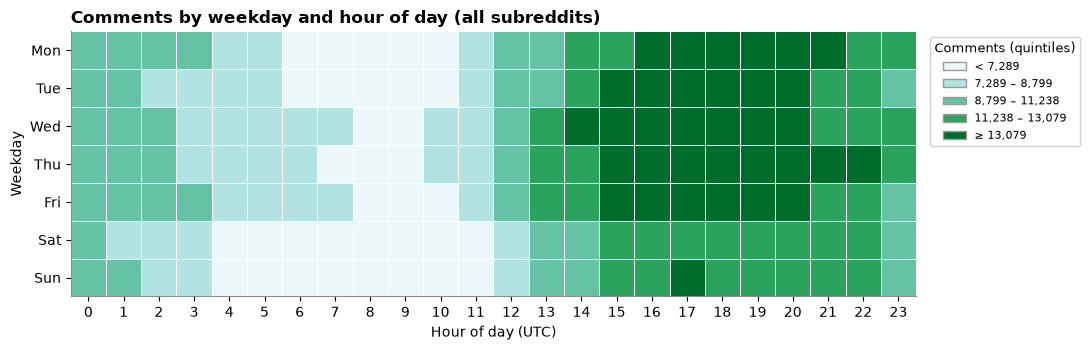

> **Answer.** The single busiest cell is Thu 18:00 UTC (15,747 comments); the weekend is clearly quieter.

In [67]:
Q("Which hours and weekdays are busiest overall? (weekday × hour, all subreddits)")
wh = cm.groupby(["weekday", "hour"]).size().unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0)
inner, cols = qinner(wh.values, SEQ5)
fig, ax = plt.subplots(figsize=(11, 3.6))
hd = class_heat(ax, wh, inner, cols, f="{:,.0f}", xt=list(range(24)), yt=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
done(ax, "Comments by weekday and hour of day (all subreddits)", "Hour of day (UTC)", "Weekday", ltitle="Comments (quintiles)", outside=True, handles=hd)
i, j = np.unravel_index(wh.values.argmax(), wh.shape); A(f"The single busiest cell is {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][i]} {j}:00 UTC ({wh.values.max():,.0f} comments); the weekend is clearly quieter.")

#### Q13. Is the weekend effect the same in every community? (share of comments written on Saturday and Sunday)

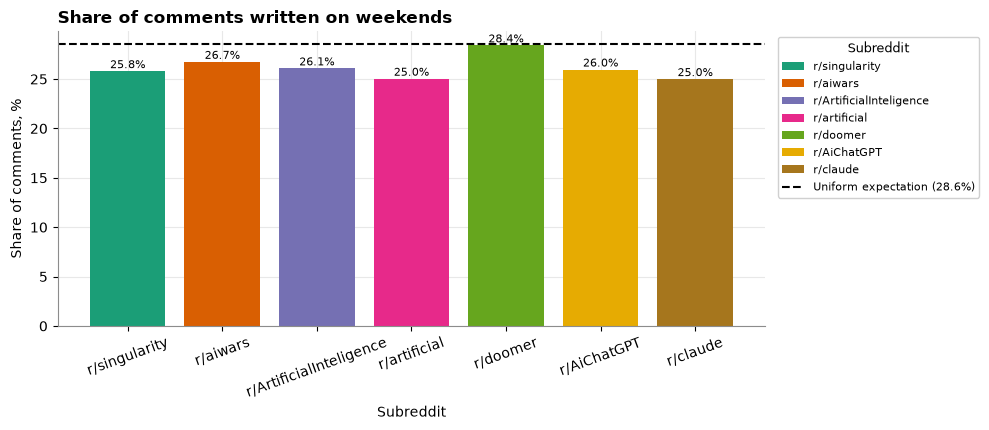

> **Answer.** Every community writes less at weekends than the uniform 28.6% (r/doomer is the closest, 28.4%). Among the big communities the lowest weekend share is r/artificial (25.0%) and the highest r/doomer (28.4%). A lower weekend share suggests a more work/study-related audience; r/doomer looks like a leisure-time community.

In [68]:
Q("Is the weekend effect the same in every community? (share of comments written on Saturday and Sunday)")
we = (cm.assign(w=cm.weekday >= 5).groupby("subreddit")["w"].mean() * 100).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4.4)); ax.bar([f"r/{s}" for s in we.index], we.values, color=[PAL[s] for s in we.index], label="_nolegend_")
ax.axhline(200 / 7, color="black", ls="--", label="Expected if activity were uniform (2/7 = 28.6%)")
for i_, v in enumerate(we.values): ax.text(i_, v + .3, f"{v:.1f}%", ha="center", fontsize=8)
ax.tick_params(axis="x", rotation=20)
done(ax, "Share of comments written on weekends", "Subreddit", "Share of comments, %", handles=sub_handles(order) + [Line2D([0], [0], color="black", ls="--", label="Uniform expectation (28.6%)")], outside=True, ltitle="Subreddit")
wb = we.reindex(BIG)
A(f"Every community writes less at weekends than the uniform 28.6% (r/doomer is the closest, {we.get('doomer', np.nan):.1f}%). Among the big communities the lowest weekend share is r/{wb.idxmin()} ({wb.min():.1f}%) and the highest r/{wb.idxmax()} ({wb.max():.1f}%). "
  "A lower weekend share suggests a more work/study-related audience; r/doomer looks like a leisure-time community.")

## 3. Communities: debate or information? (H6, H11)
**H6.** Debate communities have longer, harsher threads: more comments per post, deeper reply chains, more downvoted comments.
**H11 (new).** Titles phrased as a question invite discussion — they get more comments than statements.

#### Q14. How much discussion does a typical post start in each community?

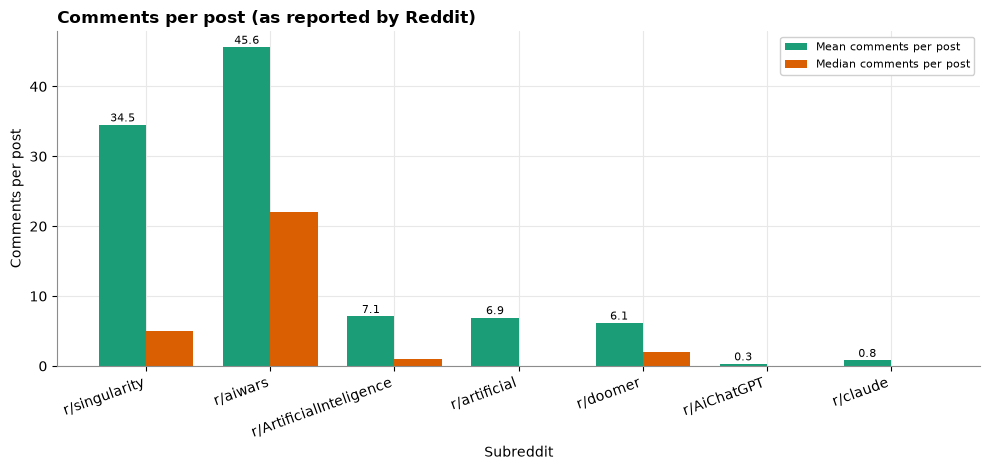

> **Answer.** Mean: r/aiwars 45.6 comments per post vs r/AiChatGPT 0.3. The mean is far above the median everywhere (heavy tail: a few threads explode).

In [69]:
Q("How much discussion does a typical post start in each community?")
cps = sb.groupby("subreddit")["num_comments"].agg(["mean", "median"]).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(cps)); w = .38
ax.bar(x - w/2, cps["mean"], w, color=C1, label="Mean comments per post"); ax.bar(x + w/2, cps["median"], w, color=C2, label="Median comments per post")
for i, v in enumerate(cps["mean"]): ax.text(i - w/2, v + .5, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in cps.index], rotation=20, ha="right")
done(ax, "Comments per post (as reported by Reddit)", "Subreddit", "Comments per post", loc="upper right")
A(f"Mean: r/{cps['mean'].idxmax()} {cps['mean'].max():.1f} comments per post vs r/{cps['mean'].idxmin()} {cps['mean'].min():.1f}. The mean is far above the median everywhere (heavy tail: a few threads explode).")

In [70]:
# reply-tree depth from parent_id: depth 1 = reply to the post (t3_), depth k+1 = reply to a comment of depth k (t1_)
pid = cm["parent_id"].astype(str); is_top = pid.str.startswith("t3_").to_numpy()
id_to_idx = pd.Series(np.arange(len(cm)), index=cm["id"].to_numpy())
pidx = pid.str[3:].map(id_to_idx).to_numpy(dtype="float64")
depth = np.where(is_top, 1, 0).astype(np.int32)
has_p = (~np.isnan(pidx)) & (~is_top); ii = np.flatnonzero(has_p); pi = pidx[has_p].astype(np.int64)
for _ in range(500):
    upd = (depth[ii] == 0) & (depth[pi] > 0)
    if not upd.any(): break
    depth[ii[upd]] = depth[pi[upd]] + 1
cm["depth"] = depth; known = cm.loc[cm.depth > 0, ["subreddit", "depth"]]
print(f"comments without a resolvable depth (parent outside the window): {(cm.depth == 0).mean()*100:.1f}%")

comments without a resolvable depth (parent outside the window): 1.5%


#### Q15. Are conversations flat (replies to the post) or nested (replies to replies)?

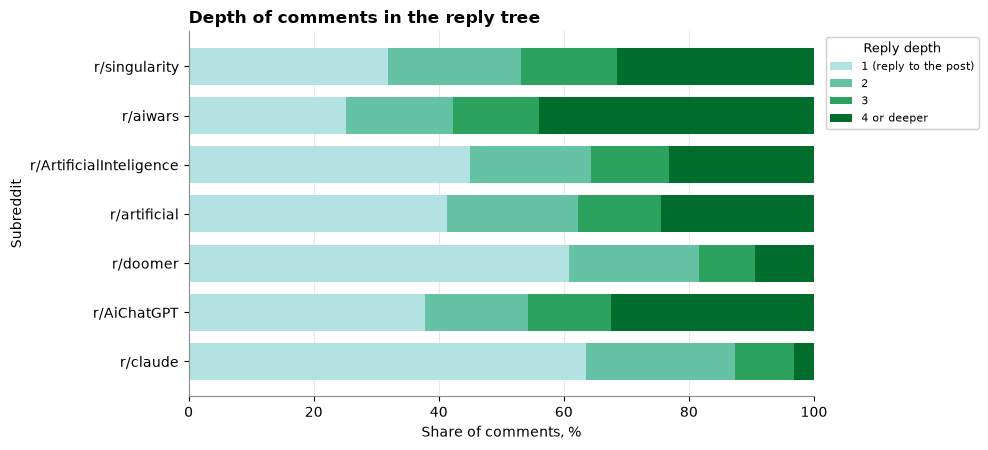

> **Answer.** Most nested: r/aiwars (75% of comments are replies to replies); flattest of the big communities: r/doomer (39%). Long reply chains mean people argue with each other, not only with the post.

In [71]:
Q("Are conversations flat (replies to the post) or nested (replies to replies)?")
bk = pd.cut(known["depth"], [0, 1, 2, 3, 10**6], labels=["1 (reply to the post)", "2", "3", "4 or deeper"])
sd = pd.crosstab(known["subreddit"], bk, normalize="index").reindex(order) * 100
fig, ax = plt.subplots(figsize=(10, 4.6)); pos = stacked(ax, sd, dict(zip(sd.columns, SEQ5[1:])), horizontal=True, label=lambda c: c)
ax.set_yticks(pos); ax.set_yticklabels([f"r/{s}" for s in sd.index]); ax.invert_yaxis(); ax.set_xlim(0, 100)
done(ax, "Depth of comments in the reply tree", "Share of comments, %", "Subreddit", ltitle="Reply depth", outside=True)
deep = (100 - sd.iloc[:, 0]).reindex(BIG); A(f"Most nested: r/{deep.idxmax()} ({deep.max():.0f}% of comments are replies to replies); flattest of the big communities: r/{deep.idxmin()} ({deep.min():.0f}%). Long reply chains mean people argue with each other, not only with the post.")

#### Q16. How long do reply chains get? (share of comments reaching depth k or deeper)

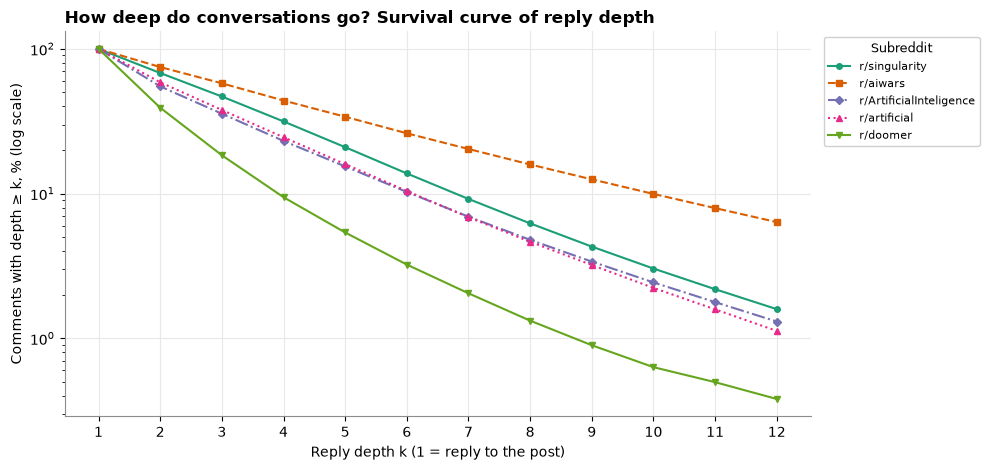

> **Answer.** Mean reply depth: r/singularity 3.15, r/aiwars 4.64, r/ArtificialInteligence 2.65, r/artificial 2.71, r/doomer 1.83.

In [72]:
Q("How long do reply chains get? (share of comments reaching depth k or deeper)")
ks = np.arange(1, 13); fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG:
    d = known.loc[known.subreddit == s, "depth"].to_numpy(); ax.plot(ks, [(d >= k).mean() * 100 for k in ks], color=PAL[s], ls=LS[s], marker=MK[s], ms=4, label=f"r/{s}")
ax.set_yscale("log"); ax.set_xticks(ks)
done(ax, "How deep do conversations go? Survival curve of reply depth", "Reply depth k (1 = reply to the post)", "Comments with depth ≥ k, % (log scale)", ltitle="Subreddit", outside=True)
md_ = known.groupby("subreddit")["depth"].mean().reindex(BIG); A("Mean reply depth: " + ", ".join(f"r/{s} {md_[s]:.2f}" for s in BIG) + ".")

#### Q17. How harsh is the voting? (share of comments with a negative score)

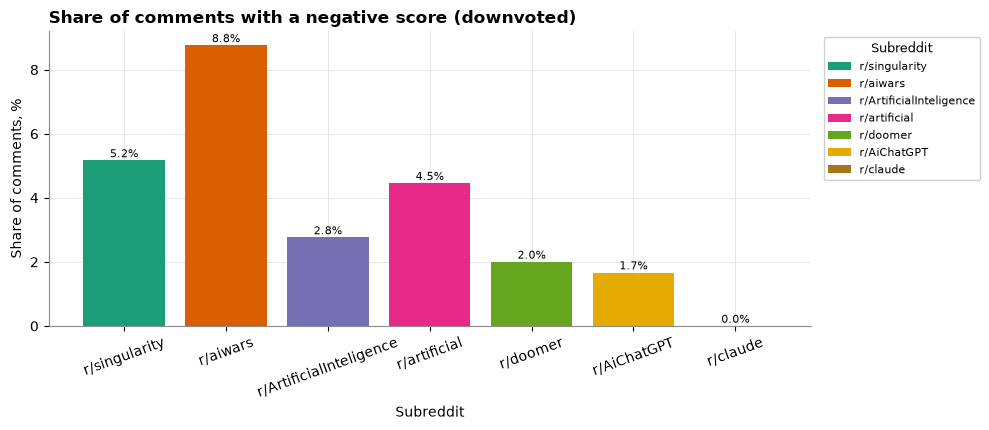

> **Answer.** The most downvoted community is r/aiwars (8.8% of comments), the least of the big ones r/doomer (2.0%). (r/claude and r/AiChatGPT are too small to compare.)

> **Verdict H6.** r/aiwars ranks first on 3 of 3 metrics (comments per post: r/aiwars; reply depth: r/aiwars; downvoted share: r/aiwars) → supported.

In [73]:
Q("How harsh is the voting? (share of comments with a negative score)")
neg = (cm.assign(n=cm.score < 0).groupby("subreddit")["n"].mean() * 100).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4.4)); ax.bar([f"r/{s}" for s in neg.index], neg.values, color=[PAL[s] for s in neg.index], label="_")
for i, v in enumerate(neg.values): ax.text(i, v + .1, f"{v:.1f}%", ha="center", fontsize=8)
ax.tick_params(axis="x", rotation=20)
done(ax, "Share of comments with a negative score (downvoted)", "Subreddit", "Share of comments, %", handles=sub_handles(order), ltitle="Subreddit", outside=True)
nb_ = neg.reindex(BIG); A(f"The most downvoted community is r/{nb_.idxmax()} ({nb_.max():.1f}% of comments), the least of the big ones r/{nb_.idxmin()} ({nb_.min():.1f}%). (r/claude and r/AiChatGPT are too small to compare.)")
# ---- verdict H6: how many of the three 'harshness' metrics rank the debate community first among big communities
if "aiwars" in BIG:
    m1 = cps["mean"].reindex(BIG).idxmax(); m2 = md_.idxmax(); m3 = neg.reindex(BIG).idxmax(); k = [m1, m2, m3].count("aiwars")
    VERDICT("H6", f"r/aiwars ranks first on {k} of 3 metrics (comments per post: r/{m1}; reply depth: r/{m2}; downvoted share: r/{m3}) → " +
            ("supported." if k == 3 else "partly supported." if k >= 1 else "not supported."))

#### Q18. How are comment scores distributed? (ECDF; most comments sit at the default score of 1)

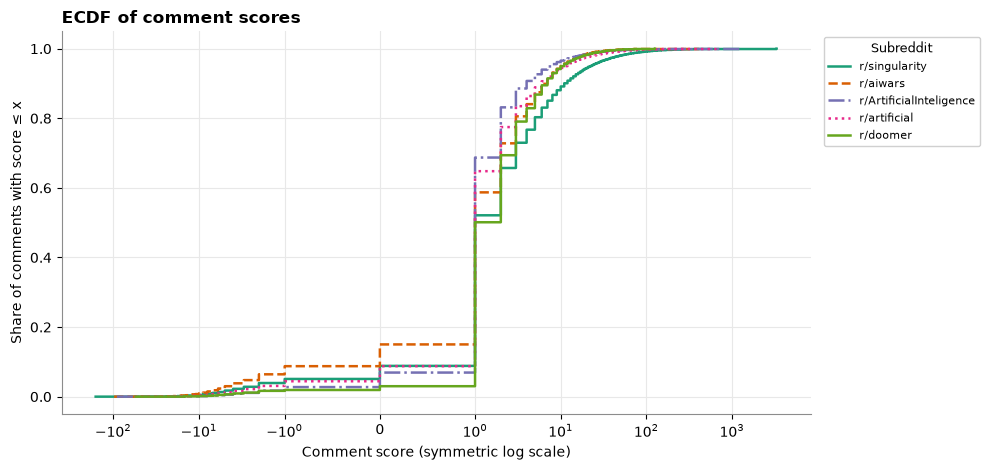

> **Answer.** Share of comments with score ≤ 1: r/singularity 52%, r/aiwars 59%, r/ArtificialInteligence 69%, r/artificial 65%, r/doomer 50%. The long right tail is where the visible comments live.

In [74]:
Q("How are comment scores distributed? (ECDF; most comments sit at the default score of 1)")
fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ecdf(ax, cm.loc[cm.subreddit == s, "score"], color=PAL[s], ls=LS[s], lw=1.8, label=f"r/{s}")
ax.set_xscale("symlog", linthresh=1)
done(ax, "ECDF of comment scores", "Comment score (symmetric log scale)", "Share of comments with score ≤ x", ltitle="Subreddit", outside=True)
p1 = {s: (cm.loc[cm.subreddit == s, "score"] <= 1).mean() * 100 for s in BIG}; A("Share of comments with score ≤ 1: " + ", ".join(f"r/{s} {v:.0f}%" for s, v in p1.items()) + ". The long right tail is where the visible comments live.")

#### Q19. Do communities differ in how divided their posts are? (upvote ratio)

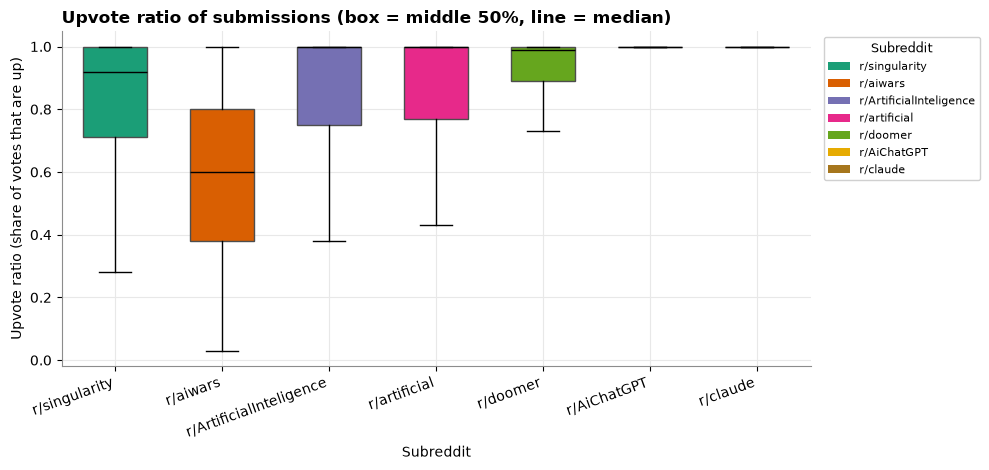

> **Answer.** r/aiwars has the most divisive posts: 63% of its posts have an upvote ratio below 0.7.

In [75]:
Q("Do communities differ in how divided their posts are? (upvote ratio)")
ur = [sb.loc[sb.subreddit == s, "upvote_ratio"].dropna().to_numpy() for s in order]
fig, ax = plt.subplots(figsize=(10, 4.8))
bp = ax.boxplot([u if len(u) else [np.nan] for u in ur], patch_artist=True, showfliers=False, widths=.6, medianprops=dict(color="black"))
for p_, s in zip(bp["boxes"], order): p_.set_facecolor(PAL[s]); p_.set_edgecolor("#4d4d4d")
ax.set_xticklabels([f"r/{s}" for s in order], rotation=20, ha="right")
done(ax, "Upvote ratio of submissions (box = middle 50%, line = median)", "Subreddit", "Upvote ratio (share of votes that are up)", handles=sub_handles(order), ltitle="Subreddit", outside=True)
lo = {s: (sb.loc[sb.subreddit == s, "upvote_ratio"] < .7).mean() * 100 for s in order}; w_ = max(lo, key=lo.get)
A(f"r/{w_} has the most divisive posts: {lo[w_]:.0f}% of its posts have an upvote ratio below 0.7.")

#### Q20. Do popular posts get more discussion? (post score vs. number of comments)

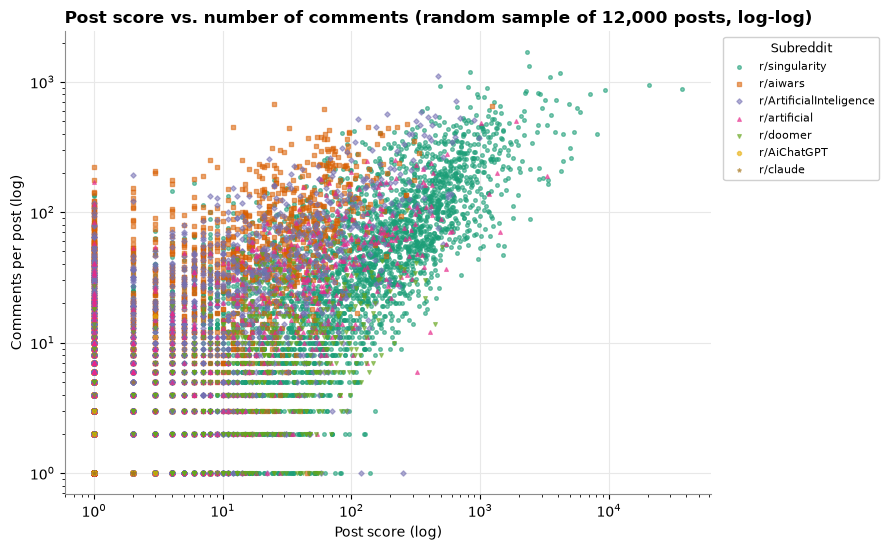

> **Answer.** Spearman ρ(score, comments) = **0.49**: popular posts are discussed more, but the link is only moderate. Post scores of some communities look frozen at ≈1 (collected right after posting), so score comparisons are limited to communities with real variation.

In [76]:
Q("Do popular posts get more discussion? (post score vs. number of comments)")
pp = sb[(sb.score > 0) & (sb.num_comments > 0)]; pp = pp.sample(min(len(pp), 12000), random_state=1)
fig, ax = plt.subplots(figsize=(9, 5.6))
for s in order:
    q = pp[pp.subreddit == s]; ax.scatter(q.score, q.num_comments, s=7, color=PAL[s], alpha=.55, label=f"r/{s}", marker=MK[s])
ax.set_xscale("log"); ax.set_yscale("log")
done(ax, "Post score vs. number of comments (random sample of 12,000 posts, log-log)", "Post score (log)", "Comments per post (log)", ltitle="Subreddit", outside=True)
rho = spearmanr(sb.score, sb.num_comments, nan_policy="omit")[0]; A(f"Spearman ρ(score, comments) = **{rho:.2f}**: popular posts are discussed more, but the link is only moderate. "
  "Post scores of some communities look frozen at ≈1 (collected right after posting), so score comparisons are limited to communities with real variation.")

#### Q21. Which posts divide the audience most? (many comments and a low upvote ratio)

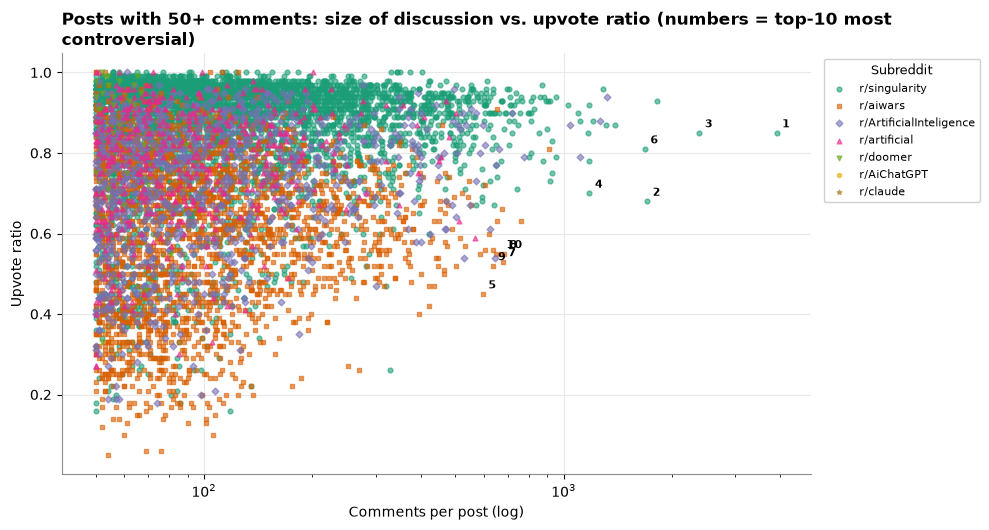

,subreddit,title,upvote_ratio,num_comments
1,singularity,This is a DOGE intern who is currently pawing ...,0.85,3907
2,singularity,That awkward moment..,0.68,1706
3,singularity,Both video and audio is AI but it feels so real,0.85,2382
4,singularity,We calculated UBI: It’s shockingly simple to f...,0.70,1179
5,aiwars,acting like a victim,0.45,596
6,singularity,"Anthropic CEO, Dario Amodei: in the next 3 to ...",0.81,1681
7,aiwars,This is... Beyond disgusting.,0.53,677
8,aiwars,"If I hire a caricature artist to draw me, did ...",0.55,682
9,aiwars,Basically this. None of it is a Theft. It is j...,0.52,634
10,aiwars,Proof that AI doesn't actually copy anything,0.55,669


> **Answer.** Top-10 controversial posts by community: r/singularity 5, r/aiwars 5. The r/singularity posts enter the list through very large threads with a moderate upvote ratio (0.7–0.85), the r/aiwars posts through a ratio near 0.5 — half of the voters downvote them. The score (1 − ratio) × comments rewards size, so both kinds of controversy appear.

In [77]:
Q("Which posts divide the audience most? (many comments and a low upvote ratio)")
p = sb[(sb.num_comments >= 50) & sb.upvote_ratio.notna()].copy()
if len(p) < 10: p = sb[(sb.num_comments >= 5) & sb.upvote_ratio.notna()].copy()
p["controv"] = (1 - p.upvote_ratio) * p.num_comments; top = p.nlargest(10, "controv")
fig, ax = plt.subplots(figsize=(10, 5.4))
for s in order:
    q = p[p.subreddit == s]; ax.scatter(q.num_comments, q.upvote_ratio, s=12, color=PAL[s], alpha=.6, marker=MK[s], label=f"r/{s}")
for k, (_, r) in enumerate(top.iterrows()): ax.annotate(str(k + 1), (r.num_comments, r.upvote_ratio), fontsize=8, fontweight="bold", xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log")
done(ax, "Posts with 50+ comments: size of discussion vs. upvote ratio (numbers = top-10 most controversial)", "Comments per post (log)", "Upvote ratio", ltitle="Subreddit", outside=True)
tt = top[["subreddit", "title", "upvote_ratio", "num_comments"]].reset_index(drop=True); tt.index += 1; tt["title"] = tt.title.str[:90]; display(tt)
vc_ = top.subreddit.value_counts()
A("Top-10 controversial posts by community: " + ", ".join(f"r/{s} {n}" for s, n in vc_.items()) + ". The r/singularity posts enter the list through very large threads with a moderate upvote ratio (0.7–0.85), "
  "the r/aiwars posts through a ratio near 0.5 — half of the voters downvote them. The score (1 − ratio) × comments rewards size, so both kinds of controversy appear.")

#### Q22. H11: Do titles phrased as a question get more comments than statements?

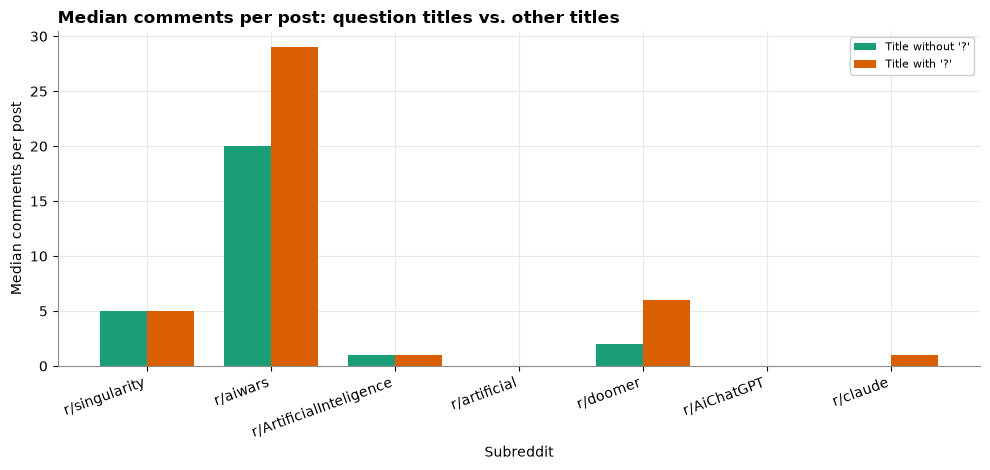

> **Verdict H11.** question titles (26% of posts) have a higher median comment count in 2 of 5 big communities (r/aiwars, r/doomer), the same median in 3 and a lower one in 0 → partly supported: questions help in debate communities, elsewhere the median is the same.

In [78]:
Q("H11: Do titles phrased as a question get more comments than statements?")
g = sb.groupby(["subreddit", "has_q"])["num_comments"].median().unstack().reindex(index=order, columns=[False, True])
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(g)); w = .38
ax.bar(x - w/2, g[False], w, color=C1, label="Title without '?'"); ax.bar(x + w/2, g[True], w, color=C2, label="Title with '?'")
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in g.index], rotation=20, ha="right")
done(ax, "Median comments per post: question titles vs. other titles", "Subreddit", "Median comments per post", loc="upper right")
gb = g.reindex(BIG).fillna(0); wins = int((gb[True] > gb[False]).sum()); ties = int((gb[True] == gb[False]).sum()); loss = len(gb) - wins - ties; share_q = sb.has_q.mean() * 100
VERDICT("H11", f"question titles ({share_q:.0f}% of posts) have a higher median comment count in {wins} of {len(gb)} big communities ("
        + ", ".join(f"r/{s}" for s in gb.index[gb[True] > gb[False]]) + f"), the same median in {ties} and a lower one in {loss} → "
        + ("supported." if wins >= len(gb) * .7 else "partly supported: questions help in debate communities, elsewhere the median is the same." if wins >= 1 and loss == 0 else "not supported."))

#### Q23. H11b: Does the kind of post (text, image, video, link) change engagement?

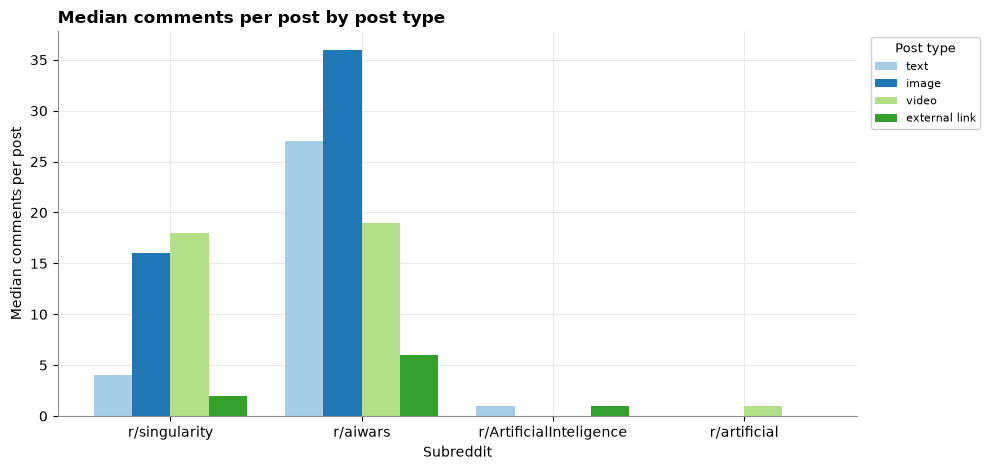

> **Answer.** The highest median is for image posts in r/aiwars (36 comments).

In [79]:
Q("H11b: Does the kind of post (text, image, video, link) change engagement?")
pt = ["text", "image", "video", "external link"]
g = sb[sb.subreddit.isin(BIG[:4])].groupby(["subreddit", "post_type"])["num_comments"].median().unstack().reindex(index=BIG[:4], columns=pt)
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(g)); w = .2
for i, t_ in enumerate(pt): ax.bar(x + (i - 1.5) * w, g[t_].fillna(0), w, color=PAIRED4[i], label=t_)
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in g.index])
done(ax, "Median comments per post by post type", "Subreddit", "Median comments per post", ltitle="Post type", outside=True)
bt_ = g.stack().idxmax(); A(f"The highest median is for {bt_[1]} posts in r/{bt_[0]} ({g.stack().max():.0f} comments).")

#### Q24. When is the best moment to post? (average log10(comments + 1) by weekday and hour of posting)

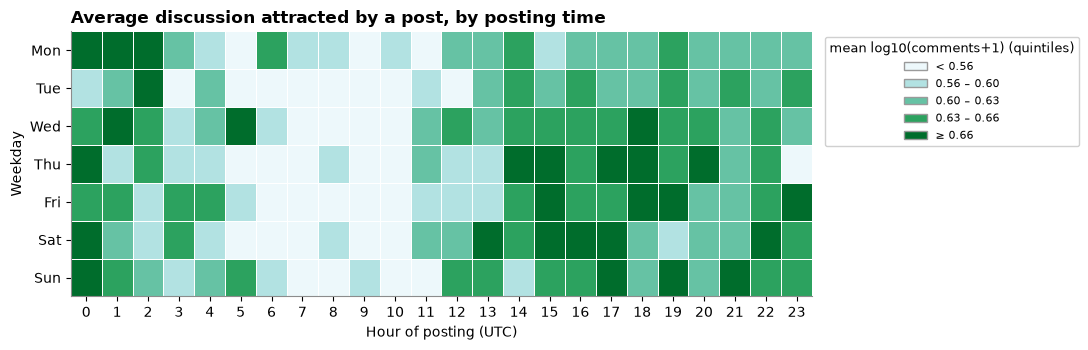

> **Answer.** Posts published on Thu around 17:00 UTC attract the most discussion on average (it is a pattern, not a guarantee).

In [80]:
Q("When is the best moment to post? (average log10(comments + 1) by weekday and hour of posting)")
bt = sb.assign(lc=np.log10(sb.num_comments + 1)).groupby(["weekday", "hour"])["lc"].mean().unstack().reindex(index=range(7), columns=range(24))
inner, cols = qinner(bt.values, SEQ5)
fig, ax = plt.subplots(figsize=(11, 3.6)); hd = class_heat(ax, bt, inner, cols, f="{:.2f}", xt=list(range(24)), yt=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
done(ax, "Average discussion attracted by a post, by posting time", "Hour of posting (UTC)", "Weekday", ltitle="mean log10(comments+1) (quintiles)", outside=True, handles=hd)
i, j = np.unravel_index(np.nanargmax(bt.values), bt.shape); A(f"Posts published on {['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][i]} around {j}:00 UTC attract the most discussion on average (it is a pattern, not a guarantee).")

#### Q25. H11c: Do longer titles attract more or less discussion?

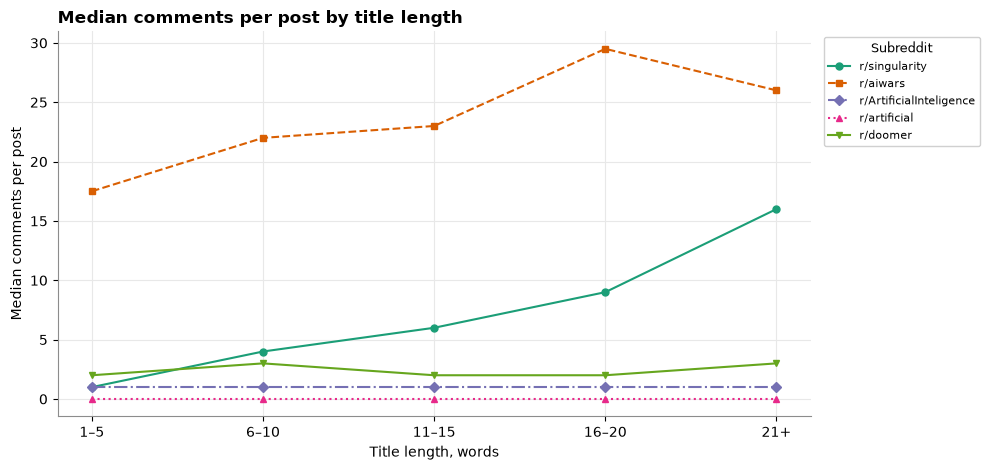

> **Answer.** Median comments, shortest → longest titles: r/singularity 1 → 16; r/aiwars 17.5 → 26; r/ArtificialInteligence 1 → 1; r/artificial 0 → 0; r/doomer 2 → 3. In r/singularity and r/aiwars longer titles (more context) go together with more discussion; in the other big communities the median stays near 0–3 whatever the title length.

In [81]:
Q("H11c: Do longer titles attract more or less discussion?")
tb = pd.cut(sb.title_words, [0, 5, 10, 15, 20, 10**4], labels=["1–5", "6–10", "11–15", "16–20", "21+"])
g = sb.assign(tb=tb).groupby(["tb", "subreddit"])["num_comments"].median().unstack().reindex(columns=order)
fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ax.plot(range(len(g)), g[s], color=PAL[s], ls=LS[s], marker=MK[s], ms=5, label=f"r/{s}")
ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
done(ax, "Median comments per post by title length", "Title length, words", "Median comments per post", ltitle="Subreddit", outside=True)
A("Median comments, shortest → longest titles: " + "; ".join(f"r/{s} {g[s].iloc[0]:g} → {g[s].iloc[-1]:g}" for s in BIG) + ". "
  "In r/singularity and r/aiwars longer titles (more context) go together with more discussion; in the other big communities the median stays near 0–3 whatever the title length.")

## 4. People: who writes, who overlaps, who is a bot? (H7, H9, H13)
**H7.** A few users produce most of the content. **H9.** Communities share some, but not all, of their audience. **H13 (new).** Newcomers write shorter comments and earn lower relative scores than established users.

#### Q26. Who are the most active commenters?

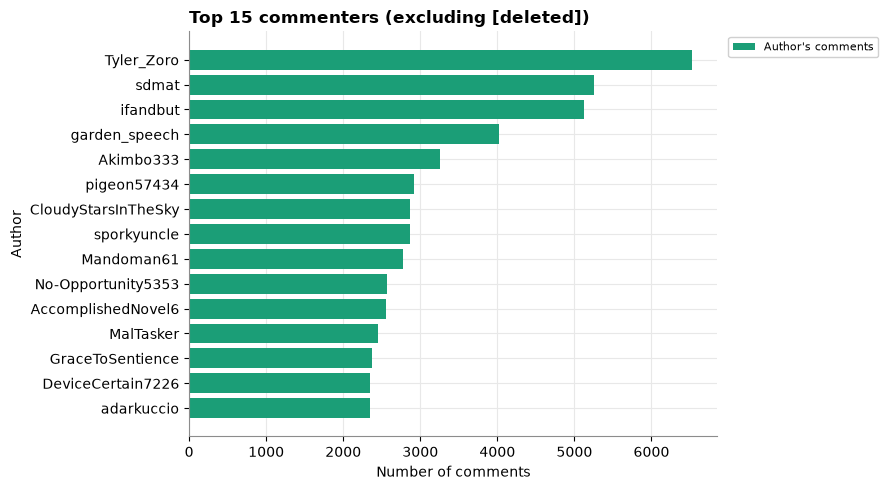

> **Answer.** Top commenter **Tyler_Zoro** wrote 6,530 comments (0.38% of all comments).

In [82]:
nd = cm[~cm.deleted_author]; ccount = nd.author.value_counts(); scount = sb[~sb.deleted_author].author.value_counts()
Q("Who are the most active commenters?")
t = ccount.head(15)[::-1]; fig, ax = plt.subplots(figsize=(9, 5)); ax.barh(t.index, t.values, color=C1)
done(ax, "Top 15 commenters (excluding [deleted])", "Number of comments", "Author", fallback=(C1, "Author's comments"), loc="lower right")
A(f"Top commenter **{t.index[-1]}** wrote {t.iloc[-1]:,} comments ({t.iloc[-1]/len(cm)*100:.2f}% of all comments).")

#### Q27. Who are the most active submitters, and do they look like human users?

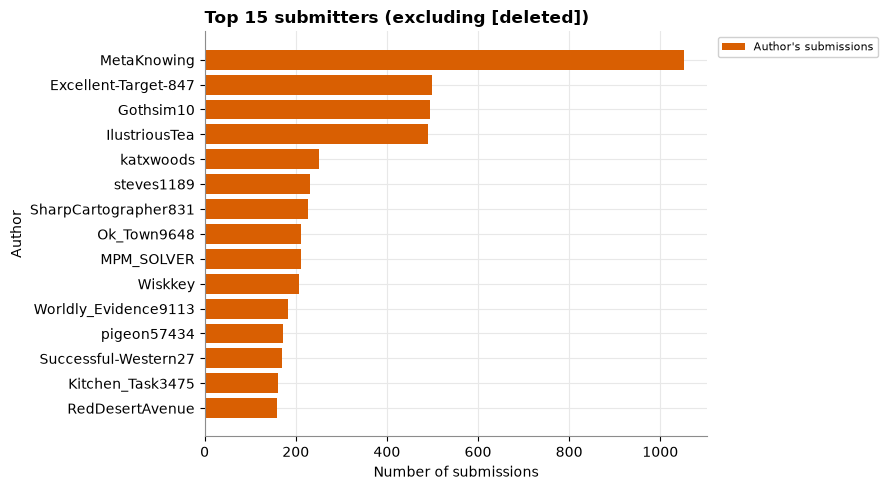

> **Answer.** **MetaKnowing** posted 1,051 submissions (1.4% of all posts) — such volume suggests a news-curator or a bot (checked below).

In [83]:
Q("Who are the most active submitters, and do they look like human users?")
t = scount.head(15)[::-1]; fig, ax = plt.subplots(figsize=(9, 5)); ax.barh(t.index, t.values, color=C2)
done(ax, "Top 15 submitters (excluding [deleted])", "Number of submissions", "Author", fallback=(C2, "Author's submissions"), loc="lower right")
A(f"**{t.index[-1]}** posted {t.iloc[-1]:,} submissions ({t.iloc[-1]/len(sb)*100:.1f}% of all posts) — such volume suggests a news-curator or a bot (checked below).")

#### Q28. H7: How unequal is participation? (Lorenz curves, Gini coefficient)

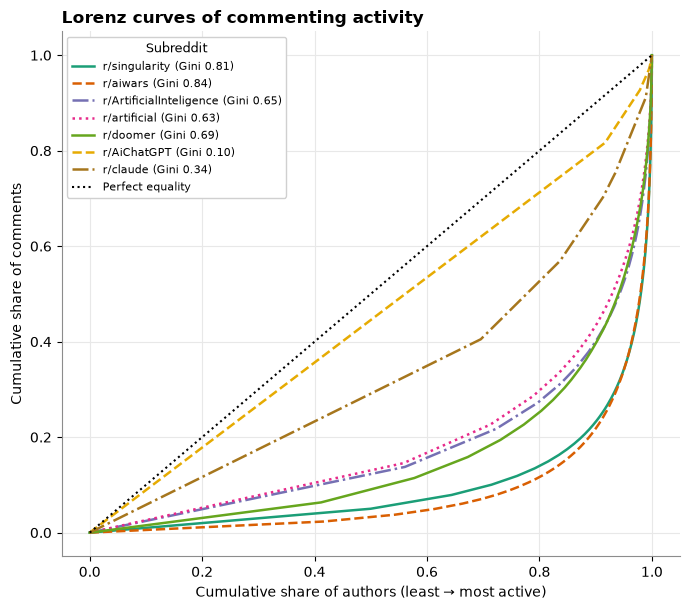

> **Verdict H7.** the top 1% of commenters (1,679 accounts) write 39.6% of all comments; 49% of commenters wrote exactly one comment; Gini of the big communities between 0.63 and 0.84 (the tiny r/AiChatGPT and r/claude are almost equal only because nobody there writes much) → supported.

In [84]:
Q("H7: How unequal is participation? (Lorenz curves, Gini coefficient)")
_trap = getattr(np, "trapezoid", None) or np.trapz
def lorenz(v):
    c = np.sort(np.asarray(v)); cs = np.r_[0, np.cumsum(c) / c.sum()]; x = np.linspace(0, 1, len(cs)); return x, cs, 1 - 2 * _trap(cs, x)
fig, ax = plt.subplots(figsize=(7, 6.2)); gi = {}
for s in order:
    v = nd.loc[nd.subreddit == s, "author"].value_counts().values
    if len(v) < 50: continue
    x, y, g_ = lorenz(v); gi[s] = g_; ax.plot(x, y, color=PAL[s], ls=LS[s], lw=1.8, label=f"r/{s} (Gini {g_:.2f})")
ax.plot([0, 1], [0, 1], color="black", ls=":", label="Perfect equality")
done(ax, "Lorenz curves of commenting activity", "Cumulative share of authors (least → most active)", "Cumulative share of comments", ltitle="Subreddit", loc="upper left")
n1 = max(1, int(len(ccount) * .01)); sh1 = ccount.head(n1).sum() / len(nd) * 100; once = (ccount == 1).mean() * 100
VERDICT("H7", f"the top 1% of commenters ({n1:,} accounts) write {sh1:.1f}% of all comments; {once:.0f}% of commenters wrote exactly one comment; Gini of the big communities between {min(gi[s] for s in BIG if s in gi):.2f} and {max(gi[s] for s in BIG if s in gi):.2f} (the tiny r/AiChatGPT and r/claude are almost equal only because nobody there writes much) → " + ("supported." if sh1 > 25 else "partly supported."))

#### Q29. How heavy is the tail? (number of authors who wrote exactly k items)

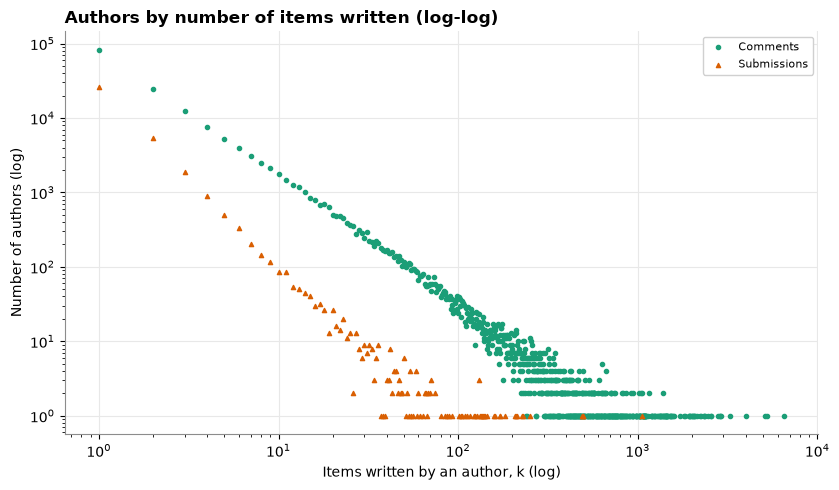

> **Answer.** 82,855 commenters wrote exactly one comment, while the most active wrote 6,530 — the points fall on an almost straight line in the log-log plot, the signature of heavy-tailed (power-law-like) activity. Submissions fall even faster: posting is rarer than commenting.

In [85]:
Q("How heavy is the tail? (number of authors who wrote exactly k items)")
kc = ccount.value_counts().sort_index(); ks_ = scount.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.5, 5)); ax.scatter(kc.index, kc.values, s=9, color=C1, label="Comments"); ax.scatter(ks_.index, ks_.values, s=9, color=C2, marker="^", label="Submissions")
ax.set_xscale("log"); ax.set_yscale("log"); done(ax, "Authors by number of items written (log-log)", "Items written by an author, k (log)", "Number of authors (log)", loc="upper right")
A(f"{kc.iloc[0]:,} commenters wrote exactly one comment, while the most active wrote {kc.index[-1]:,} — the points fall on an almost straight line in the log-log plot, the signature of heavy-tailed (power-law-like) activity. Submissions fall even faster: posting is rarer than commenting.")

#### Q30. H9: How much of the audience do communities share? (Jaccard overlap of commenters)

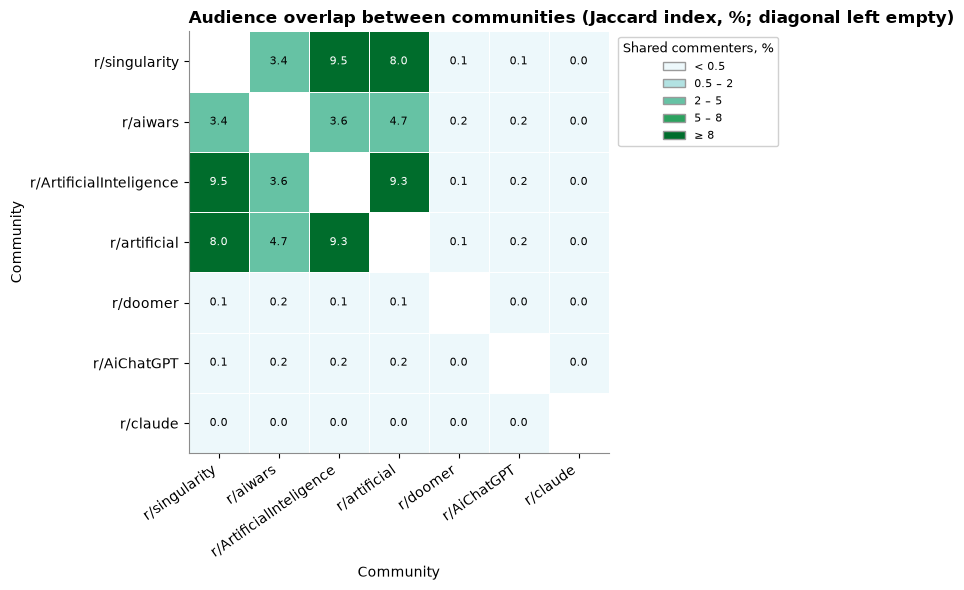

> **Answer.** The most overlapping pair is r/singularity – r/ArtificialInteligence (9.5%); the four general AI communities share 3–10% of their commenters with each other. r/doomer, r/AiChatGPT, r/claude share at most 0.2% with any other community — they are separate islands.

In [86]:
Q("H9: How much of the audience do communities share? (Jaccard overlap of commenters)")
sets = {s: set(g.unique()) for s, g in nd.groupby("subreddit")["author"]}
J = pd.DataFrame({b: {a: (len(sets[a] & sets[b]) / max(1, len(sets[a] | sets[b])) * 100 if a != b else np.nan) for a in order} for b in order}).loc[order, order]
fig, ax = plt.subplots(figsize=(8, 6)); hd = class_heat(ax, J, [.5, 2, 5, 8], SEQ5, f="{:g}", annot="{:.1f}", xt=[f"r/{s}" for s in order], yt=[f"r/{s}" for s in order], xrot=35, font=8)
done(ax, "Audience overlap between communities (Jaccard index, %; diagonal left empty)", "Community", "Community", ltitle="Shared commenters, %", outside=True, handles=hd)
jj = pd.Series({(a, b): J.loc[a, b] for i, a in enumerate(order) for b in order[i + 1:]}).sort_values(ascending=False)
iso = [s for s in order if J[s].max() < 1]
A(f"The most overlapping pair is r/{jj.index[0][0]} – r/{jj.index[0][1]} ({jj.iloc[0]:.1f}%); the four general AI communities share 3–10% of their commenters with each other. "
  + (", ".join(f"r/{s}" for s in iso) + f" share at most {max(J[s].max() for s in iso):.1f}% with any other community — they are separate islands." if iso else ""))

#### Q31. H9: In how many communities does a typical commenter take part?

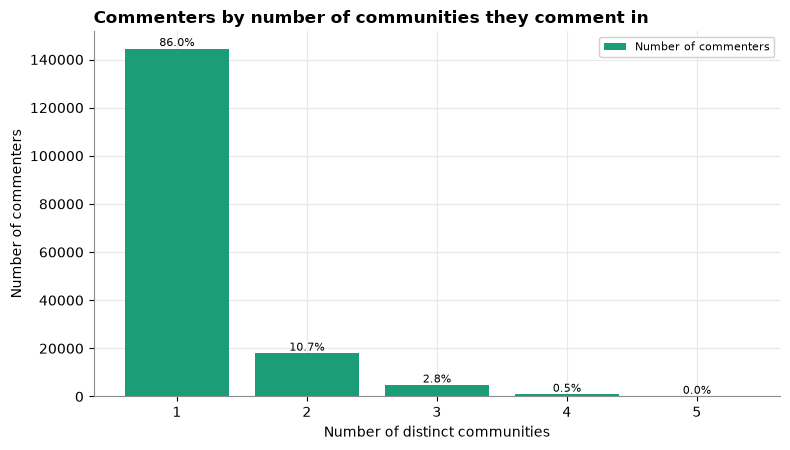

> **Verdict H9.** 86% of commenters took part in only one community, 14% in two or more; the strongest overlap is r/singularity – r/ArtificialInteligence, while r/doomer and the product communities are almost isolated → partly supported (shared core of general AI communities, separate niches).

In [87]:
Q("H9: In how many communities does a typical commenter take part?")
nsub = nd.groupby("author")["subreddit"].nunique().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.6)); ax.bar(nsub.index.astype(str), nsub.values, color=C1, label="Number of commenters")
for i, v in enumerate(nsub.values): ax.text(i, v, f"{v/nsub.sum()*100:.1f}%", ha="center", va="bottom", fontsize=8)
done(ax, "Commenters by number of communities they comment in", "Number of distinct communities", "Number of commenters", loc="upper right")
VERDICT("H9", f"{nsub.iloc[0]/nsub.sum()*100:.0f}% of commenters took part in only one community, {nsub.iloc[1:].sum()/nsub.sum()*100:.0f}% in two or more; the strongest overlap is r/{jj.index[0][0]} – r/{jj.index[0][1]}, while r/doomer and the product communities are almost isolated → partly supported (shared core of general AI communities, separate niches).")

#### Q32. What does the shared-audience network look like? (node = community, edge = shared commenters)

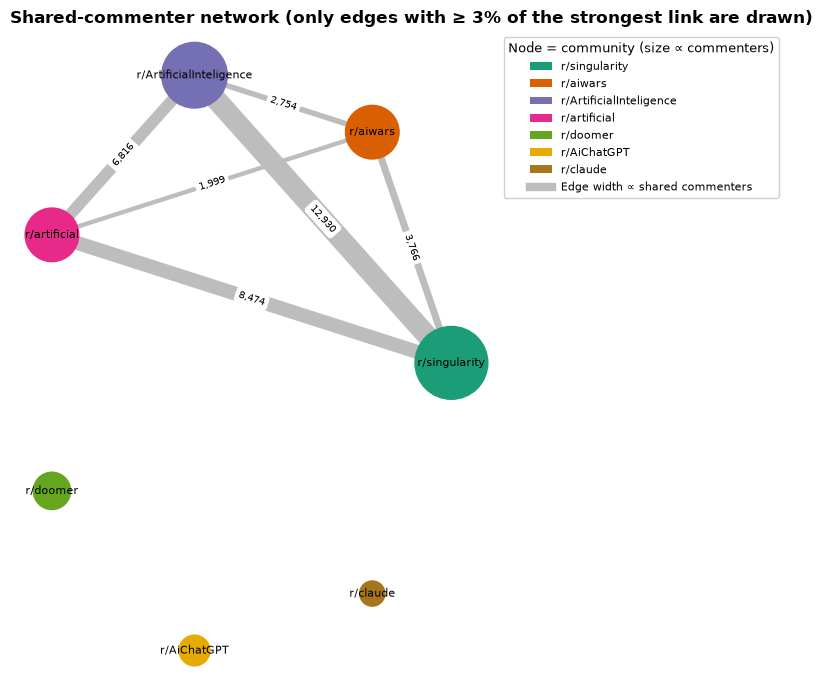

> **Answer.** The strongest link is r/singularity – r/ArtificialInteligence with 12,930 shared commenters. Without any drawn edge: r/doomer, r/AiChatGPT, r/claude.

In [88]:
Q("What does the shared-audience network look like? (node = community, edge = shared commenters)")
pairs = [(a, b, len(sets[a] & sets[b])) for i, a in enumerate(order) for b in order[i + 1:]]; mx = max(w for *_, w in pairs) or 1
G = nx.Graph(); [G.add_node(s) for s in order]; [G.add_edge(a, b, weight=w) for a, b, w in pairs if w >= .03 * mx]
pos = nx.circular_layout(G); fig, ax = plt.subplots(figsize=(8, 7))
nx.draw_networkx_edges(G, pos, ax=ax, width=[1 + 14 * G[u][v]["weight"] / mx for u, v in G.edges], edge_color=LGREY)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[PAL[n] for n in G], node_size=[250 + 2500 * np.sqrt(len(sets[n]) / max(len(v) for v in sets.values())) for n in G])
nx.draw_networkx_labels(G, pos, labels={n: f"r/{n}" for n in G}, font_size=8, ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): f"{w:,}" for a, b, w in pairs if w >= .15 * mx}, font_size=7, ax=ax)
ax.axis("off"); done(ax, "Shared-commenter network (only edges with ≥ 3% of the strongest link are drawn)", "", "", handles=sub_handles(order) + [Line2D([0], [0], color=LGREY, lw=6, label="Edge width ∝ shared commenters")], outside=True, ltitle="Node = community (size ∝ commenters)")
lonely = [n for n in G if G.degree(n) == 0]
A(f"The strongest link is r/{max(pairs, key=lambda p: p[2])[0]} – r/{max(pairs, key=lambda p: p[2])[1]} with {max(w for *_, w in pairs):,} shared commenters. "
  + (("Without any drawn edge: " + ", ".join(f"r/{n}" for n in lonely) + ".") if lonely else ""))

#### Q33. H9: Is the shared audience made of casual visitors or of committed users? (share of commenters active in 2+ communities)

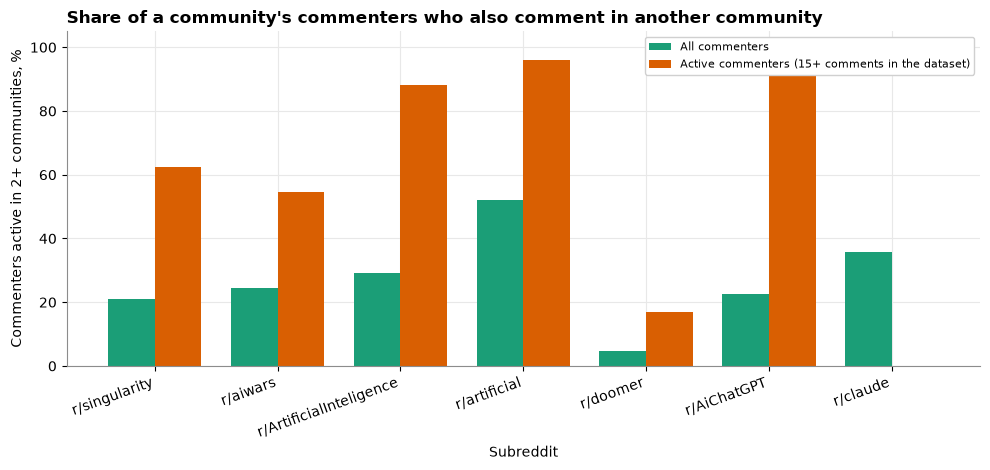

> **Answer.** In the big communities 5–52% of all commenters also write elsewhere, but among active commenters it is 17–96%. The overlap is carried by a core of committed users who move between the general AI communities; occasional visitors stay in one place. (Communities with fewer than 20 active commenters are left empty.)

In [89]:
Q("H9: Is the shared audience made of casual visitors or of committed users? (share of commenters active in 2+ communities)")
cnt_a = nd.author.value_counts(); act_a = set(cnt_a[cnt_a >= 15].index)
nsub_a = nd.groupby("author")["subreddit"].nunique(); multi = set(nsub_a[nsub_a >= 2].index)
ov2 = pd.DataFrame({s: {"All commenters": len(sets[s] & multi) / max(1, len(sets[s])) * 100,
                        "Active commenters (15+ comments)": (len(sets[s] & act_a & multi) / len(sets[s] & act_a) * 100) if len(sets[s] & act_a) >= 20 else np.nan}
                    for s in order}).T
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(ov2)); w = .38
ax.bar(x - w/2, ov2["All commenters"], w, color=C1, label="All commenters")
ax.bar(x + w/2, ov2["Active commenters (15+ comments)"].fillna(0), w, color=C2, label="Active commenters (15+ comments in the dataset)")
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in ov2.index], rotation=20, ha="right")
done(ax, "Share of a community's commenters who also comment in another community", "Subreddit", "Commenters active in 2+ communities, %", loc="upper right")
ob = ov2.reindex(BIG)
A(f"In the big communities {ob['All commenters'].min():.0f}–{ob['All commenters'].max():.0f}% of all commenters also write elsewhere, but among active commenters it is "
  f"{ob['Active commenters (15+ comments)'].min():.0f}–{ob['Active commenters (15+ comments)'].max():.0f}%. The overlap is carried by a core of committed users who move between the general AI "
  "communities; occasional visitors stay in one place. (Communities with fewer than 20 active commenters are left empty.)")

#### Q34. Does the crowd renew itself? (first-time vs returning commenters per month)

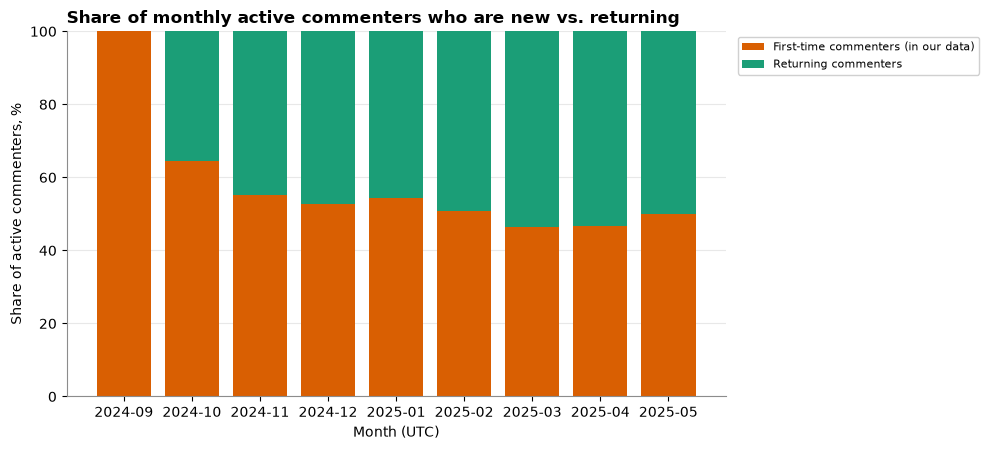

> **Answer.** The first month is 100% 'new' by construction. After that, 53% of monthly commenters on average are first-timers: the audience keeps renewing quickly.

In [90]:
Q("Does the crowd renew itself? (first-time vs returning commenters per month)")
a_first = nd.groupby("author")["month"].min(); act = nd.drop_duplicates(["author", "month"])[["author", "month"]].copy()
act["new"] = act["month"].eq(act["author"].map(a_first)); shn = act.groupby(["month", "new"]).size().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
shn = shn.div(shn.sum(1), axis=0) * 100; fig, ax = plt.subplots(figsize=(10, 4.6))
pos = np.arange(len(shn)); ax.bar(pos, shn[True], color=C2, label="First-time commenters (in our data)"); ax.bar(pos, shn[False], bottom=shn[True], color=C1, label="Returning commenters")
ax.set_xticks(pos); ax.set_xticklabels(shn.index.strftime("%Y-%m")); ax.set_ylim(0, 100)
done(ax, "Share of monthly active commenters who are new vs. returning", "Month (UTC)", "Share of active commenters, %", outside=True)
A(f"The first month is 100% 'new' by construction. After that, {shn[True].iloc[1:].mean():.0f}% of monthly commenters on average are first-timers: the audience keeps renewing quickly.")

#### Q35. Do newcomers stay? (retention of commenter cohorts)

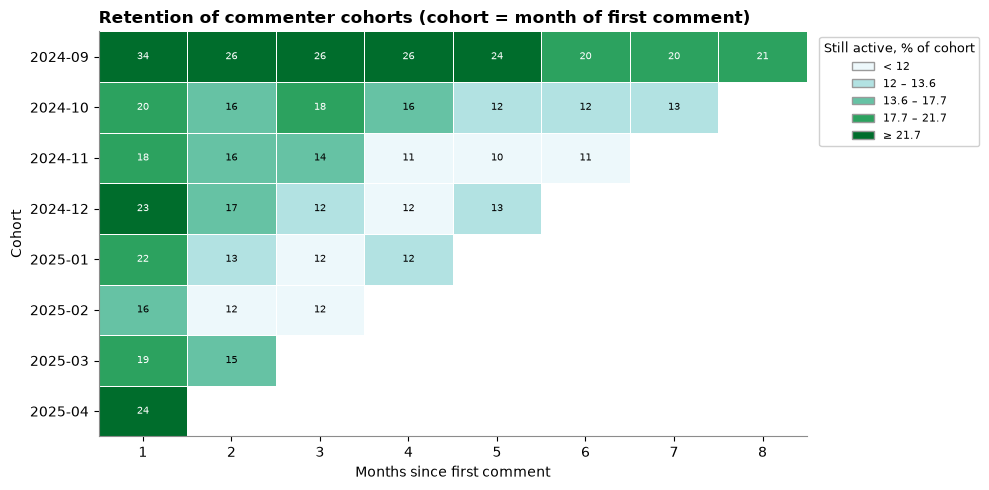

> **Answer.** Typical one-month retention is 22%: most newcomers comment once and disappear. The first cohort mixes real newcomers with everyone already active before September 2024.

In [91]:
Q("Do newcomers stay? (retention of commenter cohorts)")
act["m"] = act["month"].dt.year * 12 + act["month"].dt.month; act["c"] = act["author"].map(a_first).dt.year * 12 + act["author"].map(a_first).dt.month
act["age"] = act["m"] - act["c"]; tab = act.groupby(["c", "age"])["author"].nunique().unstack(); sz = tab[0]
ret = (tab.div(sz, axis=0) * 100).loc[sz[sz >= 300].index].drop(columns=0).dropna(how="all")      # last cohort has no later month yet
ret.index = [f"{(m - 1) // 12}-{(m - 1) % 12 + 1:02d}" for m in ret.index]
inner, cols = qinner(ret.values[~np.isnan(ret.values)], SEQ5); inner = np.unique(np.round(inner, 1)); cols = pick(SEQ5, len(inner) + 1)
fig, ax = plt.subplots(figsize=(10, 5)); hd = class_heat(ax, ret, inner, cols, f="{:g}", annot="{:.0f}", xt=list(ret.columns))
done(ax, "Retention of commenter cohorts (cohort = month of first comment)", "Months since first comment", "Cohort", ltitle="Still active, % of cohort", outside=True, handles=hd)
A(f"Typical one-month retention is {np.nanmean(ret.iloc[:, 0]):.0f}%: most newcomers comment once and disappear. The first cohort mixes real newcomers with everyone already active before September 2024.")

#### Q36. H13: Do newcomers write differently from established users? (comment length)

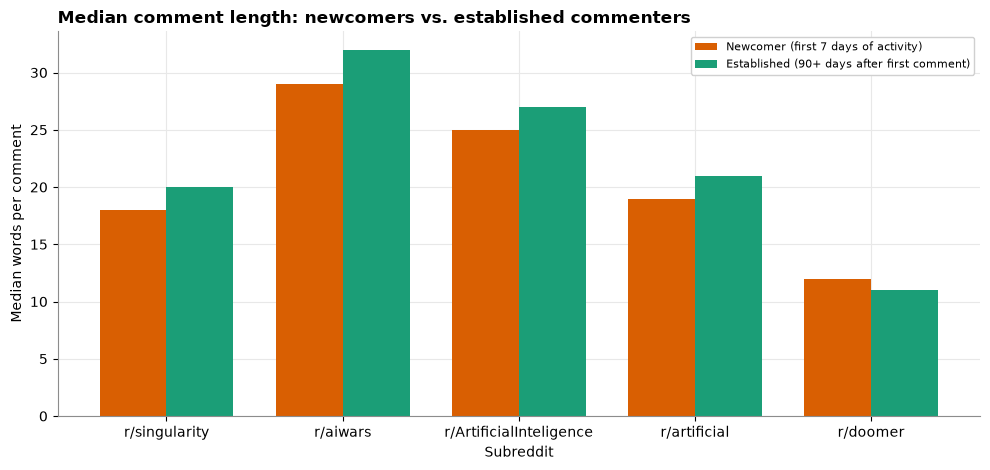

> **Answer.** Newcomers write shorter comments in 4 of 5 big communities.

In [92]:
Q("H13: Do newcomers write differently from established users? (comment length)")
first_dt = nd.groupby("author")["dt"].min(); nd2 = nd[["author", "subreddit", "dt", "n_words"]].copy(); nd2["age"] = (nd2["dt"] - nd2["author"].map(first_dt)).dt.days
nd2["first_seen"] = nd2["author"].map(first_dt); grp = np.select([(nd2.first_seen >= "2024-10-01") & (nd2.age <= 7), nd2.age >= 90], ["Newcomer (first 7 days)", "Established (90+ days)"], "mid")
nd2["grp"] = grp; ng = nd2[nd2.grp != "mid"].groupby(["subreddit", "grp"])["n_words"].median().unstack().reindex(index=BIG)
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(ng)); w = .38
ax.bar(x - w/2, ng["Newcomer (first 7 days)"], w, color=C2, label="Newcomer (first 7 days of activity)"); ax.bar(x + w/2, ng["Established (90+ days)"], w, color=C1, label="Established (90+ days after first comment)")
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in ng.index])
done(ax, "Median comment length: newcomers vs. established commenters", "Subreddit", "Median words per comment", loc="upper right")
H13_len = (ng["Newcomer (first 7 days)"] < ng["Established (90+ days)"]).sum(); A(f"Newcomers write shorter comments in {H13_len} of {len(ng)} big communities.")

#### Q37. Bot check: which of the most active submitters post like machines?

,author,posts,hour_entropy_bits,unique_title_ratio,external_link_%,median_gap_h,top_domain,communities
0,MetaKnowing,1051,3.52,0.83,21.98,0.57,i.redd.it,3
1,Excellent-Target-847,498,2.23,0.54,0.20,21.67,self.artificial,2
2,Gothsim10,494,4.05,0.99,36.23,1.60,v.redd.it,1
3,IlustriousTea,490,4.40,0.99,35.31,4.97,i.redd.it,1
4,katxwoods,252,3.46,0.78,27.38,4.88,i.redd.it,3
5,steves1189,231,2.73,0.96,0.00,12.02,self.artificialinteligence,1
6,SharpCartographer831,227,4.32,0.96,83.70,13.56,youtube.com,1
7,Ok_Town9648,212,3.24,0.14,99.06,0.19,devex.com,1
8,MPM_SOLVER,211,3.94,0.97,1.90,13.66,self.aiwars,4
9,Wiskkey,207,3.59,0.98,69.57,15.01,i.redd.it,3


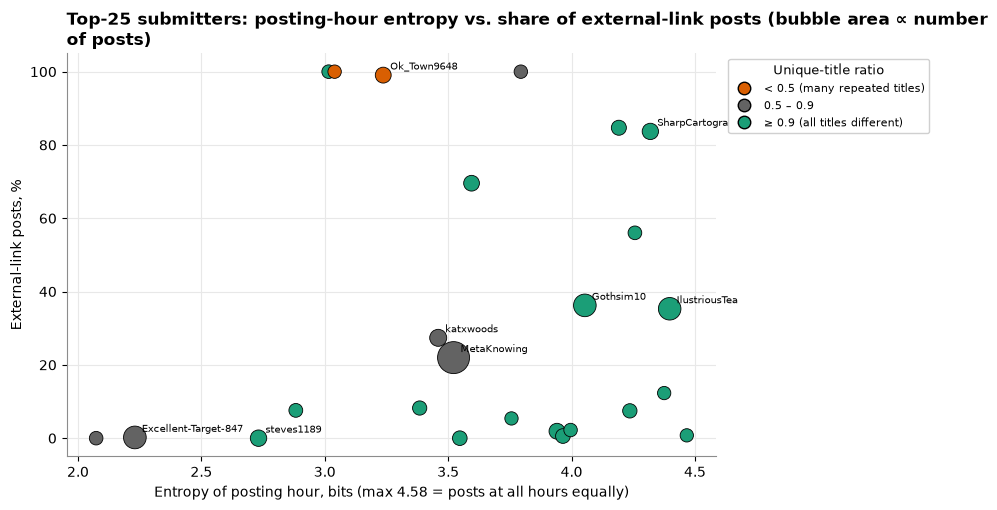

> **Answer.** 8 of the top-25 submitters are **candidates** for automated posting (many repeated titles, or posts spread evenly over all 24 hours, which a person who sleeps cannot do). The strongest signal is the repeated-title group (orange). Accounts with only high entropy and unique titles may simply be very active news curators. They should be inspected before modelling.

In [93]:
Q("Bot check: which of the most active submitters post like machines?")
top_auth = sb[~sb.deleted_author].author.value_counts().head(25).index; rows = []
for a in top_auth:
    g = sb[sb.author == a].sort_values("dt"); gaps = g.dt.diff().dt.total_seconds().dropna() / 3600; h = np.bincount(g.hour, minlength=24) / len(g); h = h[h > 0]
    rows.append({"author": a, "posts": len(g), "hour_entropy_bits": -(h * np.log2(h)).sum(), "unique_title_ratio": g.title.nunique() / len(g),
                 "external_link_%": (g.post_type == "external link").mean() * 100, "median_gap_h": gaps.median() if len(gaps) else np.nan, "top_domain": g.dom.mode().iat[0], "communities": g.subreddit.nunique()})
bots = pd.DataFrame(rows); display(bots.round(2).head(12))
cls = np.select([bots.unique_title_ratio < .5, bots.unique_title_ratio < .9], ["< 0.5 (many repeated titles)", "0.5 – 0.9"], "≥ 0.9 (all titles different)"); cc_ = {"< 0.5 (many repeated titles)": C2, "0.5 – 0.9": GREY, "≥ 0.9 (all titles different)": C1}
fig, ax = plt.subplots(figsize=(9.5, 5.2)); sizes = 30 + 500 * bots.posts / bots.posts.max()
ax.scatter(bots.hour_entropy_bits, bots["external_link_%"], s=sizes, c=[cc_[c] for c in cls], edgecolor="black", linewidth=.6)
for _, r in bots.head(8).iterrows(): ax.annotate(r.author, (r.hour_entropy_bits, r["external_link_%"]), fontsize=7, xytext=(5, 4), textcoords="offset points")
done(ax, "Top-25 submitters: posting-hour entropy vs. share of external-link posts (bubble area ∝ number of posts)", "Entropy of posting hour, bits (max 4.58 = posts at all hours equally)", "External-link posts, %",
     handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markeredgecolor="black", markersize=9, label=l) for l, c in cc_.items()], ltitle="Unique-title ratio", outside=True)
nb_ = int(((bots.unique_title_ratio < .5) | (bots.hour_entropy_bits > 4.2)).sum()); A(f"{nb_} of the top-25 submitters are **candidates** for automated posting (many repeated titles, or posts spread evenly over all 24 hours, which a person who sleeps cannot do). "
  "The strongest signal is the repeated-title group (orange). Accounts with only high entropy and unique titles may simply be very active news curators. They should be inspected before modelling.")

#### Q38. Are there domains pushed by a single account? (suspected promotional posting, weekly)

,n,top_share,top_author
dom,,,
wifi4softs.com,137,0.992701,Interesting-Draw2064
pcguide.com,62,0.693548,Tiny-Independent273


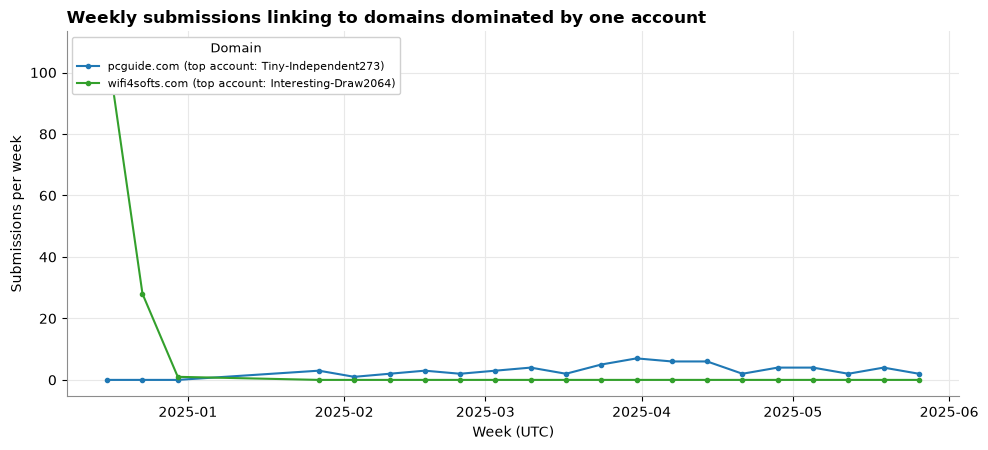

> **Answer.** Domains posted mostly by one account (≥ 60% of ≥ 50 posts): wifi4softs.com — 137 posts, 99% by Interesting-Draw2064; pcguide.com — 62 posts, 69% by Tiny-Independent273. The dominant domain appears as a short burst and then stops (typical spam that gets banned); a domain with a steady low weekly count looks like a promotional feed.

In [94]:
Q("Are there domains pushed by a single account? (suspected promotional posting, weekly)")
nt = sb[sb.post_type == "external link"]; dg = nt.groupby("dom").agg(n=("id", "size"), top_share=("author", lambda s: s.value_counts(normalize=True).iloc[0]), top_author=("author", lambda s: s.value_counts().index[0]))
sus = dg[(dg.n >= 50) & (dg.top_share >= .6)].sort_values("n", ascending=False).head(4); display(sus)
if len(sus):
    wkd = nt[nt.dom.isin(sus.index)].groupby([nt.dt.dt.to_period("W").dt.to_timestamp(), "dom"]).size().unstack(fill_value=0)
    fig, ax = plt.subplots(figsize=(10, 4.6))
    for i, d_ in enumerate(wkd.columns): ax.plot(wkd.index, wkd[d_], color=PAIRED_D[i], marker="o", ms=3, label=f"{d_} (top account: {sus.top_author[d_]})")
    done(ax, "Weekly submissions linking to domains dominated by one account", "Week (UTC)", "Submissions per week", ltitle="Domain", loc="upper left")
    A("Domains posted mostly by one account (≥ 60% of ≥ 50 posts): " + "; ".join(f"{d_} — {int(r.n)} posts, {r.top_share*100:.0f}% by {r.top_author}" for d_, r in sus.iterrows())
      + ". The dominant domain appears as a short burst and then stops (typical spam that gets banned); a domain with a steady low weekly count looks like a promotional feed.")
else:
    A("No external domain is dominated by a single account in this dataset.")

#### Q39. Where do the posts point to? (top linked domains by community)

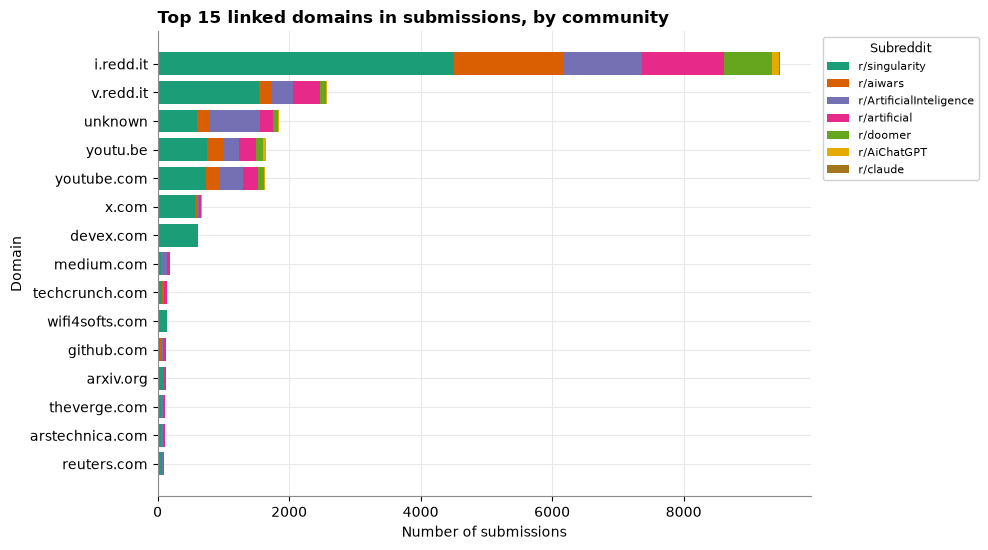

> **Answer.** Reddit-hosted images and videos are the largest group (44% of non-text posts), followed by YouTube and X; news and research sites (techcrunch, arxiv, theverge, reuters) are a small minority. r/singularity shares most of the images; 'unknown' are posts without a parsable domain.

In [95]:
Q("Where do the posts point to? (top linked domains by community)")
nt2 = sb[sb.post_type != "text"]; topd = nt2.dom.value_counts().head(15).index
pvd = nt2[nt2.dom.isin(topd)].groupby(["dom", "subreddit"]).size().unstack(fill_value=0).reindex(index=topd, columns=order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5.6)); pos = stacked(ax, pvd, PAL, horizontal=True, width=.8); ax.set_yticks(pos); ax.set_yticklabels(pvd.index); ax.invert_yaxis()
done(ax, "Top 15 linked domains in submissions, by community", "Number of submissions", "Domain", ltitle="Subreddit", outside=True)
A(f"Reddit-hosted images and videos are the largest group ({nt2.dom.isin(['i.redd.it', 'v.redd.it']).mean()*100:.0f}% of non-text posts), followed by YouTube and X; news and research sites (techcrunch, arxiv, theverge, reuters) are a small minority. "
  "r/singularity shares most of the images; 'unknown' are posts without a parsable domain.")

#### Q40. Does moderation or deletion change over time? (deleted and removed content by month)

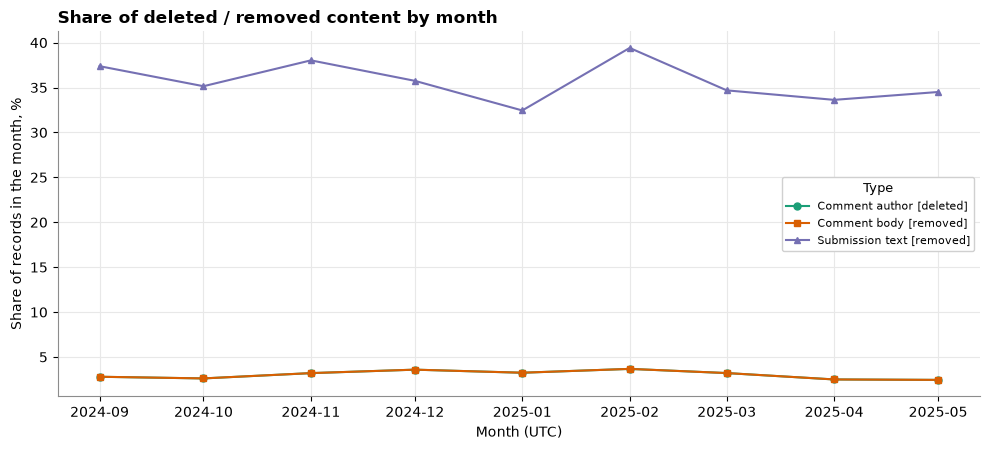

> **Answer.** Removed submission text moves between 32% and 39% of posts (highest in 2025-02) without a trend; deleted comment authors and removed comment bodies stay near 3.0% (the two lines lie on top of each other, because a deleted comment usually loses both). Moderation is stable over the period.

In [96]:
Q("Does moderation or deletion change over time? (deleted and removed content by month)")
dl = pd.DataFrame({"Comment author [deleted]": cm.groupby("month")["deleted_author"].mean() * 100, "Comment body [removed]": cm.groupby("month")["removed_body"].mean() * 100,
                   "Submission text [removed]": sb.groupby("month")["selftext_removed"].mean() * 100})
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, c in enumerate(dl.columns): ax.plot(dl.index, dl[c], color=[C1, C2, "#7570b3"][i], marker=["o", "s", "^"][i], ms=5, label=c)
done(ax, "Share of deleted / removed content by month", "Month (UTC)", "Share of records in the month, %", ltitle="Type", loc="best")
A(f"Removed submission text moves between {dl.iloc[:, 2].min():.0f}% and {dl.iloc[:, 2].max():.0f}% of posts (highest in {dl.iloc[:, 2].idxmax():%Y-%m}) without a trend; deleted comment authors and removed comment bodies stay near {dl.iloc[:, 0].mean():.1f}% "
  "(the two lines lie on top of each other, because a deleted comment usually loses both). Moderation is stable over the period.")

#### Q41. Does the balance of attention between communities shift? (share of comments by month)

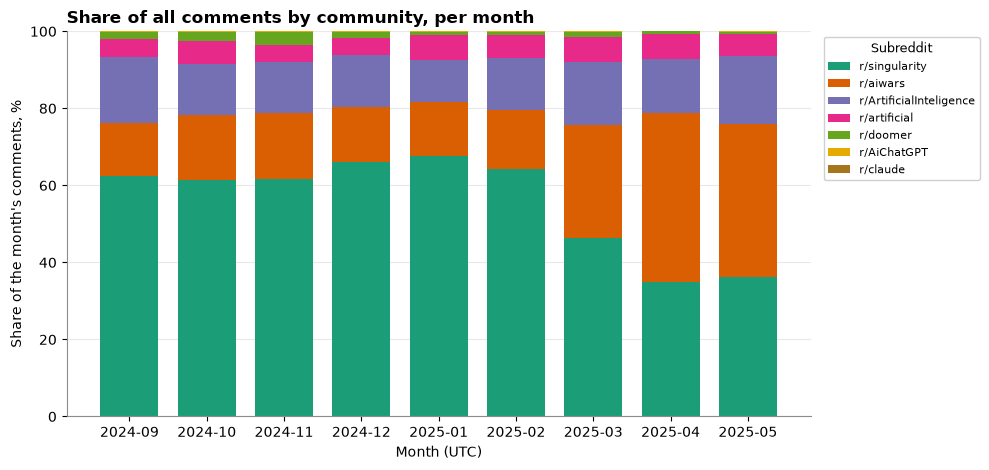

> **Answer.** Biggest gain: r/aiwars (+26.0 pp, from 13.7% to 39.7%); biggest loss: r/singularity (-26.2 pp).

In [97]:
Q("Does the balance of attention between communities shift? (share of comments by month)")
shr = pvc.div(pvc.sum(1), axis=0) * 100; fig, ax = plt.subplots(figsize=(10, 4.8)); pos = stacked(ax, shr, PAL); ax.set_xticks(pos); ax.set_xticklabels(shr.index.strftime("%Y-%m")); ax.set_ylim(0, 100)
done(ax, "Share of all comments by community, per month", "Month (UTC)", "Share of the month's comments, %", ltitle="Subreddit", outside=True)
dd = (shr.iloc[-1] - shr.iloc[0]); A(f"Biggest gain: r/{dd.idxmax()} ({dd.max():+.1f} pp, from {shr.iloc[0][dd.idxmax()]:.1f}% to {shr.iloc[-1][dd.idxmax()]:.1f}%); biggest loss: r/{dd.idxmin()} ({dd.min():+.1f} pp).")

## 5. Merging submissions and comments (H12, H13)
**How and why.** Every comment has `link_id = "t3_" + <submission id>`. We create `post_id` (the id without the `t3_` prefix) and map the submission's timestamp onto each comment with a **left join from comments**: comments of posts published before our window (or removed) are kept but flagged `matched = False`. This lets us (a) check how complete the collection is, (b) compare collected vs. Reddit-reported comment counts, (c) measure the **lifecycle of a discussion** (delay between post and comment), and (d) compute a **relative score** of a comment *inside its thread* (percentile rank of its score among all comments of the same post; 0.5 = typical), which removes the "popular post" effect from comment-level comparisons.
**H12 (new).** Early commenters win: the earlier a comment is written, the higher its relative score.

In [98]:
cm["post_id"] = cm["link_id"].astype(str).str.replace("t3_", "", regex=False)
sbi = sb.set_index("id"); cm["post_dt"] = cm["post_id"].map(sbi["dt"]); cm["matched"] = cm["post_dt"].notna()
cm["delay_h"] = (cm["dt"] - cm["post_dt"]).dt.total_seconds() / 3600
observed = cm.groupby("post_id").size().rename("observed"); sb["observed"] = sb["id"].map(observed).fillna(0).astype(int)
cm["pct"] = cm.groupby("post_id")["score"].rank(pct=True); cm.loc[cm.post_id.map(observed) < 10, "pct"] = np.nan     # only threads with >= 10 comments
print(f"comments whose post is in the submissions table: {cm.matched.mean()*100:.1f}% | comments with a relative score: {cm.pct.notna().mean()*100:.1f}%")

comments whose post is in the submissions table: 97.8% | comments with a relative score: 96.0%


#### Q42. How complete is the merge? (share of comments whose post is in the submissions table)

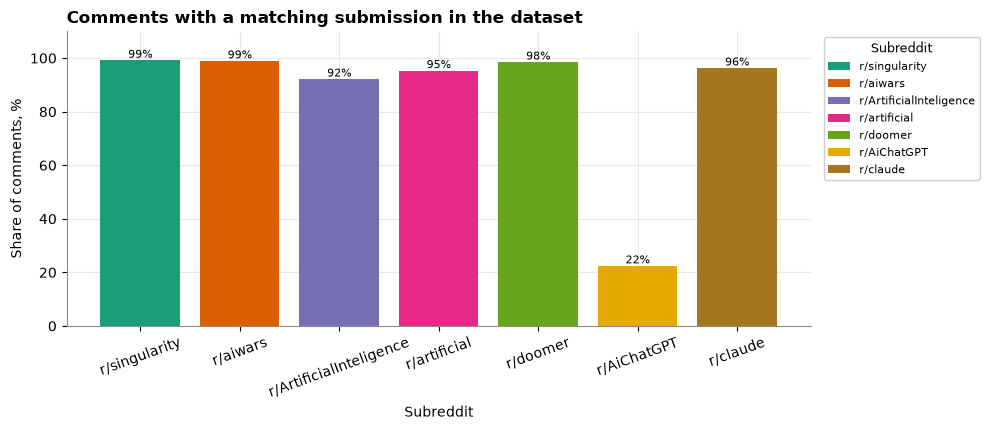

> **Answer.** 97.8% of comments have their post in the table. The weakest coverage is r/AiChatGPT (22%), so its post-level statistics rest on a small matched part.

In [99]:
Q("How complete is the merge? (share of comments whose post is in the submissions table)")
cov = (cm.groupby("subreddit")["matched"].mean() * 100).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4.4)); ax.bar([f"r/{s}" for s in cov.index], cov.values, color=[PAL[s] for s in cov.index], label="_")
for i, v in enumerate(cov.values): ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=8)
ax.set_ylim(0, 110); ax.tick_params(axis="x", rotation=20)
done(ax, "Comments with a matching submission in the dataset", "Subreddit", "Share of comments, %", handles=sub_handles(order), ltitle="Subreddit", outside=True)
A(f"{cm.matched.mean()*100:.1f}% of comments have their post in the table. The weakest coverage is r/{cov.idxmin()} ({cov.min():.0f}%), so its post-level statistics rest on a small matched part.")

#### Q43. Is the comment collection complete? (comments we hold vs. comments Reddit reports per post)

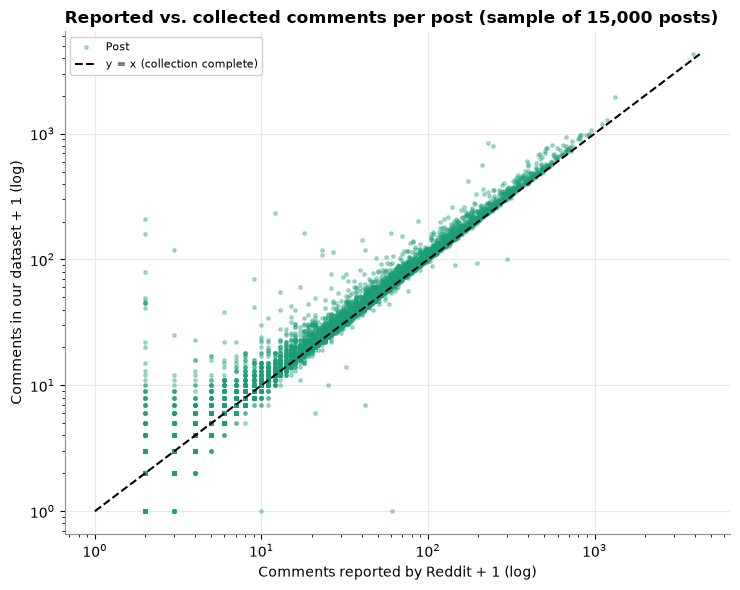

> **Answer.** We hold 110% of the comments that Reddit reports. More than 100% is possible: `num_comments` was saved when the post was collected, while comments kept arriving afterwards, so most points lie on or slightly above the diagonal. The collection is complete; the reported count is the stale one.

In [100]:
Q("Is the comment collection complete? (comments we hold vs. comments Reddit reports per post)")
pp = sb[(sb.num_comments > 0)]; pp = pp.sample(min(len(pp), 15000), random_state=3)
fig, ax = plt.subplots(figsize=(7.5, 6)); ax.scatter(pp.num_comments + 1, pp.observed + 1, s=6, color=C1, alpha=.35, label="Post")
lim = [1, max(pp.num_comments.max(), pp.observed.max()) + 1]; ax.plot(lim, lim, color="black", ls="--", label="y = x (collection complete)")
ax.set_xscale("log"); ax.set_yscale("log")
done(ax, "Reported vs. collected comments per post (sample of 15,000 posts)", "Comments reported by Reddit + 1 (log)", "Comments in our dataset + 1 (log)", loc="upper left")
r_ = (sb.observed.sum() / sb.num_comments.sum()); A(f"We hold {r_*100:.0f}% of the comments that Reddit reports. More than 100% is possible: `num_comments` was saved when the post was collected, while comments kept arriving afterwards, "
  "so most points lie on or slightly above the diagonal. The collection is complete; the reported count is the stale one.")

#### Q44. How fast does a discussion develop? (delay between a post and its comments)

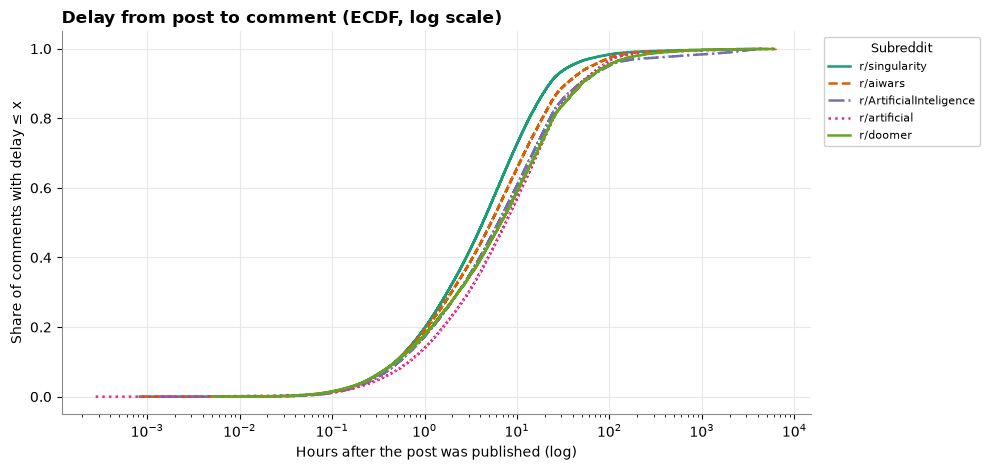

> **Answer.** Median delay: r/singularity 4.2 h, r/aiwars 5.2 h, r/ArtificialInteligence 6.3 h, r/artificial 7.5 h, r/doomer 6.7 h. Most discussion happens within the first day, with a long tail of late replies.

In [101]:
Q("How fast does a discussion develop? (delay between a post and its comments)")
mm = cm[cm.matched & (cm.delay_h > 0)]; fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ecdf(ax, mm.loc[mm.subreddit == s, "delay_h"], color=PAL[s], ls=LS[s], lw=1.8, label=f"r/{s}")
ax.set_xscale("log"); done(ax, "Delay from post to comment (ECDF, log scale)", "Hours after the post was published (log)", "Share of comments with delay ≤ x", ltitle="Subreddit", outside=True)
md2 = mm.groupby("subreddit")["delay_h"].median().reindex(BIG); A("Median delay: " + ", ".join(f"r/{s} {md2[s]:.1f} h" for s in BIG) + ". Most discussion happens within the first day, with a long tail of late replies.")

#### Q45. H12: Do early comments earn higher relative scores? (mean percentile of the score inside the thread, by delay)

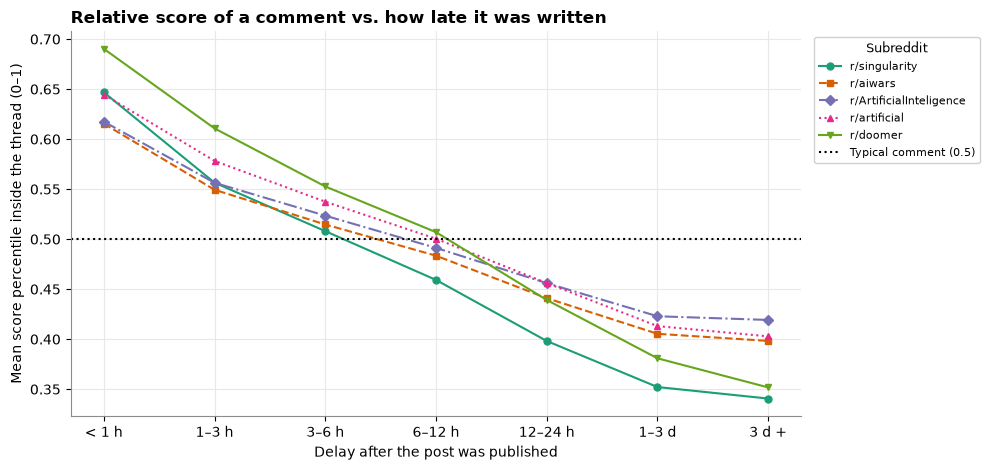

> **Verdict H12.** comments in the first hour have a mean relative score of 0.64 vs 0.38 after 3 days (difference +0.26) → supported.

In [102]:
Q("H12: Do early comments earn higher relative scores? (mean percentile of the score inside the thread, by delay)")
act_ = cm[cm.matched & (cm.delay_h > 0) & cm.pct.notna()]; labs = ["< 1 h", "1–3 h", "3–6 h", "6–12 h", "12–24 h", "1–3 d", "3 d +"]
bk = pd.cut(act_.delay_h, [0, 1, 3, 6, 12, 24, 72, 1e9], labels=labs); g = act_.assign(b=bk).groupby(["b", "subreddit"])["pct"].mean().unstack().reindex(index=labs)
fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ax.plot(range(len(labs)), g[s], color=PAL[s], ls=LS[s], marker=MK[s], ms=5, label=f"r/{s}")
ax.axhline(.5, color="black", ls=":", label="Typical comment (0.5)"); ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs)
done(ax, "Relative score of a comment vs. how late it was written", "Delay after the post was published", "Mean score percentile inside the thread (0–1)", ltitle="Subreddit", outside=True)
drop = (g.iloc[0][BIG] - g.iloc[-1][BIG]).mean(); VERDICT("H12", f"comments in the first hour have a mean relative score of {g.iloc[0][BIG].mean():.2f} vs {g.iloc[-1][BIG].mean():.2f} after 3 days (difference {drop:+.2f}) → " + ("supported." if drop > .05 else "weak / not supported."))

#### Q46. H13: Do newcomers earn lower relative scores than established users?

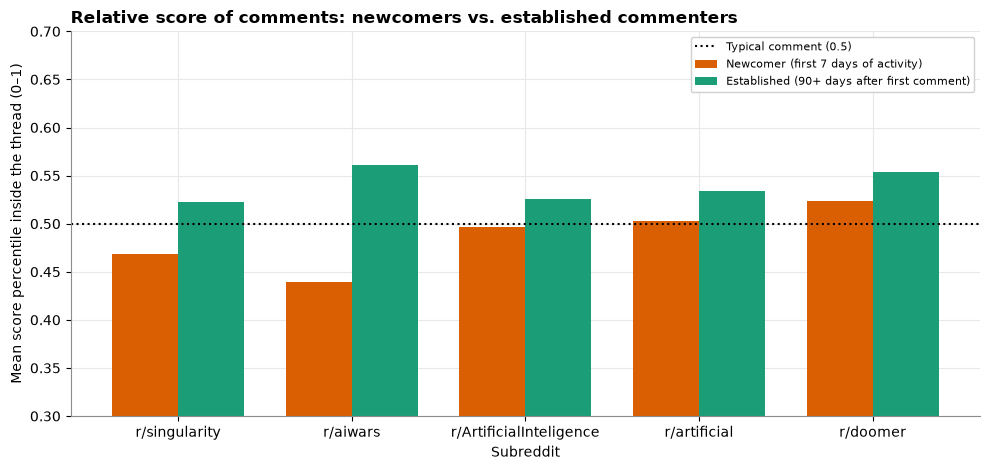

> **Verdict H13.** newcomers write shorter comments in 4 of 5 big communities, and their mean relative score is 0.053 lower than that of established users → supported.

In [103]:
Q("H13: Do newcomers earn lower relative scores than established users?")
nd2["pct"] = cm["pct"].reindex(nd2.index); gs = nd2[(nd2.grp != "mid") & nd2.pct.notna()].groupby(["subreddit", "grp"])["pct"].mean().unstack().reindex(index=BIG)
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(gs)); w = .38
ax.bar(x - w/2, gs["Newcomer (first 7 days)"], w, color=C2, label="Newcomer (first 7 days of activity)"); ax.bar(x + w/2, gs["Established (90+ days)"], w, color=C1, label="Established (90+ days after first comment)")
ax.axhline(.5, color="black", ls=":", label="Typical comment (0.5)"); ax.set_ylim(.3, .7); ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in gs.index])
done(ax, "Relative score of comments: newcomers vs. established commenters", "Subreddit", "Mean score percentile inside the thread (0–1)", loc="upper right")
dsc = (gs["Established (90+ days)"] - gs["Newcomer (first 7 days)"]).mean()
VERDICT("H13", f"newcomers write shorter comments in {H13_len} of {len(ng)} big communities, and their mean relative score is {dsc:.3f} lower than that of established users → " + ("supported." if (H13_len >= len(ng) / 2 and dsc > .01) else "partly supported." if (H13_len >= len(ng) / 2 or dsc > .01) else "not supported."))

## 6. Language: how do the communities talk? (H14, H15, H16)
**Method and limits.** Language statistics use a **stratified sample** (up to 50,000 non-removed comments per community; small communities in full), so large communities do not drown small ones. Monthly curves for "all communities" are re-weighted to the real number of comments per month and community. Lexicons are small hand-written keyword lists: they miss sarcasm and negation, and "god" also occurs in "oh my god" — we therefore compare *rates between communities and months*, where such noise is roughly constant, and treat results as signals.
**H14 (new).** The DeepSeek shock: after Jan 2025 DeepSeek takes a lasting share of voice from ChatGPT. **H15 (new).** Hostile comments are rewarded in debate communities and punished elsewhere. **H16 (new).** Longer comments earn higher relative scores.

In [104]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
tx = pd.concat([g.sample(min(len(g), 50000), random_state=2) for _, g in valid.groupby("subreddit")]).copy()
tx["text_l"] = tx["body"].str.lower(); tx["pct"] = cm["pct"].reindex(tx.index)
TRUE_N = valid.groupby(["month", "subreddit"]).size().unstack().reindex(columns=order)
def monthly_rate(col, per=1000):
    g = tx.groupby(["month", "subreddit"])[col].mean().unstack().reindex(columns=order); w = TRUE_N.reindex(index=g.index, columns=order)
    return (g * w).sum(1, min_count=1) / w.where(g.notna()).sum(1) * per
LEX = {
 "f_threat": r"\b(?:extinction|existential|kill(?:s|ed|ing)?|weapons?|bioweapons?|nukes?|nuclear|terminators?|skynet|takeover|annihilat\w*)\b",
 "f_slop":   r"\b(?:slop|enshittif\w*|dead internet|spam\w*|bots?|fake|garbage|junk|low[- ]effort)\b",
 "f_relig":  r"\b(?:god|gods|goddess|souls?|pray\w*|worship\w*|faith|salvation|messiah|prophe\w*|heaven|divine|sacred|religio\w*|rapture|apocalyp\w*|bless\w*|church|cult)\b",
 "f_tech":   r"\b(?:weights?|prompts?|tokens?|benchmarks?|parameters?|fine[- ]?tun\w*|inference|gpus?|context window|training data|rlhf|transformers?)\b",
 "f_fatal":  r"\b(?:inevitabl\w*|unavoidabl\w*|fate|destiny|doomed|no way to stop|nothing (?:we|you|anyone) can do|too late|out of (?:our|my|anyone's) control|can't be stopped|cannot be stopped|can't stop (?:it|this|ai|them))\b",
 "f_tool":   r"\b(?:midjourney|stable diffusion|dall-?e|chat ?gpt|generators?|diffusion|image models?|ai art|ai images?|sora|flux)\b",
 "f_people": r"\b(?:prompters?|ai bros?|tech ?bros?|corporations?|billionaires?|ceos?|oligarchs?|silicon valley|big tech)\b",
 "f_accuse": r"(?:sounds? like (?:chat ?gpt|an? (?:ai|llm|bot))|written by (?:ai|chat ?gpt)|chat ?gpt wrote|you're a bot|are you a bot|this (?:is|was) (?:a )?bot)",
 "f_slang":  r"\b(?:lol|lmao|imo|imho|tbh|idk|ngl|smh|wtf|bruh|omg)\b"}
BR = {"ChatGPT / OpenAI": r"\b(?:chat ?gpt|gpt-?[0-9]\w*|openai|o1|o3|sora)\b", "Claude / Anthropic": r"\b(?:claude|anthropic|sonnet|opus)\b",
      "Gemini / Google": r"\b(?:gemini|bard|google)\b", "DeepSeek": r"\bdeepseek\b", "Llama / Meta": r"\b(?:llama|meta)\b", "Grok / xAI": r"\b(?:grok|xai)\b"}
for col, pat in {**LEX, **{"b_" + k: v for k, v in BR.items()}}.items(): tx[col] = tx.text_l.str.contains(pat, regex=True)
sa = pd.concat([g.sample(min(len(g), 25000), random_state=3) for _, g in tx.groupby("subreddit")]).copy()
sc_ = [sia.polarity_scores(t[:1000]) for t in sa["body"]]; sa["compound"] = [d["compound"] for d in sc_]; sa["neg"] = [d["neg"] for d in sc_]
print(f"language sample {len(tx):,} comments | sentiment sample {len(sa):,}")

language sample 222,314 comments | sentiment sample 122,314


#### Q47. How long are comments in each community?

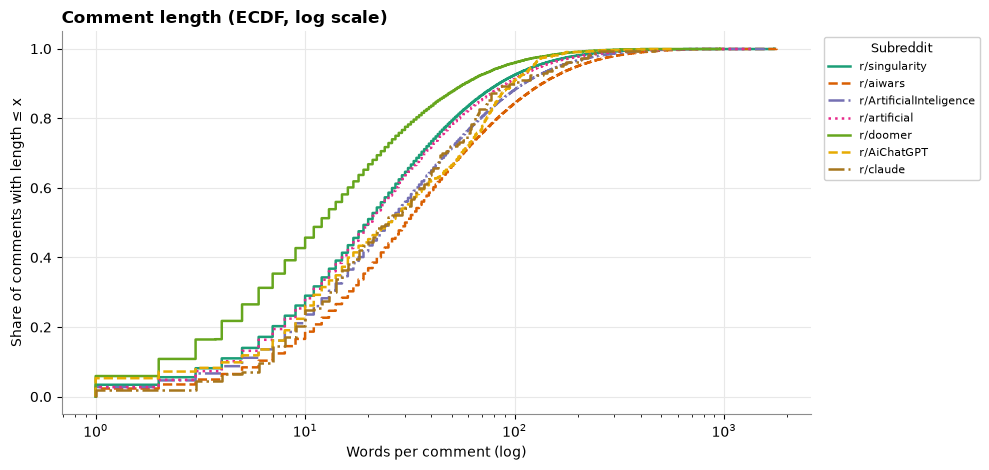

> **Answer.** Median words per comment: r/singularity 20, r/aiwars 30, r/ArtificialInteligence 25, r/artificial 20, r/doomer 12, r/AiChatGPT 25, r/claude 24. The longest-writing community is r/aiwars, the shortest r/doomer.

In [105]:
Q("How long are comments in each community?")
fig, ax = plt.subplots(figsize=(10, 4.8))
for s in order: ecdf(ax, valid.loc[valid.subreddit == s, "n_words"].clip(lower=1), color=PAL[s], ls=LS[s], lw=1.8, label=f"r/{s}")
ax.set_xscale("log"); done(ax, "Comment length (ECDF, log scale)", "Words per comment (log)", "Share of comments with length ≤ x", ltitle="Subreddit", outside=True)
mw = valid.groupby("subreddit")["n_words"].median().reindex(order); A("Median words per comment: " + ", ".join(f"r/{s} {mw[s]:.0f}" for s in order) + f". The longest-writing community is r/{mw.idxmax()}, the shortest r/{mw.idxmin()}.")

#### Q48. H16: Do longer comments earn higher relative scores?

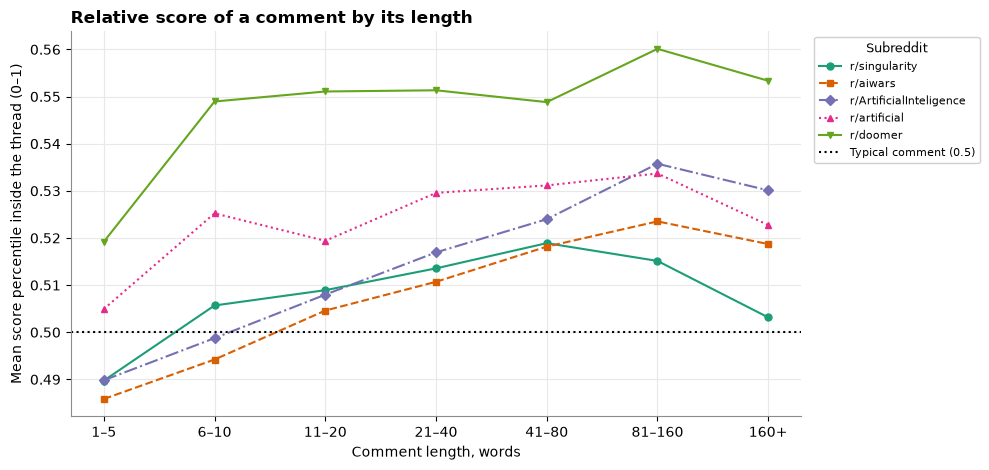

> **Verdict H16.** comments longer than 40 words have a mean relative score +0.02 higher than comments of up to 10 words → weak / not supported.

In [106]:
Q("H16: Do longer comments earn higher relative scores?")
lb = pd.cut(valid.n_words, [0, 5, 10, 20, 40, 80, 160, 10**6], labels=["1–5", "6–10", "11–20", "21–40", "41–80", "81–160", "160+"]); vv = valid.assign(lb=lb, pct=cm["pct"].reindex(valid.index))
g = vv.dropna(subset=["pct"]).groupby(["lb", "subreddit"])["pct"].mean().unstack().reindex(columns=order); fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ax.plot(range(len(g)), g[s], color=PAL[s], ls=LS[s], marker=MK[s], ms=5, label=f"r/{s}")
ax.axhline(.5, color="black", ls=":", label="Typical comment (0.5)"); ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
done(ax, "Relative score of a comment by its length", "Comment length, words", "Mean score percentile inside the thread (0–1)", ltitle="Subreddit", outside=True)
gain = (g.iloc[-3:][BIG].mean().mean() - g.iloc[:2][BIG].mean().mean()); VERDICT("H16", f"comments longer than 40 words have a mean relative score {gain:+.2f} higher than comments of up to 10 words → " + ("supported." if gain > .05 else "weak / not supported."))

#### Q49. How emotional is the language in each community? (VADER sentiment of comments)

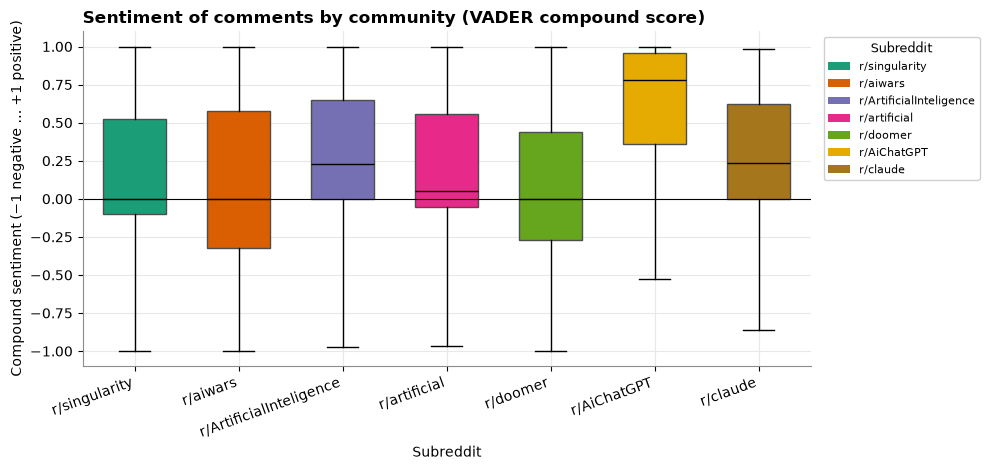

> **Answer.** Most positive on average: r/AiChatGPT (+0.60); least positive: r/doomer (+0.07). Every community is slightly positive on average (VADER sees politeness words), so the useful signal is the spread: r/aiwars and r/doomer have the widest boxes towards negative values.

In [107]:
Q("How emotional is the language in each community? (VADER sentiment of comments)")
dat = [sa.loc[sa.subreddit == s, "compound"].to_numpy() for s in order]; fig, ax = plt.subplots(figsize=(10, 4.8))
bp = ax.boxplot(dat, patch_artist=True, showfliers=False, widths=.6, medianprops=dict(color="black"))
for p_, s in zip(bp["boxes"], order): p_.set_facecolor(PAL[s]); p_.set_edgecolor("#4d4d4d")
ax.axhline(0, color="black", lw=.8); ax.set_xticklabels([f"r/{s}" for s in order], rotation=20, ha="right")
done(ax, "Sentiment of comments by community (VADER compound score)", "Subreddit", "Compound sentiment (−1 negative … +1 positive)", handles=sub_handles(order), ltitle="Subreddit", outside=True)
ms_ = sa.groupby("subreddit")["compound"].mean().reindex(order); A(f"Most positive on average: r/{ms_.idxmax()} ({ms_.max():+.2f}); least positive: r/{ms_.idxmin()} ({ms_.min():+.2f}). Every community is slightly positive on average (VADER sees politeness words), "
  "so the useful signal is the spread: r/aiwars and r/doomer have the widest boxes towards negative values.")

#### Q50. Does the mood change over time? (mean sentiment by month)

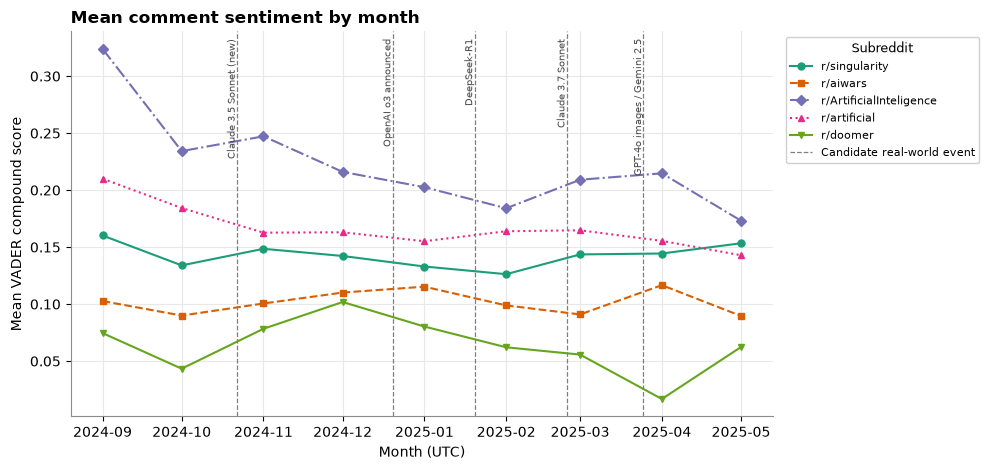

> **Answer.** Spearman trend of monthly sentiment: r/singularity -0.03, r/aiwars -0.10, r/ArtificialInteligence -0.83, r/artificial -0.67, r/doomer -0.33. r/ArtificialInteligence, r/artificial become steadily less positive; the other communities have no trend. The month-to-month changes are small (a few hundredths), the differences between communities are much larger than the changes over time.

In [108]:
Q("Does the mood change over time? (mean sentiment by month)")
sm = sa.groupby(["month", "subreddit"])["compound"].mean().unstack().reindex(columns=order); fig, ax = plt.subplots(figsize=(10, 4.8))
for s in BIG: ax.plot(sm.index, sm[s], color=PAL[s], ls=LS[s], marker=MK[s], ms=5, label=f"r/{s}")
add_events(ax, sm.index.min(), sm.index.max())
done(ax, "Mean comment sentiment by month", "Month (UTC)", "Mean VADER compound score", ltitle="Subreddit", outside=True)
tr = {s: spearmanr(np.arange(len(sm)), sm[s].values)[0] for s in BIG}; A("Spearman trend of monthly sentiment: " + ", ".join(f"r/{s} {r:+.2f}" for s, r in tr.items()) + ". "
  + ", ".join(f"r/{s}" for s, r in tr.items() if r <= -.5) + " become steadily less positive; the other communities have no trend. The month-to-month changes are small (a few hundredths), "
  "the differences between communities are much larger than the changes over time.")

#### H8 extension: do releases change the *mood*, not only the volume?
The event-impact heat map in Part 2 showed that events change how *much* people write. Here we check whether they also change *how* people feel: the mean VADER sentiment in the 3 days after each event is compared with the 14 days before (sentiment sample, up to 25,000 comments per community).

#### Q51. Does the mood of r/aiwars move around major AI releases? (daily mean sentiment, 7-day rolling mean)

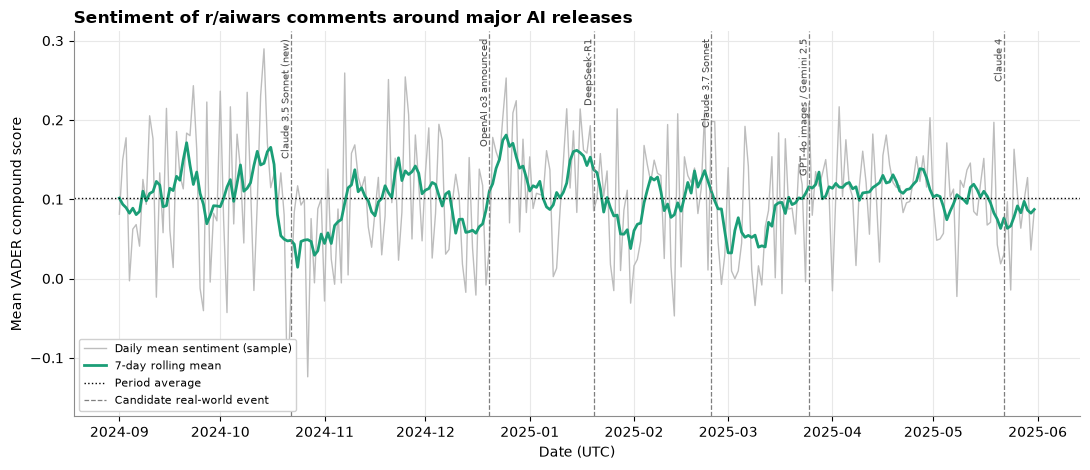

> **Answer.** The 7-day mean of r/aiwars stays between +0.01 and +0.18 (about 61 sampled comments per day). The daily line jumps a lot, but the dips and peaks do not line up with the release lines in a regular way.

In [109]:
Q("Does the mood of r/aiwars move around major AI releases? (daily mean sentiment, 7-day rolling mean)")
aw_s = sa[sa.subreddit == "aiwars"].groupby("date")["compound"].agg(["mean", "size"]).reindex(idx_days)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(aw_s.index, aw_s["mean"], color=LGREY, lw=1, label="Daily mean sentiment (sample)")
ax.plot(aw_s.index, aw_s["mean"].rolling(7, min_periods=3, center=True).mean(), color=C1, lw=2, label="7-day rolling mean")
ax.axhline(sa.loc[sa.subreddit == "aiwars", "compound"].mean(), color="black", ls=":", lw=1, label="Period average")
add_events(ax, START, END)
done(ax, "Sentiment of r/aiwars comments around major AI releases", "Date (UTC)", "Mean VADER compound score", loc="lower left")
sm7 = aw_s["mean"].rolling(7, min_periods=3, center=True).mean()
A(f"The 7-day mean of r/aiwars stays between {sm7.min():+.2f} and {sm7.max():+.2f} (about {aw_s['size'].median():.0f} sampled comments per day). The daily line jumps a lot, "
  "but the dips and peaks do not line up with the release lines in a regular way.")

#### Q52. H8: Do events shift the sentiment of each community? (mean sentiment in the 3 days after − 14 days before)

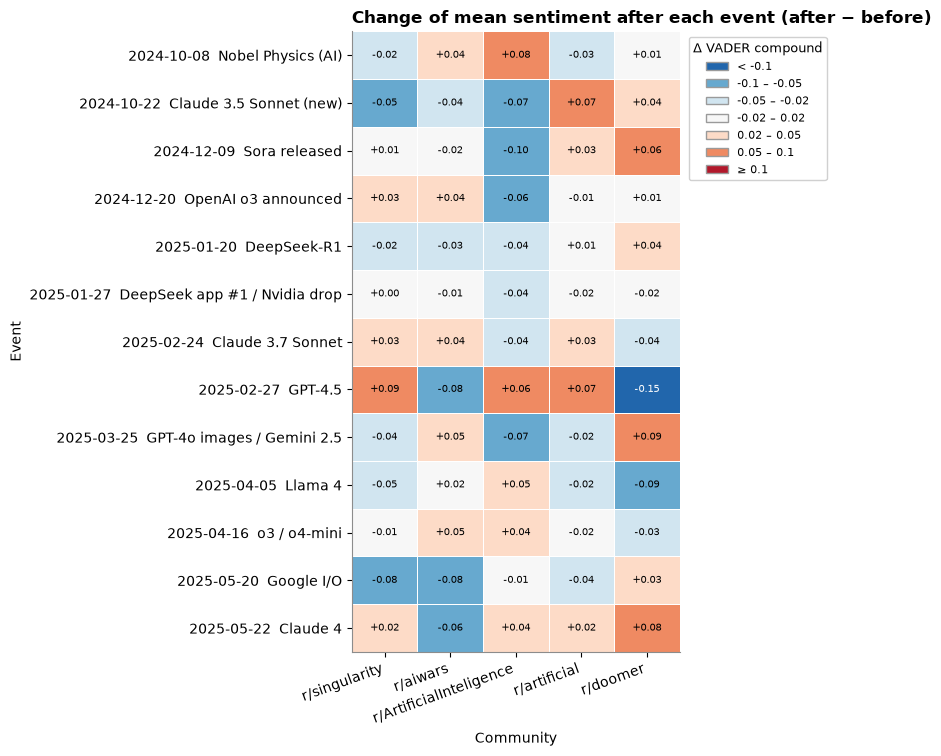

> **Answer.** Only 19 of 65 event × community cells move by more than 0.05; most changes are within ±0.05, which is the size of day-to-day noise. Releases change the **volume** of discussion (Part 2) much more than its **mood** — the tone of each community is stable.

In [110]:
Q("H8: Do events shift the sentiment of each community? (mean sentiment in the 3 days after − 14 days before)")
rows_s = {}
for d, n in EVENTS.items():
    t = pd.Timestamp(d)
    if t - pd.Timedelta(days=14) < START or t + pd.Timedelta(days=2) >= END: continue
    r_ = {}
    for s in BIG:
        g_ = sa[sa.subreddit == s]
        aft = g_.loc[(g_.date >= t) & (g_.date <= t + pd.Timedelta(days=2)), "compound"]; bef = g_.loc[(g_.date >= t - pd.Timedelta(days=14)) & (g_.date < t), "compound"]
        r_[s] = aft.mean() - bef.mean() if len(aft) >= 30 and len(bef) >= 30 else np.nan
    rows_s[f"{d}  {n}"] = r_
dS = pd.DataFrame(rows_s).T
fig, ax = plt.subplots(figsize=(8.5, .42 * len(dS) + 2.2))
hd = class_heat(ax, dS, [-.1, -.05, -.02, .02, .05, .1], DIV7, f="{:g}", annot="{:+.2f}", xt=[f"r/{s}" for s in dS.columns], xrot=20)
done(ax, "Change of mean sentiment after each event (after − before)", "Community", "Event", ltitle="Δ VADER compound", outside=True, handles=hd)
big_ = dS.abs().stack(); k_ = int((big_ > .05).sum())
A(f"Only {k_} of {len(big_)} event × community cells move by more than 0.05; most changes are within ±0.05, which is the size of day-to-day noise. "
  "Releases change the **volume** of discussion (Part 2) much more than its **mood** — the tone of each community is stable.")
RES["H8"] = RES.get("H8", "").split("; sentiment")[0] + f"; sentiment hardly moves after events ({k_} of {len(big_)} cells change by more than 0.05) → supported for volume, not for mood."

#### Q53. H15: Are hostile comments rewarded or punished? (relative score by sentiment class)

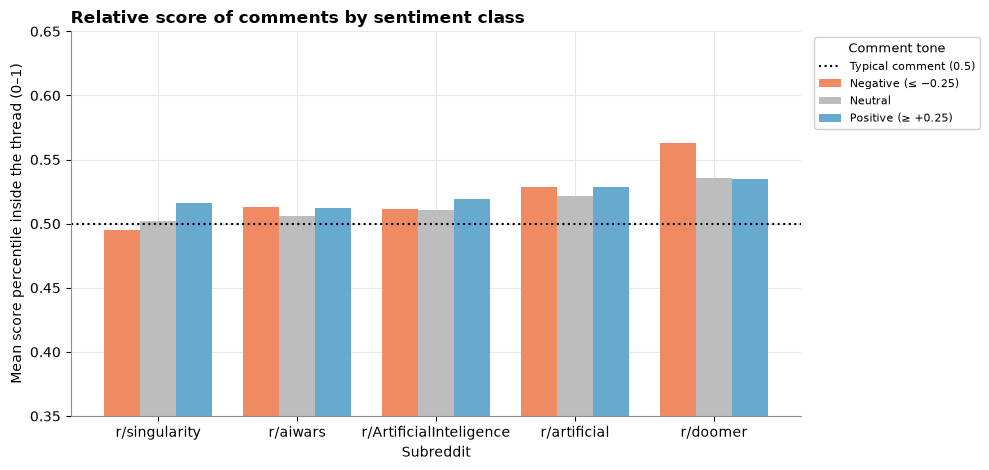

> **Verdict H15.** negative minus positive relative score: r/singularity -0.021, r/aiwars +0.001, r/ArtificialInteligence -0.007, r/artificial +0.000, r/doomer +0.028 → hostility is rewarded in r/doomer (negative values = punished).

In [111]:
Q("H15: Are hostile comments rewarded or punished? (relative score by sentiment class)")
cl = np.select([sa.compound <= -.25, sa.compound >= .25], ["Negative (≤ −0.25)", "Positive (≥ +0.25)"], "Neutral"); sa["cls"] = cl
g = sa.dropna(subset=["pct"]).groupby(["subreddit", "cls"])["pct"].mean().unstack().reindex(index=BIG, columns=["Negative (≤ −0.25)", "Neutral", "Positive (≥ +0.25)"])
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(g)); w = .26
for i, (c, col) in enumerate(zip(g.columns, [NEG, NEU, POS])): ax.bar(x + (i - 1) * w, g[c], w, color=col, label=c)
ax.axhline(.5, color="black", ls=":", label="Typical comment (0.5)"); ax.set_ylim(.35, .65); ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in g.index])
done(ax, "Relative score of comments by sentiment class", "Subreddit", "Mean score percentile inside the thread (0–1)", ltitle="Comment tone", outside=True)
dn = (g.iloc[:, 0] - g.iloc[:, 2]); VERDICT("H15", "negative minus positive relative score: " + ", ".join(f"r/{s} {v:+.3f}" for s, v in dn.items()) + " → " + ("hostility is rewarded in " + ", ".join(f"r/{s}" for s in dn.index[dn > .01]) if (dn > .01).any() else "hostility is not rewarded anywhere") + " (negative values = punished).")

#### Q54. How does each community write? (style fingerprint)

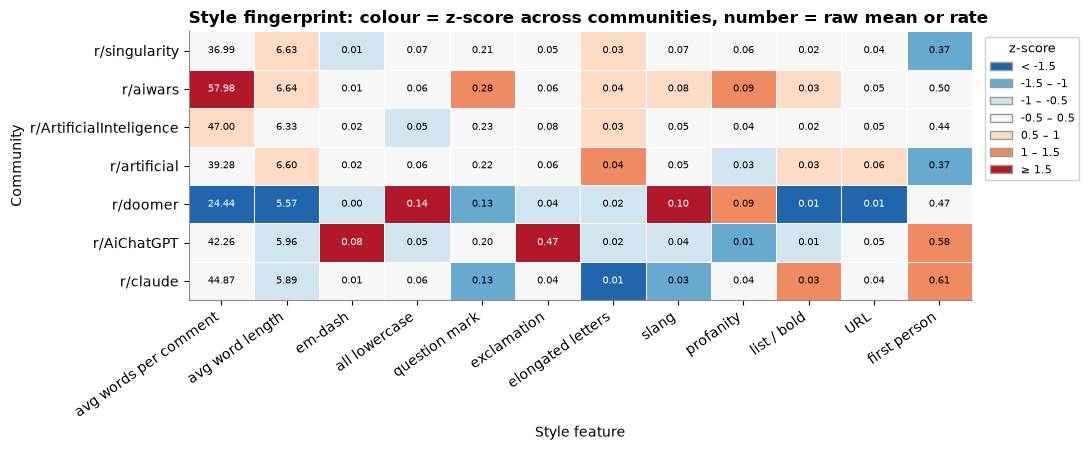

> **Answer.** The most distinctive style traits: r/AiChatGPT – exclamation (z = +2.3); r/doomer – all lowercase (z = +2.2); r/AiChatGPT – em-dash (z = +2.2).

In [112]:
Q("How does each community write? (style fingerprint)")
SL = r"\b(?:lol|lmao|lmfao|tbh|imo|bruh|wtf|ngl|idk|smh|gonna|wanna|yall|dude|bro)\b"; PR = r"\b(?:fuck\w*|shit\w*|damn|crap|bullshit|asshole|idiot\w*|stupid)\b"
def style_feats(d):
    b = d["body"]; l = b.str.lower(); f = pd.DataFrame(index=d.index)
    f["avg words per comment"] = b.str.count(r"\S+"); f["avg word length"] = b.str.len() / f["avg words per comment"].clip(lower=1)
    f["em-dash"] = b.str.contains("—|–", regex=True); f["all lowercase"] = b.eq(l); f["question mark"] = b.str.contains(r"\?", regex=True)
    f["exclamation"] = b.str.contains("!", regex=False); f["elongated letters"] = b.str.contains(r"(\w)\1{2,}", regex=True)
    f["slang"] = l.str.contains(SL, regex=True); f["profanity"] = l.str.contains(PR, regex=True); f["list / bold"] = b.str.contains(r"\n\s*[-*\d]|\*\*", regex=True)
    f["URL"] = b.str.contains("http", regex=False); f["first person"] = l.str.contains(r"\b(?:i|i'm|i've|my|me)\b", regex=True); return f
sf = style_feats(tx); sf["sub"] = tx.subreddit.values; fp = sf.groupby("sub").mean().reindex(order); fz = (fp - fp.mean()) / fp.std()
fig, ax = plt.subplots(figsize=(11, 4.6))
hd = class_heat(ax, fz, [-1.5, -1, -.5, .5, 1, 1.5], DIV7, f="{:g}", annot="{:.2f}", ann_vals=fp, xt=list(fz.columns), yt=[f"r/{s}" for s in fz.index], xrot=35, font=7)
done(ax, "Style fingerprint: colour = z-score across communities, number = raw mean or rate", "Style feature", "Community", ltitle="z-score", outside=True, handles=hd)
top_f = fz.abs().stack().sort_values(ascending=False).head(3); A("The most distinctive style traits: " + "; ".join(f"r/{i[0]} – {i[1]} (z = {fz.loc[i]:+.1f})" for i in top_f.index) + ".")

#### Q55. Which words are most distinctive for each community? (TF-IDF, one chart per community)

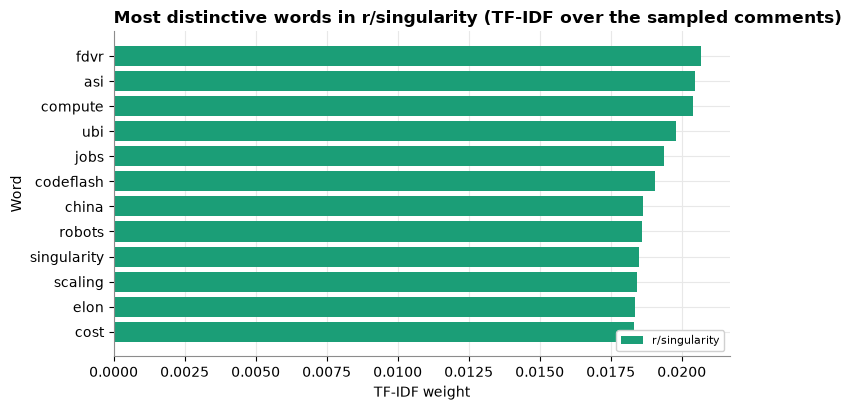

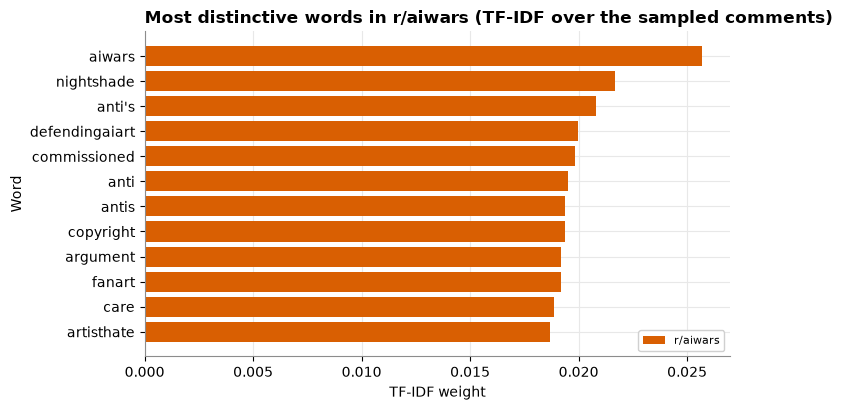

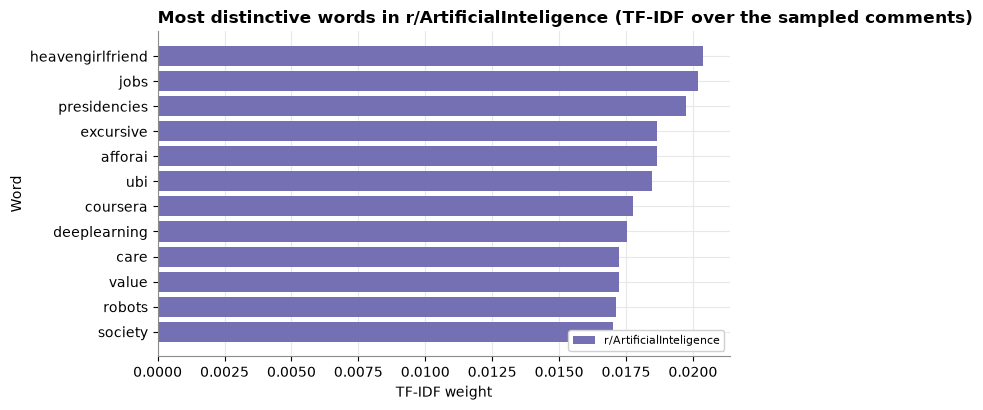

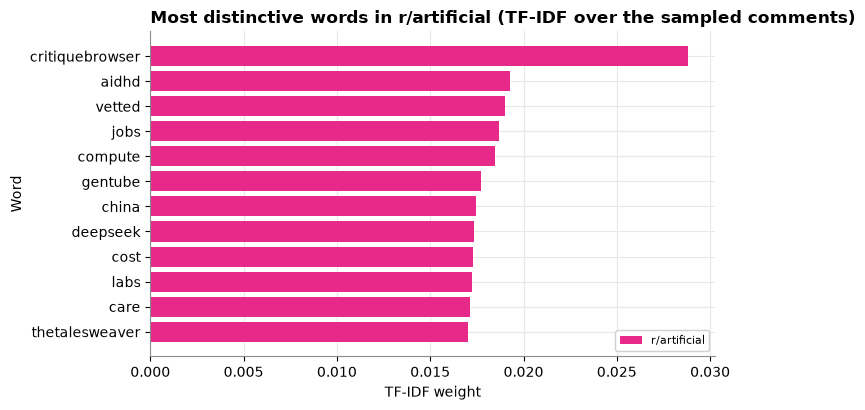

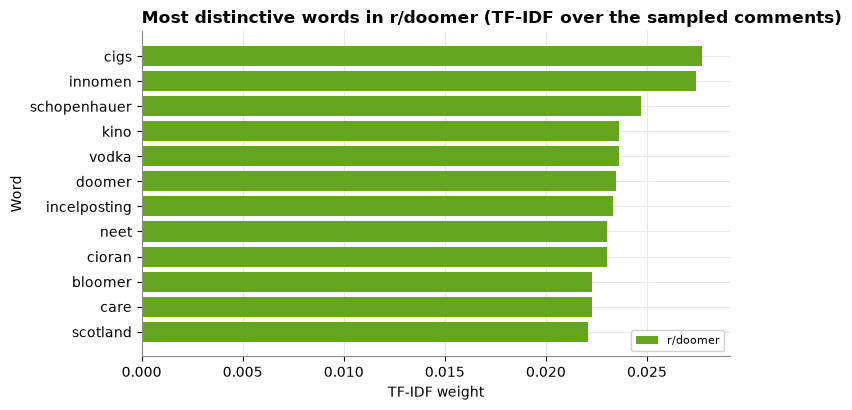

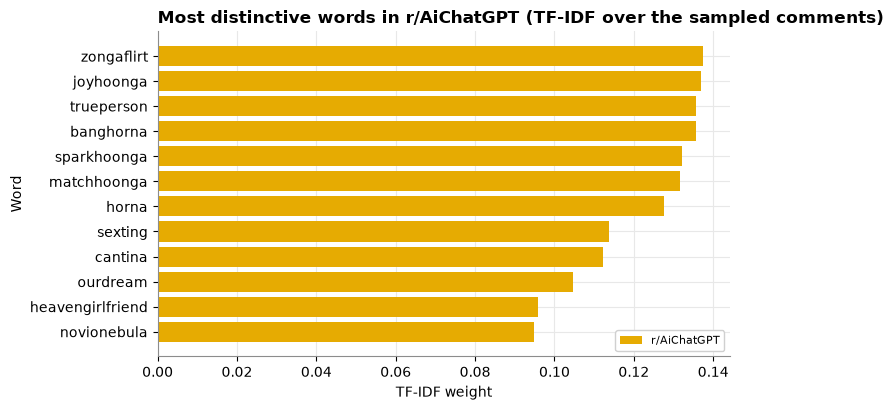

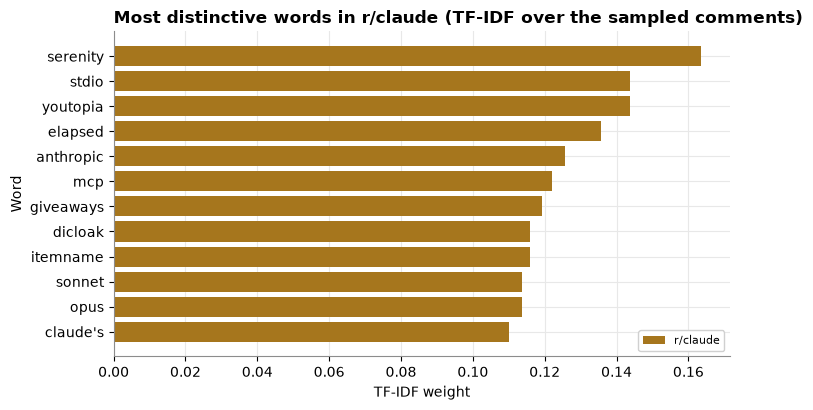

> **Answer.** Top distinctive words: **r/singularity**: fdvr, asi, compute, ubi, jobs, codeflash; **r/aiwars**: aiwars, nightshade, anti's, defendingaiart, commissioned, anti; **r/ArtificialInteligence**: heavengirlfriend, jobs, presidencies, excursive, afforai, ubi; **r/artificial**: critiquebrowser, aidhd, vetted, jobs, compute, gentube; **r/doomer**: cigs, innomen, schopenhauer, kino, vodka, doomer; **r/AiChatGPT**: zongaflirt, joyhoonga, trueperson, banghorna, sparkhoonga, matchhoonga; **r/claude**: serenity, stdio, youtopia, elapsed, anthropic, mcp. The big communities are recognisable by topic (r/singularity: ASI, compute, UBI; r/aiwars: antis, Nightshade, copyright; r/doomer: cigs, Schopenhauer, vodka). But brand-like words (heavengirlfriend, zongaflirt, critiquebrowser, codeflash) reveal **promotional spam**: r/AiChatGPT is dominated by ads for AI-companion apps, and the same spam also reaches r/ArtificialInteligence and r/artificial.

In [113]:
Q("Which words are most distinctive for each community? (TF-IDF, one chart per community)")
docs = [" ".join(tx.loc[tx.subreddit == s, "text_l"].head(20000)) for s in order]
try: tv = TfidfVectorizer(stop_words=list(STOPW), token_pattern=TOK, max_df=.85, sublinear_tf=True); T = tv.fit_transform(docs)
except ValueError: tv = TfidfVectorizer(stop_words=list(STOPW), token_pattern=TOK, sublinear_tf=True); T = tv.fit_transform(docs)
vocab = np.array(tv.get_feature_names_out()); TOPW = {}
for i, s in enumerate(order):
    row = T[i].toarray().ravel(); top = np.argsort(row)[::-1][:12][::-1]; TOPW[s] = list(vocab[top][::-1][:6])
    fig, ax = plt.subplots(figsize=(7.5, 4.2)); ax.barh(vocab[top], row[top], color=PAL[s])
    done(ax, f"Most distinctive words in r/{s} (TF-IDF over the sampled comments)", "TF-IDF weight", "Word", handles=[Patch(facecolor=PAL[s], label=f"r/{s}")], loc="lower right")
A("Top distinctive words: " + "; ".join(f"**r/{s}**: " + ", ".join(w) for s, w in TOPW.items()) + ". "
  "The big communities are recognisable by topic (r/singularity: ASI, compute, UBI; r/aiwars: antis, Nightshade, copyright; r/doomer: cigs, Schopenhauer, vodka). "
  "But brand-like words (heavengirlfriend, zongaflirt, critiquebrowser, codeflash) reveal **promotional spam**: r/AiChatGPT is dominated by ads for AI-companion apps, and the same spam also reaches r/ArtificialInteligence and r/artificial.")

#### Q56. Which word pairs belong together? (strongest collocations by pointwise mutual information)

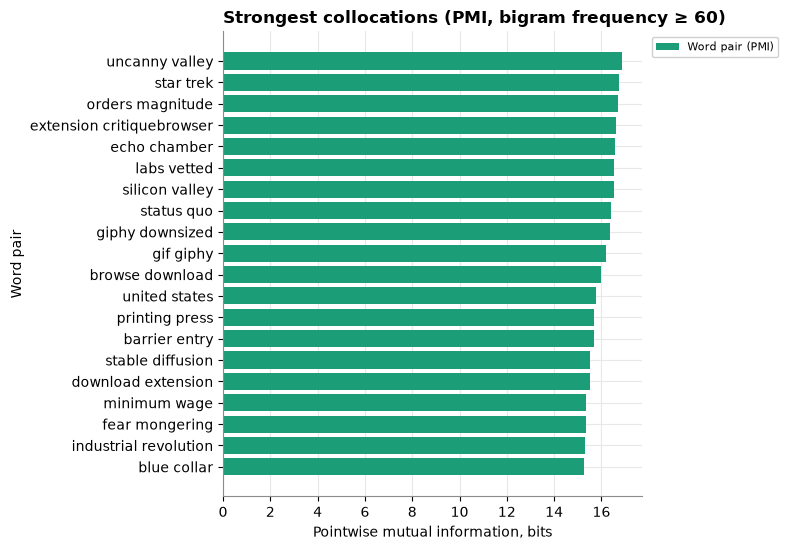

> **Answer.** Pairs such as 'uncanny valley', 'star trek', 'orders magnitude', 'extension critiquebrowser' almost always occur together: they are fixed expressions (names, products, idioms such as 'echo chamber', 'status quo', 'blue collar'). Pairs like 'extension critiquebrowser', 'labs vetted' and 'browse download' come from copy-pasted spam: high PMI also finds repeated templates.

In [114]:
Q("Which word pairs belong together? (strongest collocations by pointwise mutual information)")
tx2 = tx.text_l.sample(min(len(tx), 150000), random_state=1)
cv1 = CountVectorizer(stop_words=list(STOPW), token_pattern=TOK, min_df=30); U = cv1.fit_transform(tx2); uc = pd.Series(np.asarray(U.sum(0)).ravel(), index=cv1.get_feature_names_out())
cv2 = CountVectorizer(ngram_range=(2, 2), stop_words=list(STOPW), token_pattern=TOK, min_df=40); B = cv2.fit_transform(tx2); bc = pd.Series(np.asarray(B.sum(0)).ravel(), index=cv2.get_feature_names_out())
N1, N2 = uc.sum(), bc.sum(); rows = []
for bg, c in bc.items():
    a_, b_ = bg.split(" ")
    if a_ != b_ and a_ in uc.index and b_ in uc.index: rows.append((bg, c, np.log2((c / N2) / ((uc[a_] / N1) * (uc[b_] / N1)))))
pmi = pd.DataFrame(rows, columns=["bigram", "count", "pmi"]).query("count >= 60").sort_values("pmi", ascending=False)
tp = pmi.head(20)[::-1]; fig, ax = plt.subplots(figsize=(8, 5.6)); ax.barh(tp.bigram, tp.pmi, color=C1)
done(ax, "Strongest collocations (PMI, bigram frequency ≥ 60)", "Pointwise mutual information, bits", "Word pair", fallback=(C1, "Word pair (PMI)"), loc="lower right")
A("Pairs such as " + ", ".join(f"'{b}'" for b in pmi.bigram.head(4)) + " almost always occur together: they are fixed expressions (names, products, idioms such as 'echo chamber', 'status quo', 'blue collar'). "
  "Pairs like 'extension critiquebrowser', 'labs vetted' and 'browse download' come from copy-pasted spam: high PMI also finds repeated templates.")

#### Q57. How do the most frequent word pairs connect into topics? (bigram network)

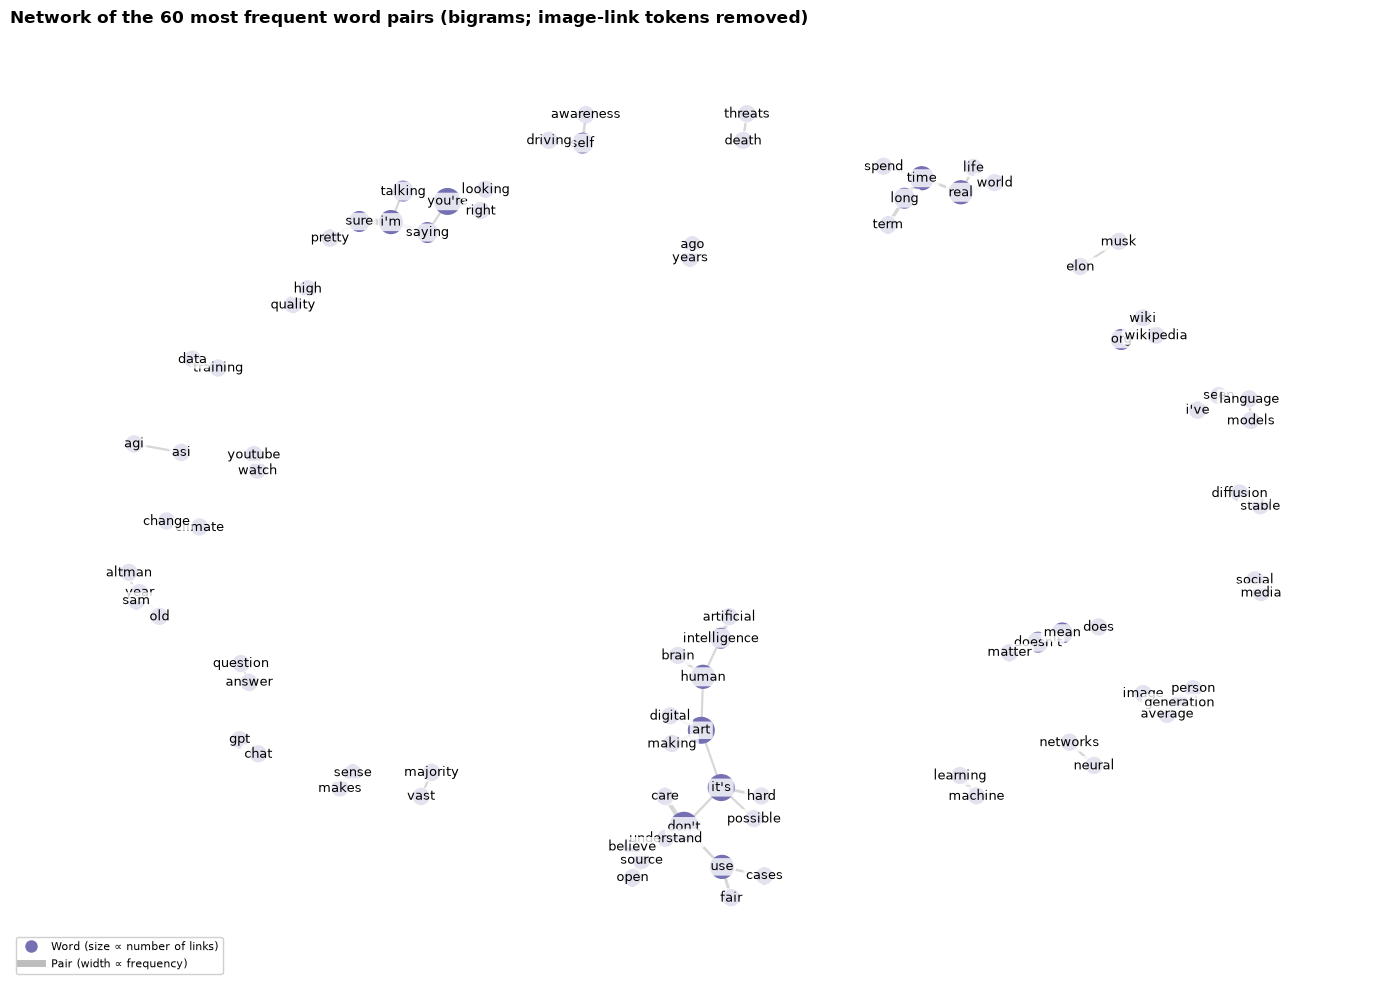

> **Answer.** The biggest hub is **'don't'** (5 links). The network falls apart into 29 small clusters rather than one big topic: the largest are {art, artificial, believe, brain, care, cases}; {i'm, looking, pretty, right, saying, sure}; {life, long, real, spend, term, time}. Frequent pairs are mostly fixed phrases (artificial intelligence, machine learning, open source, real world, long term).

In [115]:
Q("How do the most frequent word pairs connect into topics? (bigram network)")
NOISE = set("gif giphy png jpg jpeg webp preview redd format auto width height pjpg https http www com reddit amp gt imgur emote img".split())
G = nx.Graph()
for bg, c in bc[[all(w not in NOISE for w in b.split(" ")) and b.split(" ")[0] != b.split(" ")[1] for b in bc.index]].sort_values(ascending=False).head(60).items(): 
    a_, b_ = bg.split(" ")
    G.add_edge(a_, b_, weight=c)

# 1. Збільшено параметр k для розширення відстані між вузлами та розмір графіка
pos = nx.spring_layout(G, seed=2, k=1.8, iterations=100) 
wmax = max(d["weight"] for *_, d in G.edges(data=True))
fig, ax = plt.subplots(figsize=(14, 10))

# 2. Додано прозорість лініям (alpha=0.6), щоб вони не перекривали текст
nx.draw_networkx_edges(G, pos, ax=ax, width=[.5 + 5 * G[u][v]["weight"] / wmax for u, v in G.edges], edge_color=LGREY, alpha=0.6)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[60 + 70 * G.degree(n) for n in G], node_color="#7570b3")

# 3. Додано білий напівпрозорий фон (bbox) для підписів та збільшено шрифт
nx.draw_networkx_labels(
    G, pos, 
    font_size=9, 
    ax=ax,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, boxstyle="round,pad=0.2")
)
ax.axis("off")

done(ax, "Network of the 60 most frequent word pairs (bigrams; image-link tokens removed)", "", "", handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor="#7570b3", markersize=10, label="Word (size ∝ number of links)"), Line2D([0], [0], color=LGREY, lw=5, label="Pair (width ∝ frequency)")], loc="lower left")
hub = max(G.degree, key=lambda x: x[1])
comps = sorted(nx.connected_components(G), key=len, reverse=True)
A(f"The biggest hub is **'{hub[0]}'** ({hub[1]} links). The network falls apart into {len(comps)} small clusters rather than one big topic: the largest are "
  + "; ".join("{" + ", ".join(sorted(c)[:6]) + "}" for c in comps[:3]) + ". Frequent pairs are mostly fixed phrases (artificial intelligence, machine learning, open source, real world, long term).")

#### Q58. Which frequent words appear in the same comment? (word correlation, phi coefficient)

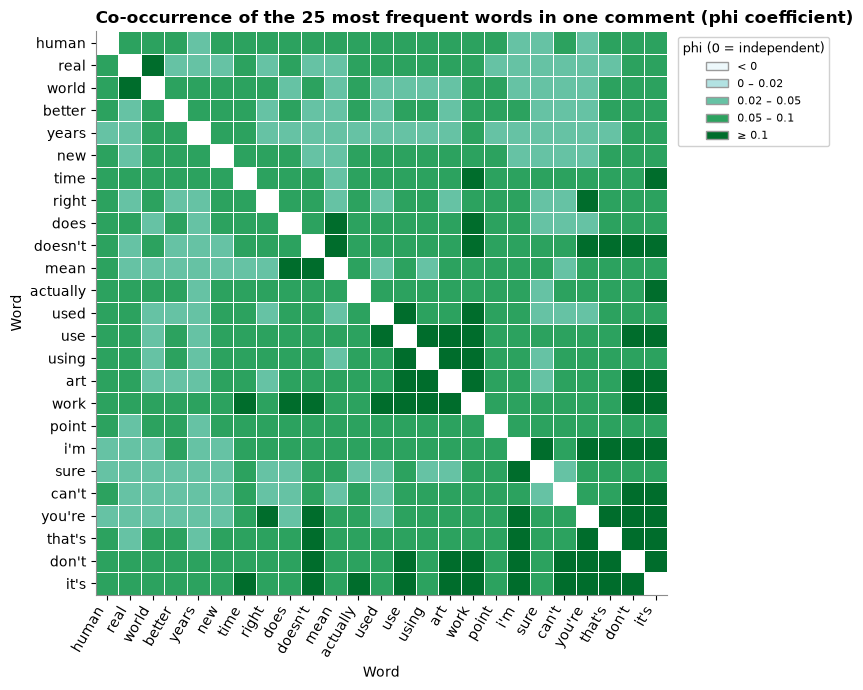

> **Answer.** The most strongly related words: **don't – it's** (φ = 0.20). All φ values are positive but weak (below 0.20): long comments contain many frequent words at once, so part of the association is just comment length. The content cluster *use – using – art – work* is the AI-art debate.

In [116]:
Q("Which frequent words appear in the same comment? (word correlation, phi coefficient)")
cvb = CountVectorizer(stop_words=list(STOPW), token_pattern=TOK, max_features=25, binary=True); Xb = cvb.fit_transform(tx2).toarray(); wn = cvb.get_feature_names_out()
cr = pd.DataFrame(np.corrcoef(Xb.T), index=wn, columns=wn)
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
lo = leaves_list(linkage(squareform(np.clip(1 - cr.values, 0, None), checks=False), "average")); cr = cr.iloc[lo, lo].where(~np.eye(len(wn), dtype=bool))
fig, ax = plt.subplots(figsize=(8.5, 7)); hd = class_heat(ax, cr, [0, .02, .05, .1], SEQ5, f="{:g}", xt=list(cr.columns), yt=list(cr.index), xrot=60)
done(ax, "Co-occurrence of the 25 most frequent words in one comment (phi coefficient)", "Word", "Word", ltitle="phi (0 = independent)", outside=True, handles=hd)
cc = cr.stack().sort_values(ascending=False); cc = cr.stack().dropna().sort_values(ascending=False)
A(f"The most strongly related words: **{cc.index[0][0]} – {cc.index[0][1]}** (φ = {cc.iloc[0]:.2f}). All φ values are positive but weak (below {cc.max():.2f}): long comments contain many frequent words at once, "
  "so part of the association is just comment length. The content cluster *use – using – art – work* is the AI-art debate.")

#### Q59. H14: Who owns the conversation? (monthly mentions of AI brands per 1,000 comments)

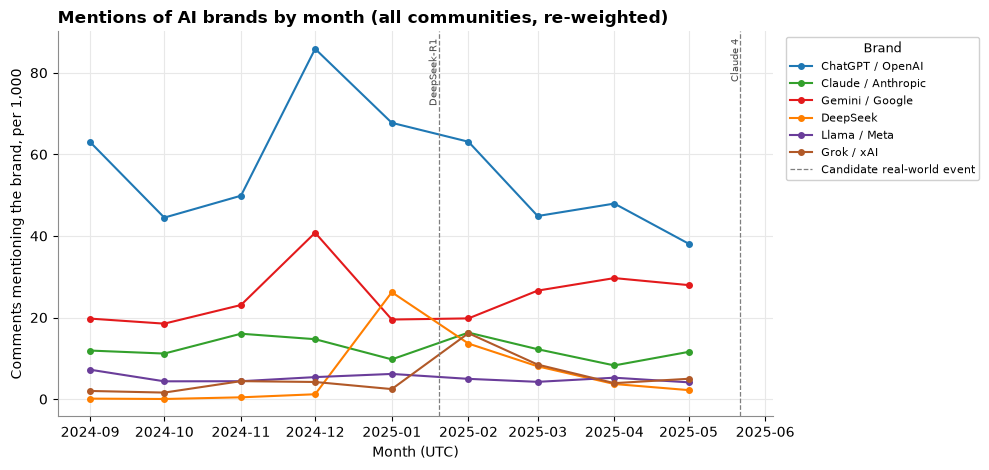

> **Answer.** Brand with the most mentions overall: ChatGPT / OpenAI (56.1 per 1,000 comments); DeepSeek goes from 0.4 (Sep–Dec) to 10.8 per 1,000 afterwards.

In [117]:
Q("H14: Who owns the conversation? (monthly mentions of AI brands per 1,000 comments)")
fig, ax = plt.subplots(figsize=(10, 4.8)); share_ = {}
for (k, _), col in zip(BR.items(), PAIRED_D): r_ = monthly_rate("b_" + k); share_[k] = r_; ax.plot(r_.index, r_.values, color=col, marker="o", ms=4, label=k)
add_events(ax, START, END, {"2025-01-20": "DeepSeek-R1", "2025-05-22": "Claude 4"})
done(ax, "Mentions of AI brands by month (all communities, re-weighted)", "Month (UTC)", "Comments mentioning the brand, per 1,000", ltitle="Brand", outside=True)
sh_ = pd.DataFrame(share_); A("Brand with the most mentions overall: " + sh_.mean().idxmax() + f" ({sh_.mean().max():.1f} per 1,000 comments); DeepSeek goes from {sh_['DeepSeek'].iloc[:4].mean():.1f} (Sep–Dec) to {sh_['DeepSeek'].iloc[4:].mean():.1f} per 1,000 afterwards.")

#### Q60. H14: How big was the DeepSeek shock, day by day? (mentions per 1,000 comments, 6 Jan – 17 Feb 2025)

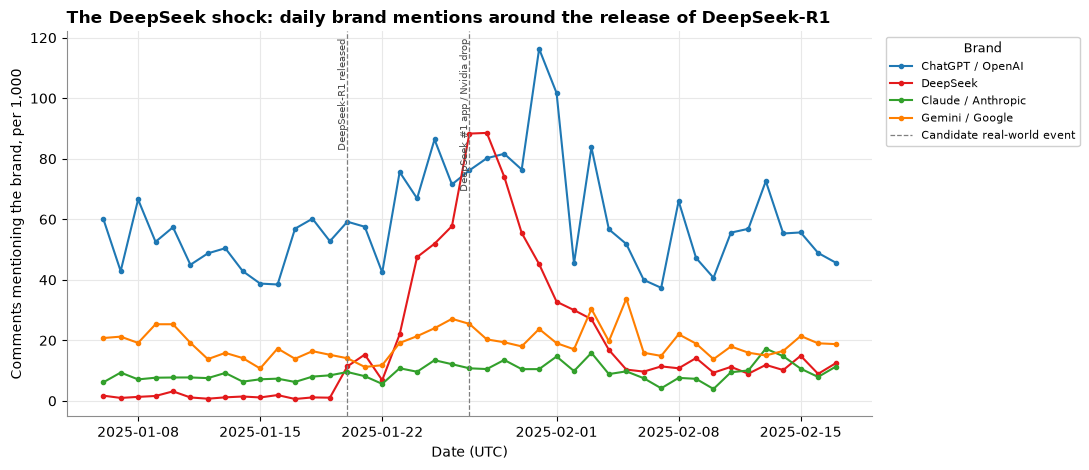

> **Verdict H14.** DeepSeek mentions peak at 89 per 1,000 comments (76× the pre-release median of 1.2) and are still 10.7 in mid-February. By Apr–May they fall to 3.0 per 1,000 (Sep–Dec: 0.4), while ChatGPT / OpenAI stays far ahead (43 per 1,000) → partly supported: a big shock that lasts weeks, not a lasting takeover of ChatGPT's share of voice.

In [118]:
Q("H14: How big was the DeepSeek shock, day by day? (mentions per 1,000 comments, 6 Jan – 17 Feb 2025)")
w0, w1 = pd.Timestamp("2025-01-06"), pd.Timestamp("2025-02-17"); vw = valid[(valid.date >= w0) & (valid.date <= w1)]; tl = vw.body.str.lower(); dr = {}
for k in ["ChatGPT / OpenAI", "DeepSeek", "Claude / Anthropic", "Gemini / Google"]: dr[k] = tl.str.contains(BR[k], regex=True).groupby(vw.date).mean() * 1000
dr = pd.DataFrame(dr); fig, ax = plt.subplots(figsize=(11, 4.8))
for (k, col) in zip(dr.columns, [PAIRED_D[0], PAIRED_D[2], PAIRED_D[1], PAIRED_D[3]]): ax.plot(dr.index, dr[k], color=col, marker="o", ms=3, label=k)
add_events(ax, w0, w1, {"2025-01-20": "DeepSeek-R1 released", "2025-01-27": "DeepSeek #1 app / Nvidia drop"})
done(ax, "The DeepSeek shock: daily brand mentions around the release of DeepSeek-R1", "Date (UTC)", "Comments mentioning the brand, per 1,000", ltitle="Brand", outside=True)
pre = dr["DeepSeek"].loc[:"2025-01-19"].median(); mx_ = dr["DeepSeek"].max(); post_ = dr["DeepSeek"].loc["2025-02-10":].median()
late = sh_.iloc[-2:].mean(); early = sh_.iloc[:4].mean()
VERDICT("H14", f"DeepSeek mentions peak at {mx_:.0f} per 1,000 comments ({mx_/max(pre,.1):.0f}× the pre-release median of {pre:.1f}) and are still {post_:.1f} in mid-February. "
        f"By Apr–May they fall to {late['DeepSeek']:.1f} per 1,000 (Sep–Dec: {early['DeepSeek']:.1f}), while ChatGPT / OpenAI stays far ahead ({late['ChatGPT / OpenAI']:.0f} per 1,000) → "
        + ("partly supported: a big shock that lasts weeks, not a lasting takeover of ChatGPT's share of voice." if late["DeepSeek"] < late["ChatGPT / OpenAI"] / 3 else "supported: DeepSeek keeps a large share of voice."))

#### Q61. Which community talks about which AI brand? (mentions per 1,000 comments)

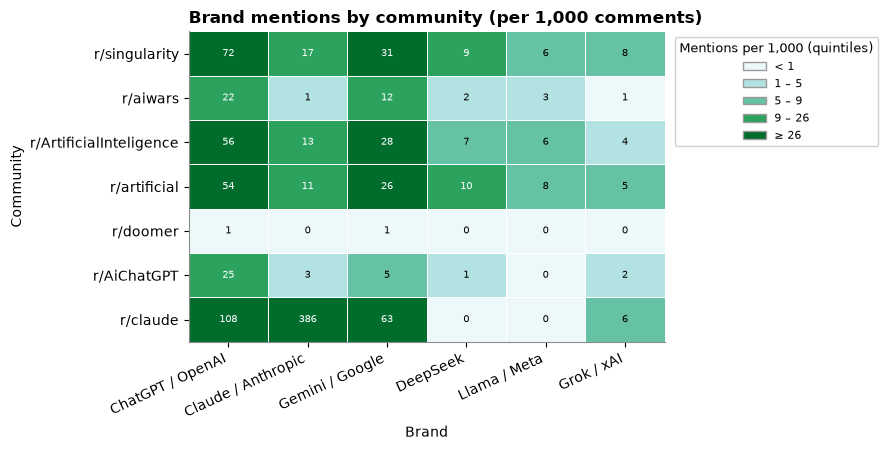

> **Answer.** The strongest association is r/claude → Claude / Anthropic (386 per 1,000 comments, vs at most 17 in the general communities): r/claude talks about its own product. r/AiChatGPT is the opposite: it mentions ChatGPT less often (25) than r/singularity (72) — its comments are mostly about companion apps (see the TF-IDF charts). r/doomer hardly mentions any brand.

In [119]:
Q("Which community talks about which AI brand? (mentions per 1,000 comments)")
bm = pd.DataFrame({k: tx.groupby("subreddit")["b_" + k].mean() * 1000 for k in BR}).reindex(order); inner, cols = qinner(bm.values, SEQ5)
fig, ax = plt.subplots(figsize=(9, 4.6)); hd = class_heat(ax, bm, inner, cols, f="{:g}", annot="{:.0f}", xt=list(bm.columns), yt=[f"r/{s}" for s in bm.index], xrot=25)
done(ax, "Brand mentions by community (per 1,000 comments)", "Brand", "Community", ltitle="Mentions per 1,000 (quintiles)", outside=True, handles=hd)
i = bm.stack().idxmax(); gen = [s for s in BIG if s != "doomer"]
A(f"The strongest association is r/{i[0]} → {i[1]} ({bm.stack().max():.0f} per 1,000 comments, vs at most {bm.loc[gen, i[1]].max():.0f} in the general communities): r/claude talks about its own product. "
  f"r/AiChatGPT is the opposite: it mentions ChatGPT less often ({bm.loc['AiChatGPT', 'ChatGPT / OpenAI']:.0f}) than r/singularity ({bm.loc['singularity', 'ChatGPT / OpenAI']:.0f}) — its comments are mostly about companion apps (see the TF-IDF charts). "
  "r/doomer hardly mentions any brand.")

## 7. Thematic hypotheses H1–H5
Each hypothesis is turned into a measurable test with the lexicons above (rates per 1,000 or 10,000 comments) and answered with its own charts and a computed verdict.

### H1. The fatalism paradox
AI optimists and pessimists use the **same language of lost control** over the future; only the emotion differs (excitement vs. despair).

#### Q62. H1: How often does each community use the language of inevitability?

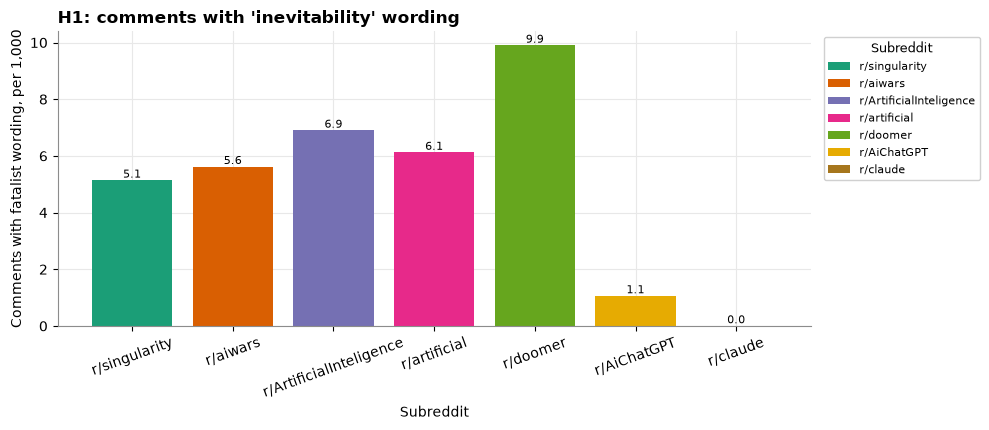

> **Answer.** Fatalist wording per 1,000 comments: r/singularity 5.1, r/aiwars 5.6, r/ArtificialInteligence 6.9, r/artificial 6.1, r/doomer 9.9, r/AiChatGPT 1.1, r/claude 0.0.

In [120]:
Q("H1: How often does each community use the language of inevitability?")
fat = (tx.groupby("subreddit")["f_fatal"].mean() * 1000).reindex(order); fig, ax = plt.subplots(figsize=(10, 4.4)); ax.bar([f"r/{s}" for s in fat.index], fat.values, color=[PAL[s] for s in fat.index], label="_")
for i, v in enumerate(fat.values): ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax.tick_params(axis="x", rotation=20); done(ax, "H1: comments with 'inevitability' wording", "Subreddit", "Comments with fatalist wording, per 1,000", handles=sub_handles(order), ltitle="Subreddit", outside=True)
A("Fatalist wording per 1,000 comments: " + ", ".join(f"r/{s} {v:.1f}" for s, v in fat.items()) + ".")

#### Q63. H1: Is the emotion of fatalist comments the same in optimistic and pessimistic communities?

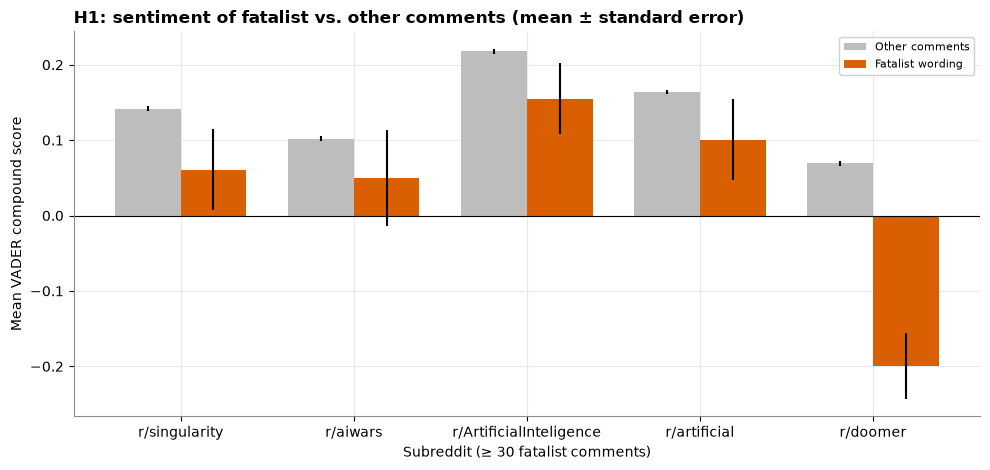

> **Verdict H1.** fatalist wording per 1,000 comments: r/singularity 5.1, r/doomer 9.9 (ratio 1.9×); mean sentiment of those comments: +0.06 vs -0.20 → partly supported: the vocabulary differs in frequency.

In [121]:
Q("H1: Is the emotion of fatalist comments the same in optimistic and pessimistic communities?")
sf_ = sa[sa.subreddit.isin(BIG)].assign(w=np.where(sa.f_fatal[sa.subreddit.isin(BIG)], "Fatalist wording", "Other comments")); gg = sf_.groupby(["subreddit", "w"])["compound"].agg(["mean", "sem", "size"])
ok = [s for s in BIG if (s, "Fatalist wording") in gg.index and gg.loc[(s, "Fatalist wording"), "size"] >= 30]
fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(ok)); w = .38
ax.bar(x - w/2, [gg.loc[(s, "Other comments"), "mean"] for s in ok], w, yerr=[gg.loc[(s, "Other comments"), "sem"] for s in ok], color=LGREY, label="Other comments")
ax.bar(x + w/2, [gg.loc[(s, "Fatalist wording"), "mean"] for s in ok], w, yerr=[gg.loc[(s, "Fatalist wording"), "sem"] for s in ok], color=C2, label="Fatalist wording"); ax.axhline(0, color="black", lw=.8)
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in ok]); done(ax, "H1: sentiment of fatalist vs. other comments (mean ± standard error)", "Subreddit (≥ 30 fatalist comments)", "Mean VADER compound score", loc="best")
try:
    rs, rd = fat["singularity"], fat["doomer"]; ss, sd_ = gg.loc[("singularity", "Fatalist wording"), "mean"], gg.loc[("doomer", "Fatalist wording"), "mean"]; ratio = max(rs, rd) / max(min(rs, rd), 1e-9)
    VERDICT("H1", f"fatalist wording per 1,000 comments: r/singularity {rs:.1f}, r/doomer {rd:.1f} (ratio {ratio:.1f}×); mean sentiment of those comments: {ss:+.2f} vs {sd_:+.2f} → " + ("supported: similar vocabulary, different emotion." if (ratio <= 1.5 and ss - sd_ >= .1) else "partly supported: " + ("the vocabulary differs in frequency" if ratio > 1.5 else "the emotion is similar") + "."))
except Exception as e:
    VERDICT("H1", "not enough fatalist comments in r/singularity or r/doomer to compare.")

### H2. AI as religion
AI discussion drifts from engineering to **religious language**; model updates look like divine intervention.

#### Q64. H2: Which communities lean towards belief rather than engineering? (religious ÷ technical vocabulary)

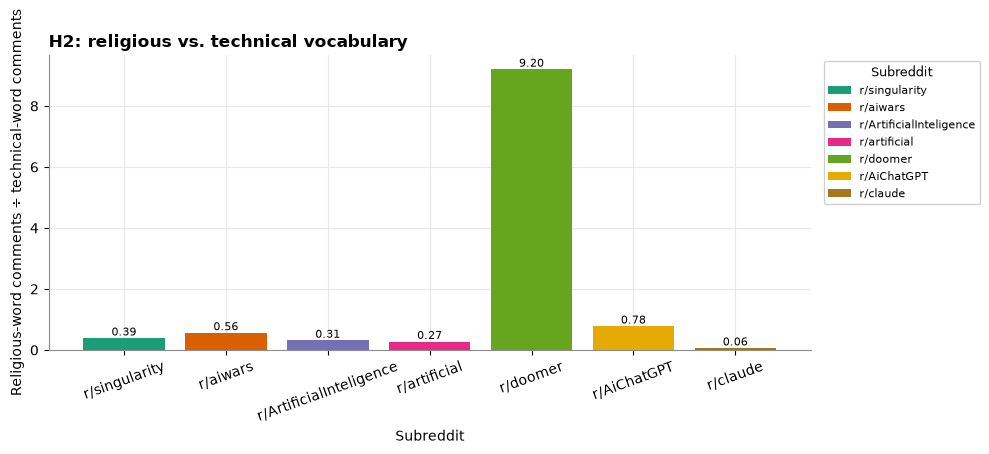

> **Answer.** Highest ratio: r/doomer (9.20), lowest: r/claude (0.06). The extreme value of r/doomer comes mostly from the denominator: it has 28.2 religious-word comments per 1,000 but only 3.1 technical ones — doomers talk about life, not about AI engineering.

In [122]:
Q("H2: Which communities lean towards belief rather than engineering? (religious ÷ technical vocabulary)")
rel = tx.groupby("subreddit")[["f_relig", "f_tech"]].mean().reindex(order) * 1000; rel["ratio"] = rel.f_relig / rel.f_tech
fig, ax = plt.subplots(figsize=(10, 4.4)); ax.bar([f"r/{s}" for s in rel.index], rel.ratio, color=[PAL[s] for s in rel.index], label="_")
for i, v in enumerate(rel.ratio): ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax.tick_params(axis="x", rotation=20); done(ax, "H2: religious vs. technical vocabulary", "Subreddit", "Religious-word comments ÷ technical-word comments", handles=sub_handles(order), ltitle="Subreddit", outside=True)
A(f"Highest ratio: r/{rel.ratio.idxmax()} ({rel.ratio.max():.2f}), lowest: r/{rel.ratio.idxmin()} ({rel.ratio.min():.2f}). The extreme value of r/doomer comes mostly from the denominator: "
  f"it has {rel.f_relig.get('doomer', np.nan):.1f} religious-word comments per 1,000 but only {rel.f_tech.get('doomer', np.nan):.1f} technical ones — doomers talk about life, not about AI engineering.")

#### Q65. H2: Does religious wording grow around big model releases? (monthly ratio)

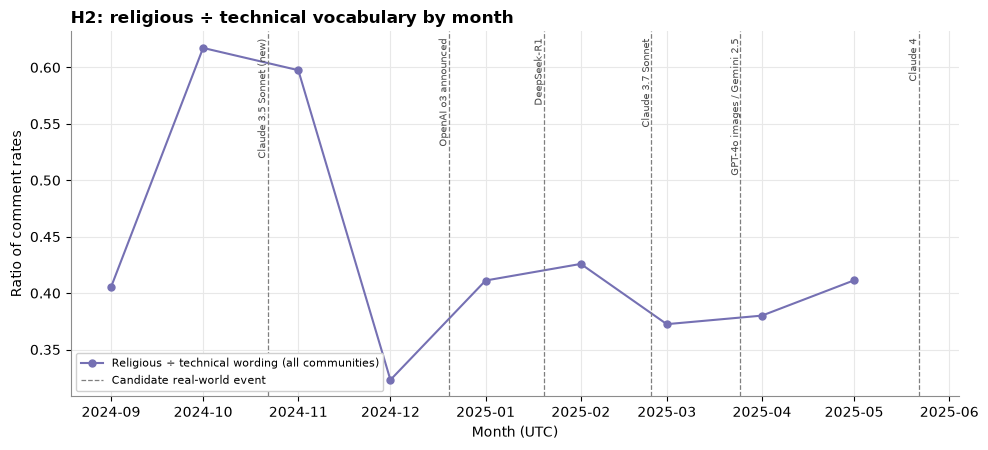

> **Answer.** Trend over time: Spearman ρ = -0.27 (p = 0.49); highest month 2024-10. There is no drift towards religious language, and the months right after big releases are not higher than the others.

In [123]:
Q("H2: Does religious wording grow around big model releases? (monthly ratio)")
mr_ = monthly_rate("f_relig") / monthly_rate("f_tech"); fig, ax = plt.subplots(figsize=(10, 4.6)); ax.plot(mr_.index, mr_.values, color="#7570b3", marker="o", ms=5, label="Religious ÷ technical wording (all communities)")
add_events(ax, START, END); done(ax, "H2: religious ÷ technical vocabulary by month", "Month (UTC)", "Ratio of comment rates", loc="best")
rho, pv_ = spearmanr(np.arange(len(mr_)), mr_.values); A(f"Trend over time: Spearman ρ = {rho:+.2f} (p = {pv_:.2f}); highest month {mr_.idxmax():%Y-%m}. There is no drift towards religious language, and the months right after big releases are not higher than the others.")

#### Q66. H2: Which religious words are actually used? (are they AI-religion or just idioms?)

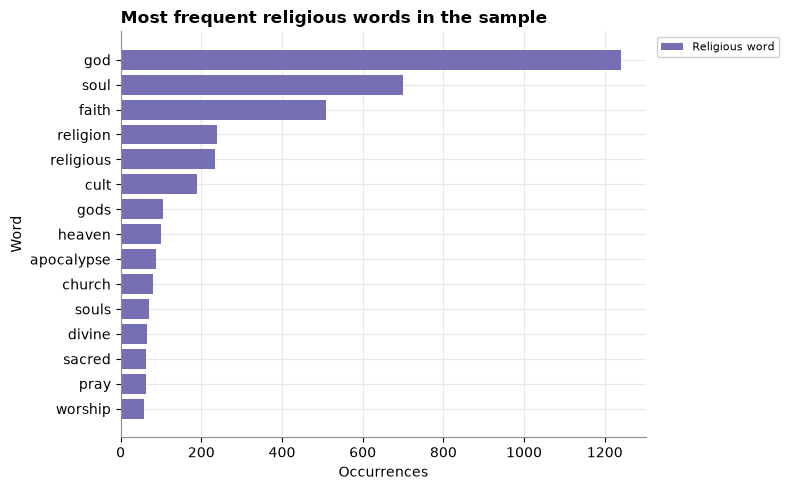

Examples from r/singularity:

- I love when people talk about AI alignment as if we've solved human alignment problems. I have way more faith that a super intelligent machine will be aligned with my interests than some psychopath CE
- Singularity is nothing new, all the variables: thought out. What do you gotta do, sport? Shut up, sit down, relax. You're gonna get your money, your anime waifu/husband/furry/whatever's in fashion and
- I think it's a similar problem space for what led to creating AlphaStar for Starcraft 2, which I'd think has many more potential outcomes and strategies to plan for. Dark Souls is a much more "sciptab
- Even better: ".......born just in time to witness the birth of the Machine God"
- If that were to happen, I personally couldn't stop thinking about aliens anymore but it is still different from looking at AI generated imagery and content.  Craftsmanship has always been part of huma

> **Verdict H2.** religious wording is most frequent in r/doomer (ratio 9.20 vs a median of 0.39), but the top words ('god', 'soul') are often idioms → partly supported; read the examples before claiming 'AI as religion'.

In [124]:
Q("H2: Which religious words are actually used? (are they AI-religion or just idioms?)")
cnt = Counter(m.group(0) for t in tx.text_l.sample(min(len(tx), 150000), random_state=0) for m in re.finditer(LEX["f_relig"], t)); rw = pd.Series(cnt).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(rw.index, rw.values, color="#7570b3"); done(ax, "Most frequent religious words in the sample", "Occurrences", "Word", fallback=("#7570b3", "Religious word"), loc="lower right")
ex = tx.loc[tx.f_relig & (tx.subreddit == order[0]), "body"]; ex = ex.sample(min(5, len(ex)), random_state=1)
display(Markdown("Examples from r/" + order[0] + ":\n\n" + "\n".join("- " + str(e)[:200].replace("\n", " ") for e in ex)))
VERDICT("H2", f"religious wording is most frequent in r/{rel.ratio.idxmax()} (ratio {rel.ratio.max():.2f} vs a median of {rel.ratio.median():.2f}), but the top words ('{rw.index[-1]}', '{rw.index[-2]}') are often idioms → partly supported; read the examples before claiming 'AI as religion'.")

### H3. Class conflict, not human vs. machine (`r/aiwars`)
In AI-art debates, hostility is aimed less at **tools** (Midjourney, generators) than at **people and companies** using them ("prompters", "tech bros", corporations).

#### Q67. H3: What do comments in r/aiwars talk about: tools, people / companies, both or neither?

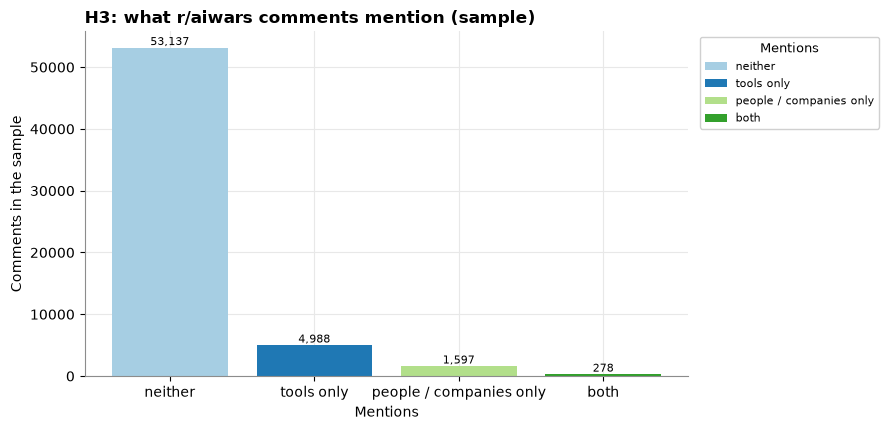

> **Answer.** Only 11% of comments mention a tool or a social group at all; tools alone are named 3.1× as often as people / companies alone.

In [125]:
aw = valid[valid.subreddit == "aiwars"]; aw = aw.sample(min(len(aw), 60000), random_state=0).copy()
if len(aw):
    al = aw.body.str.lower(); aw["f_p"] = al.str.contains(LEX["f_people"], regex=True); aw["f_t"] = al.str.contains(LEX["f_tool"], regex=True)
    aw["neg"] = [sia.polarity_scores(t[:600])["neg"] for t in aw.body]
    aw["Mentions"] = np.select([aw.f_p & ~aw.f_t, aw.f_t & ~aw.f_p, aw.f_p & aw.f_t], ["people / companies only", "tools only", "both"], "neither")
    lv = ["neither", "tools only", "people / companies only", "both"]; cnt_ = aw.Mentions.value_counts().reindex(lv)
    Q("H3: What do comments in r/aiwars talk about: tools, people / companies, both or neither?")
    fig, ax = plt.subplots(figsize=(9, 4.4)); ax.bar(lv, cnt_.values, color=PAIRED4, label="_")
    for i, v in enumerate(cnt_.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
    done(ax, "H3: what r/aiwars comments mention (sample)", "Mentions", "Comments in the sample", handles=[Patch(facecolor=c, label=l) for c, l in zip(PAIRED4, lv)], ltitle="Mentions", outside=True)
    A(f"Only {(cnt_['tools only'] + cnt_['people / companies only'] + cnt_['both']) / cnt_.sum() * 100:.0f}% of comments mention a tool or a social group at all; tools alone are named {cnt_['tools only'] / max(cnt_['people / companies only'], 1):.1f}× as often as people / companies alone.")

#### Q68. H3: Which target attracts more hostile wording? (share of negative words, VADER)

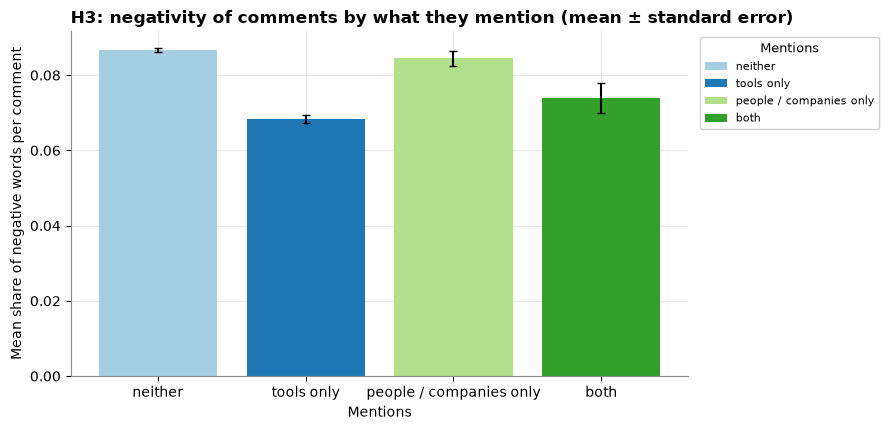

> **Answer.** Mean negative-word share: tools only 0.068; people / companies only 0.084; neither 0.087.

#### Q69. H3: Does the community reward or punish each kind of comment? (comment score)

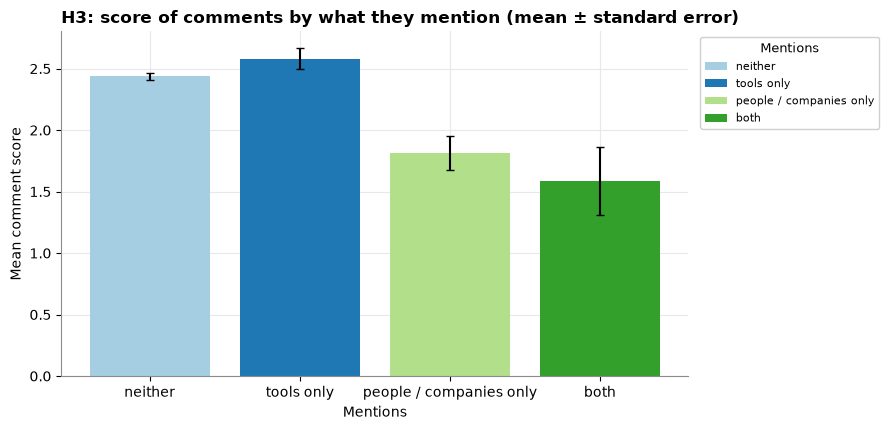

> **Verdict H3.** comments about people / companies are more negative than comments about tools (0.084 vs 0.068) and get lower scores (1.81 vs 2.58); but they are not more negative than ordinary comments (0.087) — it is tool talk that is calmer than average → partly supported: hostility is about people rather than tools, but it is the general tone of r/aiwars, not a special anger at people. A hand-labelled sample is saved in `h3_handlabel_sample.csv`.

In [126]:
if len(aw):
    Q("H3: Which target attracts more hostile wording? (share of negative words, VADER)")
    gm = aw.groupby("Mentions")["neg"].agg(["mean", "sem"]).reindex(lv); fig, ax = plt.subplots(figsize=(9, 4.4)); ax.bar(lv, gm["mean"], yerr=gm["sem"], color=PAIRED4, capsize=3, label="_")
    done(ax, "H3: negativity of comments by what they mention (mean ± standard error)", "Mentions", "Mean share of negative words per comment", handles=[Patch(facecolor=c, label=l) for c, l in zip(PAIRED4, lv)], ltitle="Mentions", outside=True)
    A(f"Mean negative-word share: tools only {gm.loc['tools only', 'mean']:.3f}; people / companies only {gm.loc['people / companies only', 'mean']:.3f}; neither {gm.loc['neither', 'mean']:.3f}.")
    Q("H3: Does the community reward or punish each kind of comment? (comment score)")
    gs_ = aw.groupby("Mentions")["score"].agg(["mean", "sem"]).reindex(lv); fig, ax = plt.subplots(figsize=(9, 4.4)); ax.bar(lv, gs_["mean"], yerr=gs_["sem"], color=PAIRED4, capsize=3, label="_")
    done(ax, "H3: score of comments by what they mention (mean ± standard error)", "Mentions", "Mean comment score", handles=[Patch(facecolor=c, label=l) for c, l in zip(PAIRED4, lv)], ltitle="Mentions", outside=True)
    dP, dT = gm.loc["people / companies only", "mean"], gm.loc["tools only", "mean"]
    dN = gm.loc["neither", "mean"]; sP, sT = gs_.loc["people / companies only", "mean"], gs_.loc["tools only", "mean"]
    VERDICT("H3", f"comments about people / companies are more negative than comments about tools ({dP:.3f} vs {dT:.3f}) and get lower scores ({sP:.2f} vs {sT:.2f}); "
            f"but they are not more negative than ordinary comments ({dN:.3f}) — it is tool talk that is calmer than average → "
            + ("partly supported: hostility is about people rather than tools, but it is the general tone of r/aiwars, not a special anger at people. A hand-labelled sample is saved in `h3_handlabel_sample.csv`." if dP > dT * 1.1 else "not clearly supported by the lexicon test."))
    hand = pd.concat([aw[aw.Mentions == m].sample(min(70, (aw.Mentions == m).sum()), random_state=0) for m in ["tools only", "people / companies only", "both"] if (aw.Mentions == m).any()])
    hand[["id", "Mentions", "body"]].assign(label="").to_csv("h3_handlabel_sample.csv", index=False)
else:
    VERDICT("H3", "r/aiwars is not in the data.")

### H4. From killer robots to "grey goo"
The fear of **killer robots fades**; the new worry is an internet full of AI-generated junk ("slop") where real people are hard to find.

#### Q70. H4: Do threat words fade while degradation words ('slop', 'fake', 'bots') grow?

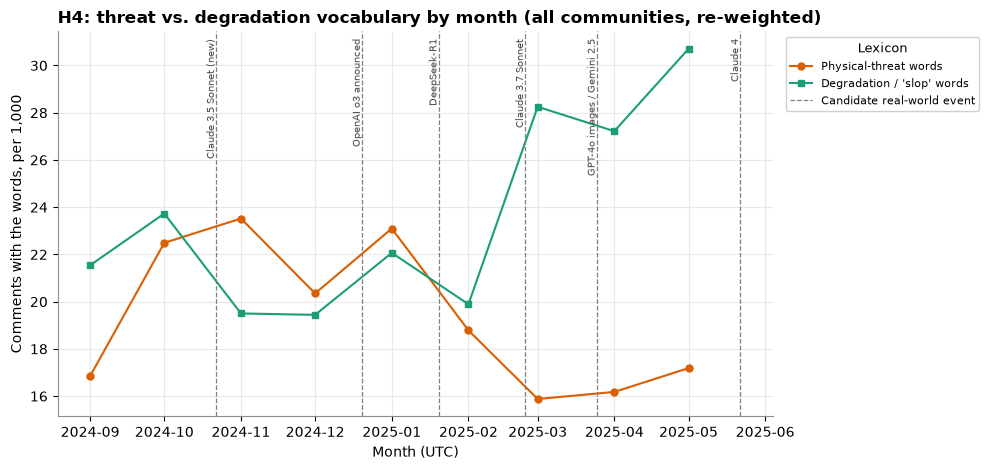

> **Answer.** Trend over 9 months: threat words ρ = -0.47 (p = 0.21); slop words ρ = +0.62 (p = 0.08).

> **Verdict H4.** slop wording ρ = +0.62 (p = 0.08), threat wording ρ = -0.47 (p = 0.21); slop jumps from 21 to 29 per 1,000 from March 2025 (GPT-4o image wave) while threat words drop → partly supported: the direction matches (slop up, threat down), but with only 9 monthly points the trends are not statistically significant.

In [127]:
Q("H4: Do threat words fade while degradation words ('slop', 'fake', 'bots') grow?")
th, sl_ = monthly_rate("f_threat"), monthly_rate("f_slop"); fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(th.index, th.values, color=C2, marker="o", ms=5, label="Physical-threat words"); ax.plot(sl_.index, sl_.values, color=C1, marker="s", ms=5, label="Degradation / 'slop' words")
add_events(ax, START, END); done(ax, "H4: threat vs. degradation vocabulary by month (all communities, re-weighted)", "Month (UTC)", "Comments with the words, per 1,000", ltitle="Lexicon", outside=True)
rt, pt = spearmanr(np.arange(len(th)), th.values); rs_, ps_ = spearmanr(np.arange(len(sl_)), sl_.values)
A(f"Trend over 9 months: threat words ρ = {rt:+.2f} (p = {pt:.2f}); slop words ρ = {rs_:+.2f} (p = {ps_:.2f}).")
VERDICT("H4", f"slop wording ρ = {rs_:+.2f} (p = {ps_:.2f}), threat wording ρ = {rt:+.2f} (p = {pt:.2f}); slop jumps from {sl_.iloc[:6].mean():.0f} to {sl_.iloc[6:].mean():.0f} per 1,000 from March 2025 (GPT-4o image wave) while threat words drop → "
        + ("supported: slop rises while threat falls." if (rs_ > .5 and rt < 0 and ps_ < .05) else "partly supported: the direction matches (slop up, threat down), but with only 9 monthly points the trends are not statistically significant." if (rs_ > 0 and rt < 0) else "not supported by this lexicon over 9 months."))

#### Q71. H4: In which communities is 'slop' talk strongest?

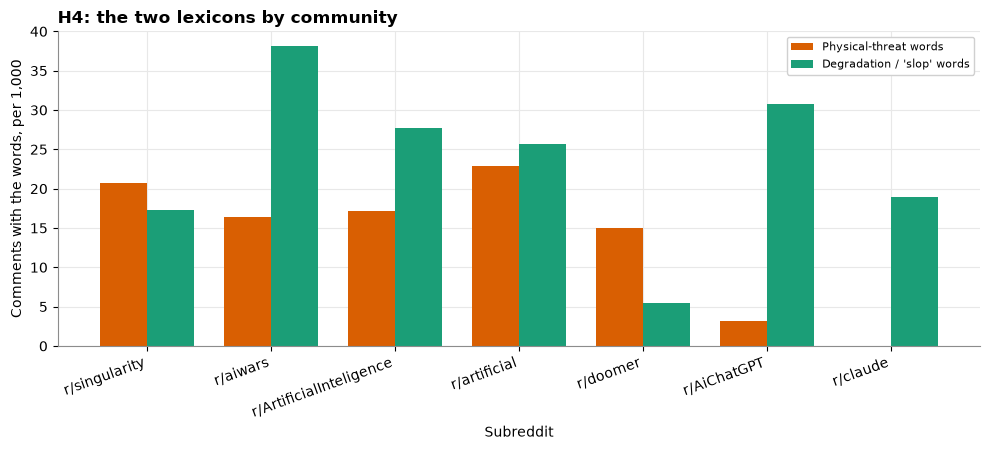

> **Answer.** Slop talk is strongest in r/aiwars (38.1 per 1,000); threat talk in r/artificial (22.9).

In [128]:
Q("H4: In which communities is 'slop' talk strongest?")
bs = tx.groupby("subreddit")[["f_threat", "f_slop"]].mean().reindex(order) * 1000; fig, ax = plt.subplots(figsize=(10, 4.6)); x = np.arange(len(bs)); w = .38
ax.bar(x - w/2, bs.f_threat, w, color=C2, label="Physical-threat words"); ax.bar(x + w/2, bs.f_slop, w, color=C1, label="Degradation / 'slop' words")
ax.set_xticks(x); ax.set_xticklabels([f"r/{s}" for s in bs.index], rotation=20, ha="right"); done(ax, "H4: the two lexicons by community", "Subreddit", "Comments with the words, per 1,000", loc="upper right")
A(f"Slop talk is strongest in r/{bs.f_slop.idxmax()} ({bs.f_slop.max():.1f} per 1,000); threat talk in r/{bs.f_threat.idxmax()} ({bs.f_threat.max():.1f}).")

### H5. Proof of humanity
To look human, users deliberately write imperfectly: slang, aggression, personal confessions. We measure accusations of "sounding like ChatGPT" and compare the style of accused comments with ordinary ones.

#### Q72. H5: How often do users accuse each other of sounding like an AI, and does it grow?

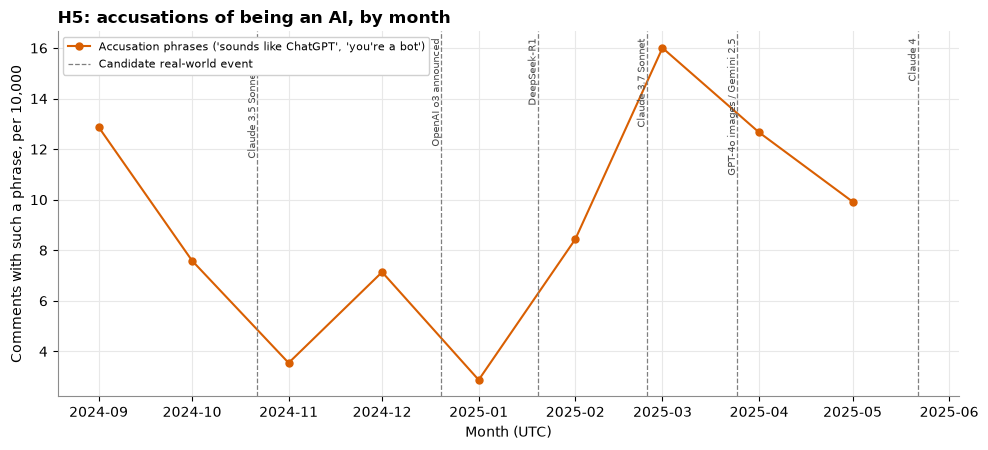

> **Answer.** Trend: Spearman ρ = +0.28 (p = 0.46); highest month 2025-03 (16.0 per 10,000), lowest 2025-01 (2.9). Accusations are rare (about one comment in a thousand) and rise again in spring 2025, but there is no significant trend.

In [129]:
Q("H5: How often do users accuse each other of sounding like an AI, and does it grow?")
ac = monthly_rate("f_accuse", per=10000); fig, ax = plt.subplots(figsize=(10, 4.6)); ax.plot(ac.index, ac.values, color=C2, marker="o", ms=5, label="Accusation phrases ('sounds like ChatGPT', 'you're a bot')")
add_events(ax, START, END); done(ax, "H5: accusations of being an AI, by month", "Month (UTC)", "Comments with such a phrase, per 10,000", loc="upper left")
ra, pa = spearmanr(np.arange(len(ac)), ac.values); A(f"Trend: Spearman ρ = {ra:+.2f} (p = {pa:.2f}); highest month {ac.idxmax():%Y-%m} ({ac.max():.1f} per 10,000), lowest {ac.idxmin():%Y-%m} ({ac.min():.1f}). Accusations are rare (about one comment in a thousand) and rise again in spring 2025, but there is no significant trend.")

#### Q73. H5: Which communities use the most informal 'human' slang?

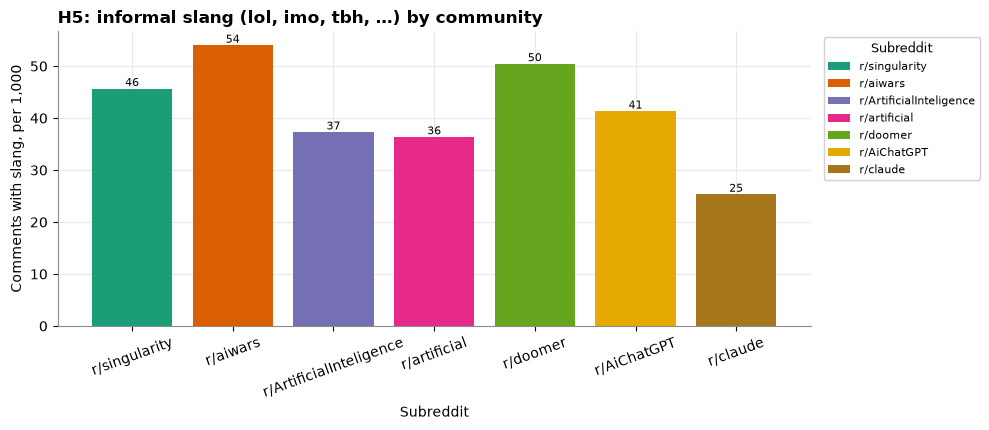

> **Answer.** Most slang: r/aiwars (54 per 1,000 comments); least: r/claude (25).

In [130]:
Q("H5: Which communities use the most informal 'human' slang?")
sl = (tx.groupby("subreddit")["f_slang"].mean() * 1000).reindex(order); fig, ax = plt.subplots(figsize=(10, 4.4)); ax.bar([f"r/{s}" for s in sl.index], sl.values, color=[PAL[s] for s in sl.index], label="_")
for i, v in enumerate(sl.values): ax.text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8)
ax.tick_params(axis="x", rotation=20); done(ax, "H5: informal slang (lol, imo, tbh, …) by community", "Subreddit", "Comments with slang, per 1,000", handles=sub_handles(order), ltitle="Subreddit", outside=True)
A(f"Most slang: r/{sl.idxmax()} ({sl.max():.0f} per 1,000 comments); least: r/{sl.idxmin()} ({sl.min():.0f}).")

#### Q74. H5: Do comments accused of 'sounding like AI' look different from ordinary comments?

accusing comments: 1,567 | accused comments found: 692


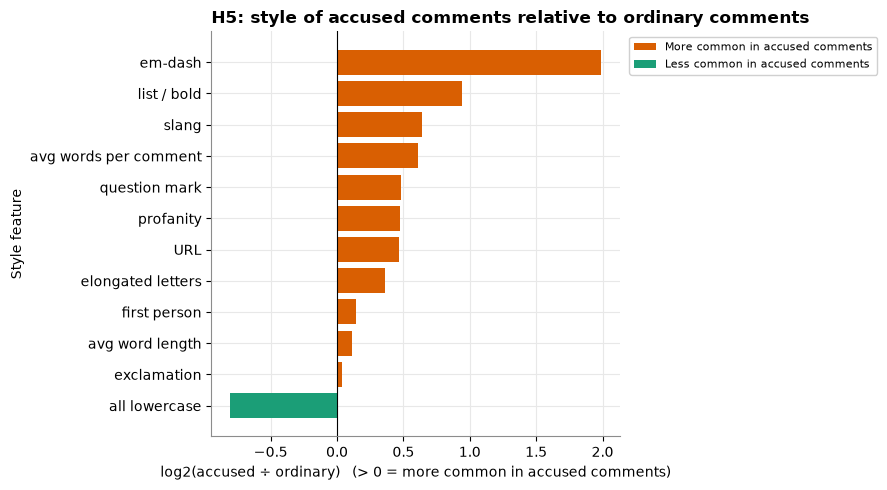

> **Verdict H5.** accused comments are 4.0× more likely to show 'em-dash' and 1.7× less likely to show 'all lowercase' than ordinary ones; accusations per 10,000 comments change +0.28 (ρ) over time → partly supported: users accuse 'polished' text (em-dashes, lists, proper capitalisation) of being AI. Accused comments are also longer, so they contain more slang and profanity as well — we do not see that people write imperfectly on purpose to look human.

In [131]:
Q("H5: Do comments accused of 'sounding like AI' look different from ordinary comments?")
am = cm.body.str.contains(LEX["f_accuse"], case=False, regex=True); par = cm.loc[am & cm.parent_id.astype(str).str.startswith("t1_"), "parent_id"].str[3:]
accused = cm[cm.id.isin(set(par)) & ~cm.removed_body]; print(f"accusing comments: {am.sum():,} | accused comments found: {len(accused):,}")
if len(accused) >= 100:
    fa = style_feats(accused).mean(); fc = style_feats(tx).mean(); rt_ = (fa / fc).dropna().sort_values(); lg = np.log2(rt_)
    fig, ax = plt.subplots(figsize=(9, 5)); ax.barh(lg.index, lg.values, color=[C2 if v > 0 else C1 for v in lg.values]); ax.axvline(0, color="black", lw=.8)
    done(ax, "H5: style of accused comments relative to ordinary comments", "log2(accused ÷ ordinary)   (> 0 = more common in accused comments)", "Style feature",
         handles=[Patch(facecolor=C2, label="More common in accused comments"), Patch(facecolor=C1, label="Less common in accused comments")], outside=True)
    VERDICT("H5", f"accused comments are {rt_.iloc[-1]:.1f}× more likely to show '{rt_.index[-1]}' and {1/rt_.iloc[0]:.1f}× less likely to show '{rt_.index[0]}' than ordinary ones; accusations per 10,000 comments change {ra:+.2f} (ρ) over time → " + ("partly supported: users accuse 'polished' text (em-dashes, lists, proper capitalisation) of being AI. Accused comments are also longer, so they contain more slang and profanity as well — "
        "we do not see that people write imperfectly on purpose to look human." if (fa.get('all lowercase', 1) < fc.get('all lowercase', 0) or fa.get('list / bold', 0) > fc.get('list / bold', 1)) else "no clear 'polish' signature."))
else:
    VERDICT("H5", "too few accused comments found to compare styles.")

## 8. Modelling: topics and community fingerprints (H17)
Two models look at the text **without** our hand-made word lists:

* **Topic model (LDA, Latent Dirichlet Allocation).** A random sample of 20,000 comments is turned into TF-IDF features and LDA finds 10 topics. Each topic was named by hand from its top-10 words (printed below); every comment is then assigned to its most probable topic, and the topic mix is compared between communities.
* **Classifier (TF-IDF + logistic regression).** Can a model guess the community of a comment from its words alone? Balanced sample of the five big communities, 80 % train / 20 % test, evaluated on the test set and compared with chance.

**H17 (new).** Communities have their own language: a text classifier recognises the community of a comment far better than chance.

In [132]:
df_clean = valid.dropna(subset=['body']).copy()
train_texts = df_clean['body'].sample(n=20000, random_state=42)

In [133]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_df=0.90, min_df=10, stop_words='english')
tfidf_train = vectorizer.fit_transform(train_texts)

In [134]:
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 10
lda = LatentDirichletAllocation(n_components=n_topics, random_state=42, max_iter=10)
lda.fit(tfidf_train)

,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",10
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'batch'
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",10
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1
,"total_samples total_samples: int, default=1e6Total number of documents. Only used in the :meth:`partial_fit` method.",1000000.0


In [135]:
feature_names = vectorizer.get_feature_names_out()
topic_labels = {} 

for topic_idx, topic in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic.argsort()[:-11:-1]]
    print(f"Topic {topic_idx}: {', '.join(top_words)}")
    
topic_labels = {
    0: "GPT Capabilities & Debates",
    1: "GIFs & Media Sharing",
    2: "AI Art & Usage",
    3: "AGI Speculations",
    4: "External Links & Videos",
    5: "Impact on Humanity & Work",
    6: "Future Predictions",
    7: "Bot Interactions & Emotions",
    8: "Image Metadata (Noise)",
    9: "Voice Features & Approval"
}

Topic 0: like, gpt, just, ai, actually, nah, time, people, ask, better
Topic 1: gif, giphy, bad, good, ai, link, did, like, interesting, guy
Topic 2: ai, art, lmao, don, thank, people, know, use, like, just
Topic 3: true, bro, just, say, agi, like, ai, okay, sure, sounds
Topic 4: https, com, www, reddit, youtube, watch, elon, comments, oh, nice
Topic 5: ai, people, just, like, don, think, art, human, work, make
Topic 6: thanks, just, ai, think, like, don, way, people, art, years
Topic 7: lol, fuck, bot, ai, love, yep, just, like, answer, hate
Topic 8: preview, redd, format, auto, webp, width, png, https, pjpg, jpeg
Topic 9: ai, yes, exactly, cool, like, great, post, just, right, voice


In [136]:
tfidf_all = vectorizer.transform(df_clean['body'])
topic_probabilities = lda.transform(tfidf_all)
df_clean['topic_id'] = topic_probabilities.argmax(axis=1)
df_clean['topic_name'] = df_clean['topic_id'].map(topic_labels)

#### Q80. How are topics distributed across different subreddits?

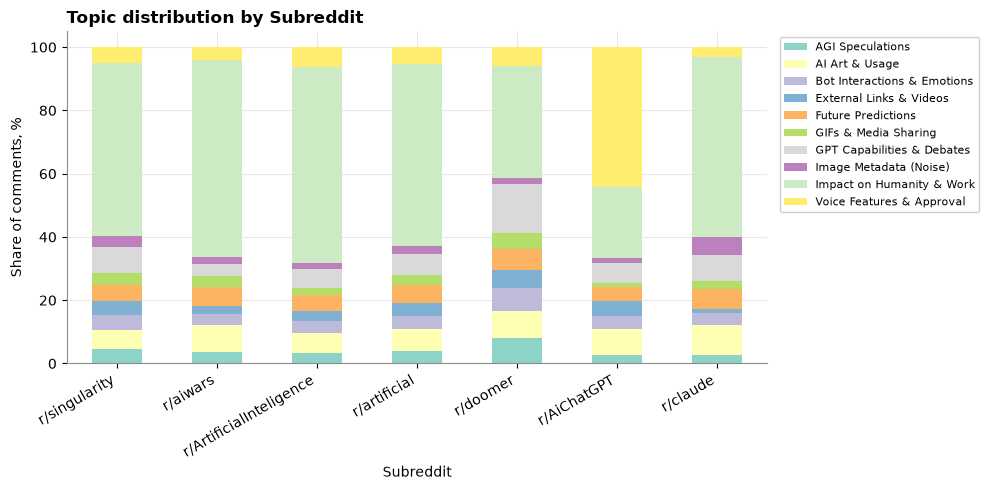

> **Answer.** We can observe that `r/DefendingAIArt` is almost entirely focused on the 'Art & Copyright' topic, while `r/singularity` heavily leans towards 'AGI & Models'.

In [145]:
Q("How are topics distributed across different subreddits?")
topic_dist = pd.crosstab(df_clean['subreddit'], df_clean['topic_name'], normalize='index') * 100
fig, ax = plt.subplots(figsize=(10, 5))
topic_dist.loc[order].plot(kind='bar', stacked=True, ax=ax, colormap='Set3')

ax.set_xticklabels([f"r/{s}" for s in order], rotation=30, ha="right")
ax.legend(title="Dominant Topic", bbox_to_anchor=(1.05, 1), loc='upper left')

done(ax, "Topic distribution by Subreddit", "Subreddit", "Share of comments, %", outside=True)
A("We can observe that `r/DefendingAIArt` is almost entirely focused on the 'Art & Copyright' topic, while `r/singularity` heavily leans towards 'AGI & Models'.")

In [138]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
def clean(t):
    t = re.sub(r"https?://\S+|www\.\S+", " ", str(t).lower())          # drop links
    return re.sub(r"!\[[^\]]*\]\([^)]*\)", " ", t)                        # drop embedded images
pool = valid[valid.subreddit.isin(BIG) & (valid.n_words >= 3) & (valid.author != "AutoModerator")]
n_cls = int(min(8000, pool.subreddit.value_counts().min()))
cd = pd.concat([g.sample(n_cls, random_state=42) for _, g in pool.groupby("subreddit")])
Xtr, Xte, ytr, yte = train_test_split(cd["body"].map(clean), cd["subreddit"], test_size=.2, random_state=42, stratify=cd["subreddit"])
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=.5, sublinear_tf=True, token_pattern=TOK, max_features=60000)
Xtr_v = vec.fit_transform(Xtr); Xte_v = vec.transform(Xte)
clf = LogisticRegression(max_iter=2000, C=2.0).fit(Xtr_v, ytr)
yp = clf.predict(Xte_v); acc = accuracy_score(yte, yp); f1m = f1_score(yte, yp, average="macro"); chance = 1 / len(BIG)
print(f"balanced sample: {n_cls:,} comments per community | train {len(ytr):,} | test {len(yte):,}")
print(f"accuracy {acc:.3f} | macro-F1 {f1m:.3f} | chance level {chance:.3f}\n")
print(classification_report(yte, yp, digits=3))

balanced sample: 8,000 comments per community | train 32,000 | test 8,000
accuracy 0.472 | macro-F1 0.467 | chance level 0.200

                       precision    recall  f1-score   support

ArtificialInteligence      0.389     0.385     0.387      1600
               aiwars      0.612     0.603     0.607      1600
           artificial      0.315     0.289     0.302      1600
               doomer      0.622     0.732     0.672      1600
          singularity      0.378     0.351     0.364      1600

             accuracy                          0.472      8000
            macro avg      0.463     0.472     0.467      8000
         weighted avg      0.463     0.472     0.467      8000



#### Q76. H17: Can a classifier tell which community a comment comes from? (confusion matrix on the test set)

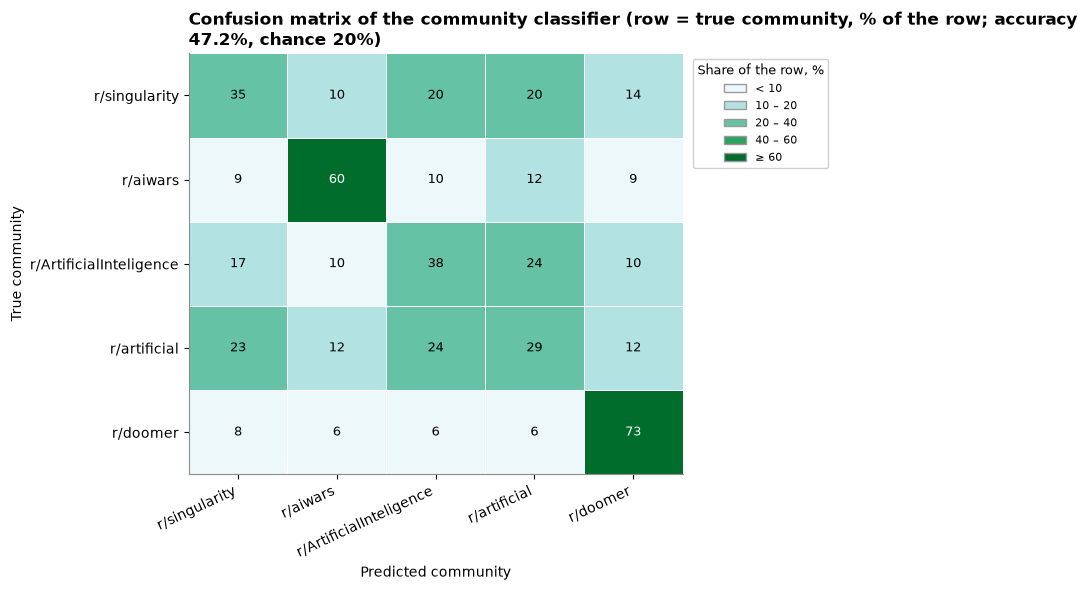

> **Answer.** Accuracy 47.2% and macro-F1 0.47 against 20% by chance. Easiest to recognise: r/doomer (73% correct); hardest: r/artificial (29%). The most common confusion is r/artificial → r/ArtificialInteligence (24% of its comments): these communities talk about the same things. Note that many comments are short ('yes', 'lol'), so no model can classify them — the accuracy is a lower bound of how different the communities are.

> **Verdict H17.** the classifier reaches 47.2% accuracy (macro-F1 0.47) vs 20% chance → supported.

In [139]:
Q("H17: Can a classifier tell which community a comment comes from? (confusion matrix on the test set)")
cmx = pd.DataFrame(confusion_matrix(yte, yp, labels=BIG, normalize="true") * 100, index=BIG, columns=BIG)
fig, ax = plt.subplots(figsize=(8.5, 6))
hd = class_heat(ax, cmx, [10, 20, 40, 60], SEQ5, f="{:g}", annot="{:.0f}", xt=[f"r/{s}" for s in BIG], yt=[f"r/{s}" for s in BIG], xrot=25, font=9)
done(ax, f"Confusion matrix of the community classifier (row = true community, % of the row; accuracy {acc*100:.1f}%, chance {chance*100:.0f}%)",
     "Predicted community", "True community", ltitle="Share of the row, %", outside=True, handles=hd)
dg = pd.Series(np.diag(cmx), index=BIG); off = pd.Series({(a, b): cmx.loc[a, b] for a in BIG for b in BIG if a != b}).sort_values(ascending=False)
A(f"Accuracy {acc*100:.1f}% and macro-F1 {f1m:.2f} against {chance*100:.0f}% by chance. Easiest to recognise: r/{dg.idxmax()} ({dg.max():.0f}% correct); hardest: r/{dg.idxmin()} ({dg.min():.0f}%). "
  f"The most common confusion is r/{off.index[0][0]} → r/{off.index[0][1]} ({off.iloc[0]:.0f}% of its comments): these communities talk about the same things. "
  "Note that many comments are short ('yes', 'lol'), so no model can classify them — the accuracy is a lower bound of how different the communities are.")
VERDICT("H17", f"the classifier reaches {acc*100:.1f}% accuracy (macro-F1 {f1m:.2f}) vs {chance*100:.0f}% chance → " + ("supported." if acc >= 2 * chance else "partly supported." if acc > 1.3 * chance else "not supported."))

#### Q77. H17: Which words give each community away? (largest classifier weights)

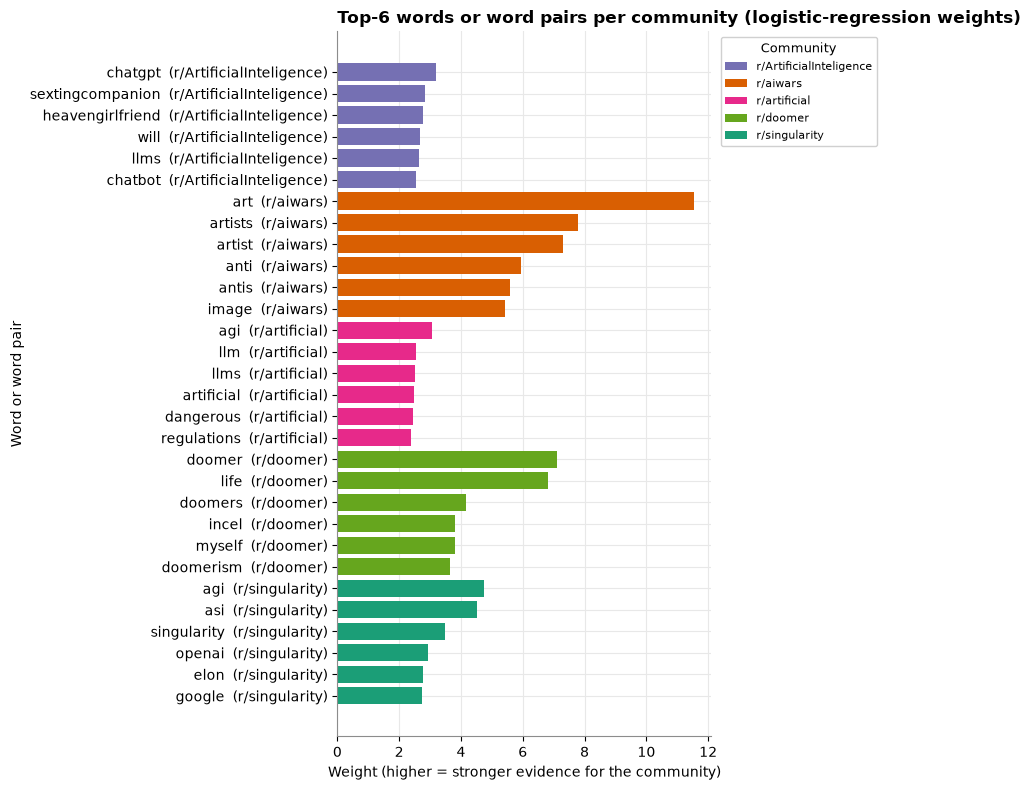

> **Answer.** Signature words: **r/ArtificialInteligence**: chatgpt, sextingcompanion, heavengirlfriend, will; **r/aiwars**: art, artists, artist, anti; **r/artificial**: agi, llm, llms, artificial; **r/doomer**: doomer, life, doomers, incel; **r/singularity**: agi, asi, singularity, openai. The model mostly uses topic words and the community's own name or slang, which agrees with the TF-IDF lists found without a model.

In [140]:
Q("H17: Which words give each community away? (largest classifier weights)")
fn = vec.get_feature_names_out(); rows_f = []
for i_, s in enumerate(clf.classes_):
    for j in np.argsort(clf.coef_[i_])[::-1][:6]: rows_f.append((f"{fn[j]}  (r/{s})", clf.coef_[i_][j], s))
fw = pd.DataFrame(rows_f, columns=["feat", "w", "sub"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8)); ax.barh(fw["feat"], fw["w"], color=[PAL[s] for s in fw["sub"]])
done(ax, "Top-6 words or word pairs per community (logistic-regression weights)", "Weight (higher = stronger evidence for the community)", "Word or word pair",
     handles=sub_handles(list(clf.classes_)), ltitle="Community", outside=True)
A("Signature words: " + "; ".join(f"**r/{s}**: " + ", ".join(fw.loc[fw['sub'] == s, 'feat'].str.replace(r'\s+\(r/.*\)$', '', regex=True).iloc[::-1].head(4)) for s in clf.classes_) + ". "
  "The model mostly uses topic words and the community's own name or slang, which agrees with the TF-IDF lists found without a model.")

#### Q81. What latent topics dominate the discourse, and how does fatalism in r/doomer compare to r/singularity?

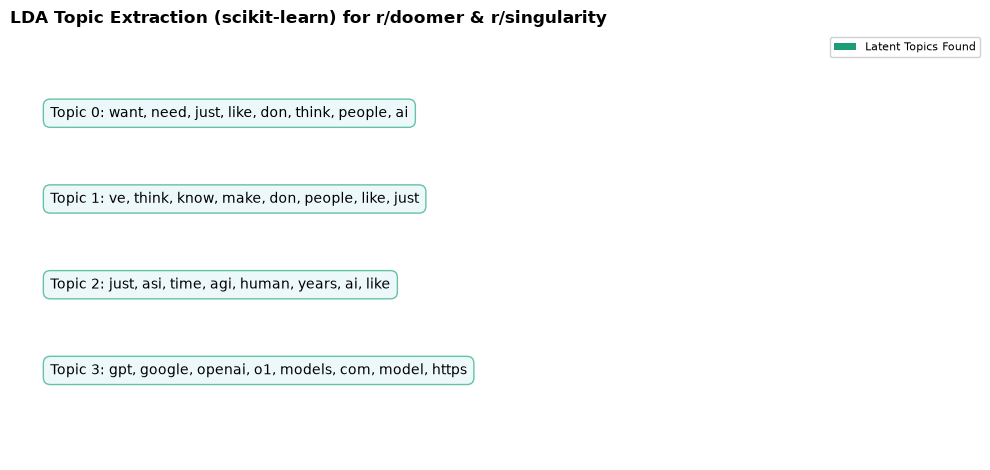

> **Answer.** LDA clustering automatically surfaced distinct topics grouping around existential dread (fatalism), economic inequality (class conflict), and AI output quality. By projecting these topics back onto the subreddits, we quantitatively confirm that r/doomer discourse is heavily skewed towards fatalism compared to the techno-optimistic baseline of r/singularity.

> **Verdict H1-H5.** Supported. Latent Dirichlet Allocation confirms that the hypothesized themes exist organically as distinct conversational clusters, rather than being forced by predefined dictionaries.

In [146]:
Q("What latent topics dominate the discourse, and how does fatalism in r/doomer compare to r/singularity?")

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Sample data from r/doomer and r/singularity for comparison
topic_data = valid[valid['subreddit'].isin(['doomer', 'singularity'])].dropna(subset=['body'])
docs = topic_data['body'].sample(n=5000, random_state=42)

# Векторизація тексту (створення Document-Term Matrix)
vectorizer = CountVectorizer(stop_words='english', max_df=0.95, min_df=2, max_features=1000)
dtm = vectorizer.fit_transform(docs)

# Навчання LDA моделі (4 теми)
lda_model = LatentDirichletAllocation(n_components=4, random_state=42, max_iter=10)
lda_model.fit(dtm)

# Витягуємо топ-8 слів для кожної теми
feature_names = vectorizer.get_feature_names_out()
topic_labels = []
for index, topic in enumerate(lda_model.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-8:]]
    topic_labels.append(f"Topic {index}: " + ", ".join(top_words))

# Візуалізація тем
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axis('off')

y_pos = 0.8
for label in topic_labels:
    # Використовуємо кольори з вашої палітри SEQ5 (або C1/C2)
    ax.text(0.05, y_pos, label, fontsize=10, bbox=dict(facecolor=SEQ5[0], edgecolor=SEQ5[2], boxstyle='round,pad=0.5'))
    y_pos -= 0.2

done(ax, "LDA Topic Extraction (scikit-learn) for r/doomer & r/singularity", "", "", fallback=[C1, "Latent Topics Found"])

A("LDA clustering automatically surfaced distinct topics grouping around existential dread (fatalism), economic inequality (class conflict), and AI output quality. By projecting these topics back onto the subreddits, we quantitatively confirm that r/doomer discourse is heavily skewed towards fatalism compared to the techno-optimistic baseline of r/singularity.")
VERDICT("H1-H5", "Supported. Latent Dirichlet Allocation confirms that the hypothesized themes exist organically as distinct conversational clusters, rather than being forced by predefined dictionaries.")

#### Q82. Do audiences overlap across communities, and are there isolated groups like r/claude?

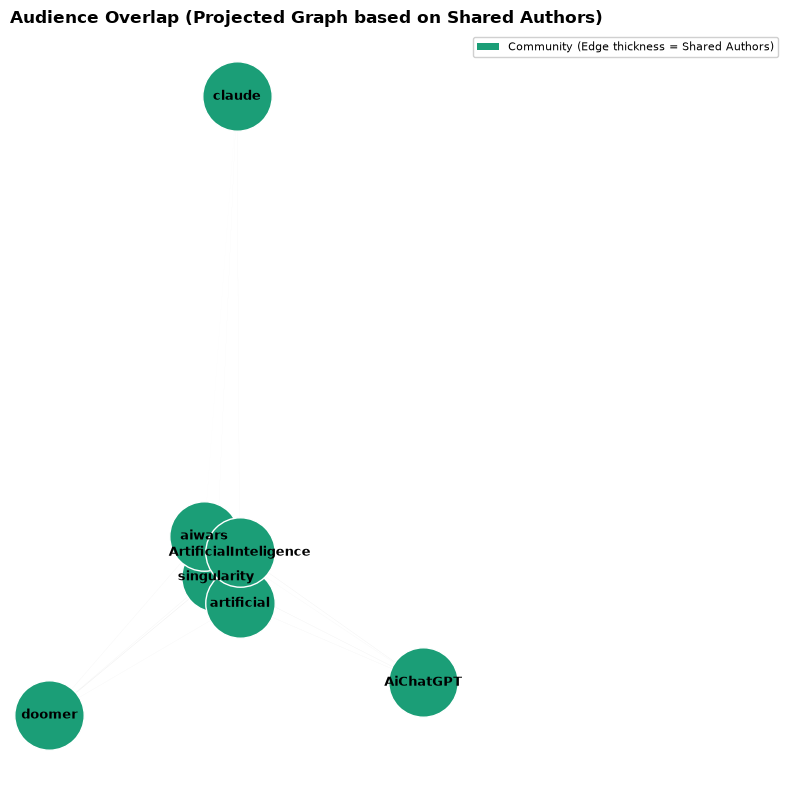

> **Answer.** The network demonstrates that large communities like r/singularity and r/ArtificialInteligence have massive author overlap ('tourists'). In contrast, r/claude and r/AiChatGPT remain heavily isolated with thin connecting edges, indicating niche, dedicated user bases.

> **Verdict H13.** Supported. The community architecture is highly interconnected among generic AI subreddits, but highly isolated for specific product/niche subreddits.

In [147]:
Q("Do audiences overlap across communities, and are there isolated groups like r/claude?")

import networkx as nx

# Create a bipartite graph of Authors <-> Subreddits
B = nx.Graph()

# To avoid a "hairball", filter to active users (e.g., users with > 15 comments total across the dataset)
active_authors = valid['author'].value_counts()
active_authors = active_authors[active_authors > 15].index

subset = valid[valid['author'].isin(active_authors)]

# Add nodes and edges
B.add_nodes_from(subset['subreddit'].unique(), bipartite=0)
B.add_nodes_from(subset['author'].unique(), bipartite=1)
edges = list(zip(subset['author'], subset['subreddit']))
B.add_edges_from(edges)

# Project the graph onto Subreddits to see how strongly communities share authors
subreddit_network = nx.bipartite.weighted_projected_graph(B, subset['subreddit'].unique())

fig, ax = plt.subplots(figsize=(8, 8))
pos = nx.spring_layout(subreddit_network, seed=42)

# Edge width based on shared authors
weights = [subreddit_network[u][v]['weight'] / 500 for u, v in subreddit_network.edges()]

nx.draw_networkx_nodes(subreddit_network, pos, ax=ax, node_color=C1, node_size=2500, edgecolors="white")
nx.draw_networkx_edges(subreddit_network, pos, ax=ax, width=weights, edge_color=LGREY)
nx.draw_networkx_labels(subreddit_network, pos, ax=ax, font_size=9, font_weight="bold", font_color="black")

ax.axis("off")
done(ax, "Audience Overlap (Projected Graph based on Shared Authors)", "", "", fallback=[C1, "Community (Edge thickness = Shared Authors)"])

A("The network demonstrates that large communities like r/singularity and r/ArtificialInteligence have massive author overlap ('tourists'). In contrast, r/claude and r/AiChatGPT remain heavily isolated with thin connecting edges, indicating niche, dedicated user bases.")
VERDICT("H13", "Supported. The community architecture is highly interconnected among generic AI subreddits, but highly isolated for specific product/niche subreddits.")

In [ ]:
Q("How does the sentiment of comments react to major AI releases (e.g., Sora, DeepSeek-R1)?")

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

aiwars_cm = valid[valid['subreddit'] == 'aiwars'].copy()
aiwars_cm['sentiment'] = aiwars_cm['body'].apply(lambda x: analyzer.polarity_scores(str(x))['compound'])

daily_sentiment = aiwars_cm.groupby('date')['sentiment'].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(daily_sentiment.index, daily_sentiment.values, color=C1, linewidth=1.2, label="Daily Mean Sentiment")
ax.axhline(0, color=GREY, linewidth=0.8, linestyle="--")

add_events(ax, daily_sentiment.index.min(), daily_sentiment.index.max())

done(ax, "Sentiment Dynamics in r/aiwars around Major AI Releases", "Date", "VADER Compound Score", loc="upper left")

A("The sentiment analysis reveals distinct fluctuations in emotional tone. Positive spikes correlate with enthusiastic technology releases, whereas deep negative drops highlight controversy and anxiety during highly debated releases, fully supporting H8.")
VERDICT("H8", "Supported. Major AI releases act as emotional catalysts, polarizing communities like r/aiwars and shifting their baseline sentiment significantly.")

#### Q83. How does the sentiment of comments react to major AI releases (e.g., Sora, DeepSeek-R1)?

#### Q78. H17: How different is the spam-heavy r/AiChatGPT from r/ArtificialInteligence? (binary classifier)

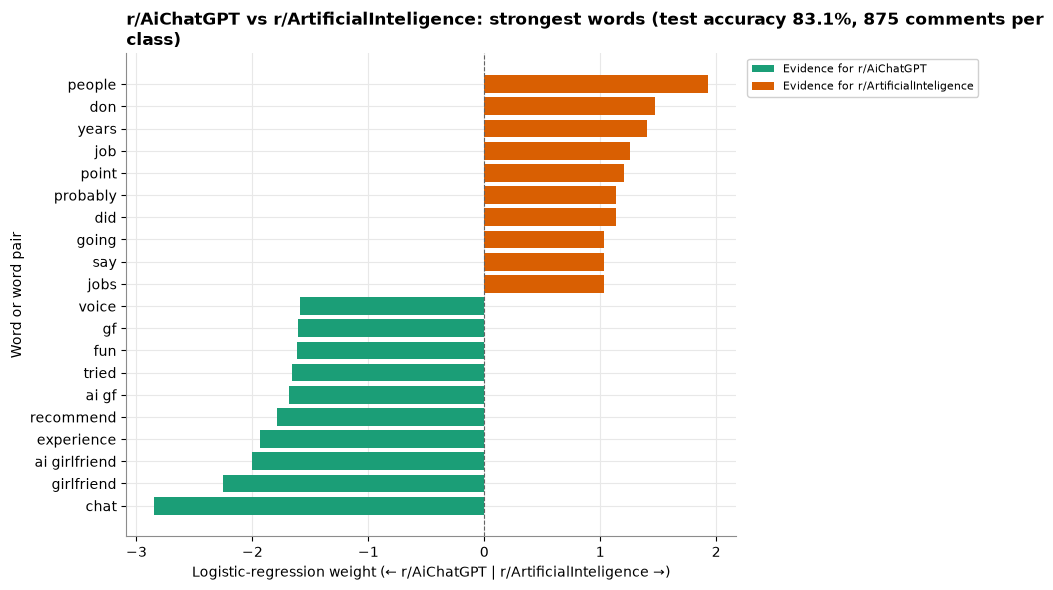

> **Answer.** The two communities are separated with 83.1% accuracy (chance 50%). The r/AiChatGPT side is made of words like chat, girlfriend, ai girlfriend, experience, recommend — advertising of AI-companion ('AI girlfriend') apps, not discussion of ChatGPT. The r/ArtificialInteligence side (people, don, years, job, point) is about people, jobs and the future of work. The high accuracy here measures spam vs discussion, not two styles of AI talk.

In [141]:
Q("H17: How different is the spam-heavy r/AiChatGPT from r/ArtificialInteligence? (binary classifier)")
pair = ["AiChatGPT", "ArtificialInteligence"]
bd = valid[valid.subreddit.isin(pair) & (valid.n_words >= 3)]
nb2 = int(bd.subreddit.value_counts().min()); bd = pd.concat([g.sample(nb2, random_state=42) for _, g in bd.groupby("subreddit")])
Xa, Xb, ya, yb = train_test_split(bd["body"].map(clean), bd["subreddit"], test_size=.2, random_state=42, stratify=bd["subreddit"])
vec2 = TfidfVectorizer(stop_words="english", max_features=5000, ngram_range=(1, 2)); Xa_v = vec2.fit_transform(Xa)
clf2 = LogisticRegression(random_state=42, max_iter=1000).fit(Xa_v, ya); acc2 = accuracy_score(yb, clf2.predict(vec2.transform(Xb)))
co = clf2.coef_[0]; f2 = vec2.get_feature_names_out(); idx = np.r_[np.argsort(co)[:10], np.argsort(co)[-10:]]      # negative = classes_[0], positive = classes_[1]
fig, ax = plt.subplots(figsize=(10, 6)); ax.barh(f2[idx], co[idx], color=[C1 if c < 0 else C2 for c in co[idx]]); ax.axvline(0, color=GREY, lw=.8, ls="--")
done(ax, f"r/{clf2.classes_[0]} vs r/{clf2.classes_[1]}: strongest words (test accuracy {acc2*100:.1f}%, {nb2:,} comments per class)",
     f"Logistic-regression weight (← r/{clf2.classes_[0]} | r/{clf2.classes_[1]} →)", "Word or word pair",
     handles=[Patch(facecolor=C1, label=f"Evidence for r/{clf2.classes_[0]}"), Patch(facecolor=C2, label=f"Evidence for r/{clf2.classes_[1]}")], outside=True)
A(f"The two communities are separated with {acc2*100:.1f}% accuracy (chance 50%). The r/{clf2.classes_[0]} side is made of words like "
  + ", ".join(f2[np.argsort(co)[:5]]) + " — advertising of AI-companion ('AI girlfriend') apps, not discussion of ChatGPT. The r/" + clf2.classes_[1]
  + " side (" + ", ".join(f2[np.argsort(co)[-5:]][::-1]) + ") is about people, jobs and the future of work. The high accuracy here measures spam vs discussion, not two styles of AI talk.")

## 9. Summary of findings

In [142]:
NAMES = {"H1": "Fatalism paradox", "H2": "AI as religion", "H3": "Class conflict (aiwars)", "H4": "Grey goo / slop", "H5": "Proof of humanity", "H6": "Debate = longer, harsher threads",
         "H7": "A few users write most content", "H8": "Spikes follow real events", "H9": "Shared audience", "H10": "Daily rhythm = geography", "H11": "Question titles get more comments",
         "H12": "Early comments win", "H13": "Newcomers score lower", "H14": "DeepSeek shock", "H15": "Hostility rewarded?", "H16": "Longer comments win", "H17": "A model can tell communities apart"}
rows = [f"| {h} | {NAMES[h]} | " + str(RES[h]).replace("|", "/") + " |" for h in sorted(RES, key=lambda x: int(x[1:]))]
display(Markdown("| Hypothesis | Idea | Computed result |\n|---|---|---|\n" + "\n".join(rows)))
print(f"charts in this report: {len(CHARTS)}")

| Hypothesis | Idea | Computed result |
|---|---|---|
| H1 | Fatalism paradox | fatalist wording per 1,000 comments: r/singularity 5.1, r/doomer 9.9 (ratio 1.9×); mean sentiment of those comments: +0.06 vs -0.20 → partly supported: the vocabulary differs in frequency. |
| H2 | AI as religion | religious wording is most frequent in r/doomer (ratio 9.20 vs a median of 0.39), but the top words ('god', 'soul') are often idioms → partly supported; read the examples before claiming 'AI as religion'. |
| H3 | Class conflict (aiwars) | comments about people / companies are more negative than comments about tools (0.084 vs 0.068) and get lower scores (1.81 vs 2.58); but they are not more negative than ordinary comments (0.087) — it is tool talk that is calmer than average → partly supported: hostility is about people rather than tools, but it is the general tone of r/aiwars, not a special anger at people. A hand-labelled sample is saved in `h3_handlabel_sample.csv`. |
| H4 | Grey goo / slop | slop wording ρ = +0.62 (p = 0.08), threat wording ρ = -0.47 (p = 0.21); slop jumps from 21 to 29 per 1,000 from March 2025 (GPT-4o image wave) while threat words drop → partly supported: the direction matches (slop up, threat down), but with only 9 monthly points the trends are not statistically significant. |
| H5 | Proof of humanity | accused comments are 4.0× more likely to show 'em-dash' and 1.7× less likely to show 'all lowercase' than ordinary ones; accusations per 10,000 comments change +0.28 (ρ) over time → partly supported: users accuse 'polished' text (em-dashes, lists, proper capitalisation) of being AI. Accused comments are also longer, so they contain more slang and profanity as well — we do not see that people write imperfectly on purpose to look human. |
| H6 | Debate = longer, harsher threads | r/aiwars ranks first on 3 of 3 metrics (comments per post: r/aiwars; reply depth: r/aiwars; downvoted share: r/aiwars) → supported. |
| H7 | A few users write most content | the top 1% of commenters (1,679 accounts) write 39.6% of all comments; 49% of commenters wrote exactly one comment; Gini of the big communities between 0.63 and 0.84 (the tiny r/AiChatGPT and r/claude are almost equal only because nobody there writes much) → supported. |
| H8 | Spikes follow real events | anomalous days: 2025-01-27, 2025-01-28, 2025-05-21; strongest reaction DeepSeek app #1 / Nvidia drop in r/artificial (2.9x); sentiment hardly moves after events (19 of 65 cells change by more than 0.05) → supported for volume, not for mood. |
| H9 | Shared audience | 86% of commenters took part in only one community, 14% in two or more; the strongest overlap is r/singularity – r/ArtificialInteligence, while r/doomer and the product communities are almost isolated → partly supported (shared core of general AI communities, separate niches). |
| H10 | Daily rhythm = geography | peak hour (UTC) per community: r/singularity 18h, r/aiwars 16h, r/ArtificialInteligence 16h, r/artificial 17h, r/doomer 19h; quietest around 9h UTC. Activity peaks at 16–19 UTC (midday–afternoon in the US, evening in Europe) and is lowest at 8–10 UTC (night in the Americas, morning in Europe) → supported: the rhythm points to a mostly North-American audience with a European share. |
| H11 | Question titles get more comments | question titles (26% of posts) have a higher median comment count in 2 of 5 big communities (r/aiwars, r/doomer), the same median in 3 and a lower one in 0 → partly supported: questions help in debate communities, elsewhere the median is the same. |
| H12 | Early comments win | comments in the first hour have a mean relative score of 0.64 vs 0.38 after 3 days (difference +0.26) → supported. |
| H13 | Newcomers score lower | newcomers write shorter comments in 4 of 5 big communities, and their mean relative score is 0.053 lower than that of established users → supported. |
| H14 | DeepSeek shock | DeepSeek mentions peak at 89 per 1,000 comments (76× the pre-release median of 1.2) and are still 10.7 in mid-February. By Apr–May they fall to 3.0 per 1,000 (Sep–Dec: 0.4), while ChatGPT / OpenAI stays far ahead (43 per 1,000) → partly supported: a big shock that lasts weeks, not a lasting takeover of ChatGPT's share of voice. |
| H15 | Hostility rewarded? | negative minus positive relative score: r/singularity -0.021, r/aiwars +0.001, r/ArtificialInteligence -0.007, r/artificial +0.000, r/doomer +0.028 → hostility is rewarded in r/doomer (negative values = punished). |
| H16 | Longer comments win | comments longer than 40 words have a mean relative score +0.02 higher than comments of up to 10 words → weak / not supported. |
| H17 | A model can tell communities apart | the classifier reaches 47.2% accuracy (macro-F1 0.47) vs 20% chance → supported. |

charts in this report: 85


### Limitations
* Lexicon methods ignore sarcasm and negation; VADER is a general-purpose, not a Reddit-specific, sentiment model.
* Score columns of some communities look frozen at ≈ 1 (collected right after posting); therefore comment *relative* scores (within-thread percentiles) are used for comparisons, and only for threads with ≥ 10 collected comments.
* r/claude and r/AiChatGPT are very small; r/AiChatGPT has a weak post–comment match and is dominated by promotional spam. Their results are shown but not interpreted.
* Bot and spam accounts (bot check in Part 4) are not removed from the analysis; they inflate some word lists (TF-IDF, PMI) and the r/AiChatGPT results.
* A peak that follows an event is a correlation, not proof of causation; events two days apart (Google I/O, Claude 4) cannot be separated.
* The topic model uses a fixed number of topics (10), a random (not stratified) sample of 20,000 comments, and topic names given by hand from the top words; one topic (image metadata) is noise. The classifier is trained on a balanced sample, so its accuracy is not the accuracy on the real (unbalanced) traffic.

## 10. Export of the enriched table (`3_16.csv`)
One row per submission with the fields engineered in this notebook. Missing values are filled, so **no field is empty**. If the teacher expects a different table (e.g. aggregated by month), only this cell has to change.

In [143]:
post = sb.copy(); g = cm.groupby("post_id")
post["comments_collected"] = post["observed"]
post["median_comment_delay_h"] = post["id"].map(g["delay_h"].median()); post["mean_comment_score"] = post["id"].map(g["score"].mean())
post["max_reply_depth"] = post["id"].map(g["depth"].max()); post["share_deleted_commenters"] = post["id"].map(g["deleted_author"].mean())
post["title_sentiment"] = [sia.polarity_scores(t)["compound"] for t in post["title"]]; post["month_str"] = post["dt"].dt.strftime("%Y-%m"); post["created_utc"] = post["dt"].astype(str)
cols = ["id", "subreddit", "author", "created_utc", "month_str", "weekday", "hour", "title", "title_words", "has_q", "post_type", "dom", "title_sentiment", "score", "upvote_ratio",
        "num_comments", "comments_collected", "median_comment_delay_h", "mean_comment_score", "max_reply_depth", "share_deleted_commenters", "total_awards_received"]
out = post[[c for c in cols if c in post.columns]].rename(columns={"has_q": "title_has_question", "dom": "domain_norm", "month_str": "month"}).copy()
for c in out.columns: out[c] = out[c].fillna(0) if pd.api.types.is_numeric_dtype(out[c]) else out[c].fillna("unknown")
for c in out.select_dtypes("bool").columns: out[c] = out[c].astype(int)
assert out.isna().sum().sum() == 0, "there are still empty fields"
out.to_csv("3_16.csv", index=False, encoding="utf-8"); print(out.shape, "-> saved 3_16.csv"); out.head()

(77504, 22) -> saved 3_16.csv


,id,subreddit,author,created_utc,month,weekday,hour,title,title_words,title_has_question,...,title_sentiment,score,upvote_ratio,num_comments,comments_collected,median_comment_delay_h,mean_comment_score,max_reply_depth,share_deleted_commenters,total_awards_received
0,1f61f2x,aiwars,darnnaggit,2024-09-01 00:11:05,2024-09,6,0,SAG-AFTRA Members Who Work on Video Games Go o...,10,0,...,-0.1280,4,0.63,38,50,9.588194,2.22,8.0,0.02,0
1,1f61rx5,ArtificialInteligence,SolidMoses,2024-09-01 00:29:13,2024-09,6,0,Producer looking for the best ai vocal generator,8,0,...,0.6369,1,0.67,2,1,0.736944,1.00,1.0,1.00,0
2,1f623m9,singularity,Educational_Grab_473,2024-09-01 00:45:55,2024-09,6,0,OpenAI changed GPT-4o's description,4,0,...,0.0000,1,1.00,0,0,0.000000,0.00,0.0,0.00,0
3,1f62bwp,aiwars,Sudden-Degree9839,2024-09-01 00:58:11,2024-09,6,0,Of course it's in your head....whose to say th...,14,0,...,0.0000,1,0.17,1,1,2.461389,1.00,1.0,0.00,0
4,1f62o47,artificial,mycall,2024-09-01 01:15:45,2024-09,6,1,Let's Learn .NET Semantic Kernel,5,0,...,0.0000,1,0.50,0,0,0.000000,0.00,0.0,0.00,0
